# Graph Neural Networks from scratch: the math, message passing, and every major architecture

Images live on a grid, text lives on a sequence, but a lot of the world's data is a **graph**: molecules (atoms + bonds), citation networks (papers + citations), social networks, road networks, knowledge graphs, meshes, recommender systems (users + items). A Graph Neural Network (GNN) is a neural network that consumes a graph directly and respects its structure.

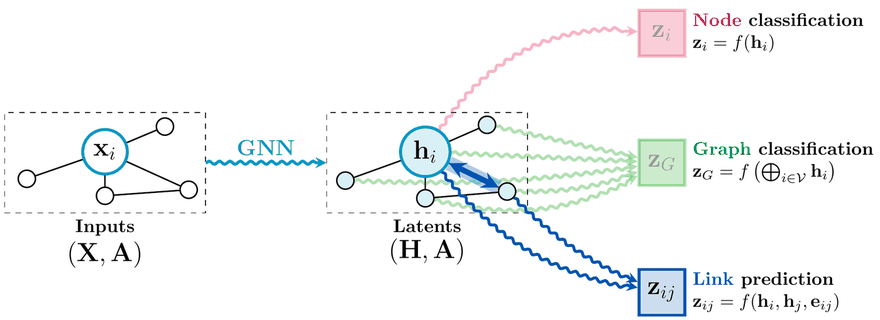

***The big picture.** A GNN maps an input graph (node features $X$, adjacency $A$) to latent node representations $H$ on the same graph. From $H$ we make predictions per **node** ($z_i = f(h_i)$), per **graph** (pool every $h_i$), or per **edge** ($z_{ij} = f(h_i, h_j, e_{ij})$). Those are the three task levels of Parts 5, 7 and 8. Source: [Veličković, *Everything is Connected: Graph Neural Networks*, Current Opinion in Structural Biology 2023](https://arxiv.org/abs/2301.08210).*


In this notebook we build GNNs completely from scratch in **pure PyTorch** (no PyTorch Geometric / DGL). Every layer, every scatter operation, the graph mini-batching, the datasets loaders, and the training loops are written by hand. Along the way we derive the math and check every derivation numerically.

We will build things in this order:

1. **Graphs as data**: adjacency matrices, `edge_index`, degrees, self-loops, and the permutation symmetry every GNN must respect
2. **Spectral graph theory**: the graph Laplacian, its quadratic form, the graph Fourier transform, spectral filters, ChebNet, and the full derivation of the GCN layer
3. **Message passing**: the spatial view, gather/scatter mechanics, a general `MessagePassing` base class, and what different aggregators can and cannot distinguish
4. **Architectures**: GCN, GraphSAGE, GAT (and GATv2), GIN, and the Weisfeiler-Lehman test that bounds their power
5. **Node classification on Cora**: MLP vs GCN vs GraphSAGE vs GAT
6. **Over-smoothing**: why deep GNNs fail, explained through the spectrum
7. **Graph classification on MUTAG**: batching many graphs, readout/pooling, GIN vs GCN
8. **Link prediction**: edge-level tasks, negative sampling, and avoiding leakage
9. **Graph Transformers**: the Transformer is a GNN on a complete graph; positional encodings for graphs; a GPS-style layer
10. **Summary / cheat sheet**

### References

* Kipf & Welling, *Semi-Supervised Classification with Graph Convolutional Networks* (GCN): https://arxiv.org/abs/1609.02907
* Defferrard et al., *Convolutional Neural Networks on Graphs with Fast Localized Spectral Filtering* (ChebNet): https://arxiv.org/abs/1606.09375
* Bruna et al., *Spectral Networks and Locally Connected Networks on Graphs*: https://arxiv.org/abs/1312.6203
* Gilmer et al., *Neural Message Passing for Quantum Chemistry* (MPNN): https://arxiv.org/abs/1704.01212
* Hamilton et al., *Inductive Representation Learning on Large Graphs* (GraphSAGE): https://arxiv.org/abs/1706.02216
* Veličković et al., *Graph Attention Networks* (GAT): https://arxiv.org/abs/1710.10903
* Brody et al., *How Attentive are Graph Attention Networks?* (GATv2): https://arxiv.org/abs/2105.14491
* Xu et al., *How Powerful are Graph Neural Networks?* (GIN): https://arxiv.org/abs/1810.00826
* Li et al., *Deeper Insights into Graph Convolutional Networks* (over-smoothing): https://arxiv.org/abs/1801.07606
* Wu et al., *Simplifying Graph Convolutional Networks* (SGC): https://arxiv.org/abs/1902.07153
* Dwivedi & Bresson, *A Generalization of Transformer Networks to Graphs*: https://arxiv.org/abs/2012.09699
* Rampášek et al., *Recipe for a General, Powerful, Scalable Graph Transformer* (GPS): https://arxiv.org/abs/2205.12454
* Bronstein et al., *Geometric Deep Learning* (book): https://arxiv.org/abs/2104.13478
* Distill, *A Gentle Introduction to Graph Neural Networks*: https://distill.pub/2021/gnn-intro/
* Distill, *Understanding Convolutions on Graphs*: https://distill.pub/2021/understanding-gnns/
* Stanford CS224W, *Machine Learning with Graphs*: http://web.stanford.edu/class/cs224w/

In [1]:
import math
import json
import random
import tarfile
import urllib.request
from pathlib import Path
from dataclasses import dataclass
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx


def set_seed(seed: int = 0):
    # Make every experiment in this notebook reproducible
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
torch.set_printoptions(precision=3, sci_mode=False)

# Graphs in this notebook are small, so CPU is plenty.
# Note: scatter_reduce coverage on MPS is incomplete, so we only switch to CUDA if present.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Datasets are downloaded here (pytorch/datasets/ is git-ignored)
DATA_DIR = Path("datasets/graphs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"torch {torch.__version__}, device={device}")

torch 2.7.1, device=cpu


# Notation

We use the same symbols throughout the notebook:

| Symbol | Meaning | Shape |
|---|---|---|
| $G = (V, E)$ | a graph with node set $V$ and edge set $E$ | |
| $N = \lvert V \rvert$ | number of nodes | scalar |
| $E = \lvert E \rvert$ | number of (directed) edges, i.e. columns of `edge_index` | scalar |
| $A$ | adjacency matrix, $A_{ij} = 1$ if there is an edge between $i$ and $j$ | $(N, N)$ |
| $D$ | degree matrix, diagonal with $D_{ii} = d_i = \sum_j A_{ij}$ | $(N, N)$ |
| $L = D - A$ | (combinatorial) graph Laplacian | $(N, N)$ |
| $\tilde{A} = A + I$, $\tilde{D}$ | adjacency / degree **with self-loops** | $(N, N)$ |
| $\hat{A} = \tilde{D}^{-1/2}\tilde{A}\tilde{D}^{-1/2}$ | GCN's normalized adjacency | $(N, N)$ |
| $X$ | input node features, row $i$ is $x_i$ | $(N, F)$ |
| $H^{(l)}$ | node representations after layer $l$, row $i$ is $h_i^{(l)}$ | $(N, F_l)$ |
| $W^{(l)}$ | learnable weight matrix of layer $l$ | $(F_l, F_{l+1})$ |
| $\mathcal{N}(i)$ | neighbours of node $i$ | set |
| $j \rightarrow i$ | an edge **from source $j$ to target $i$**: $j$ sends a message, $i$ receives it | |
| $P$ | a permutation matrix (relabelling of nodes) | $(N, N)$ |

# Part 1: Graphs as data

### Why do we need a new kind of neural network?

Every architecture we have built so far bakes in an assumption (an *inductive bias*) about the structure of its input:

| Architecture | Input structure | Built-in symmetry |
|---|---|---|
| MLP | fixed-length vector | none: input position $k$ always means the same thing |
| CNN | regular grid (image) | translation equivariance: shift the image, the feature map shifts |
| RNN / LSTM | ordered sequence | time-step weight sharing |
| Transformer | set of tokens (+ positional encodings) | permutation equivariance over tokens |
| **GNN** | **graph** | **permutation equivariance over nodes, and sparsity given by the edges** |

A graph breaks all the assumptions of an MLP/CNN/RNN:

* **There is no canonical node order.** The same molecule can be written down with its atoms numbered in $N!$ different ways. The model must give the same answer for all of them.
* **Neighbourhoods have variable size.** In a CNN every pixel has exactly 8 neighbours; in a citation graph one paper is cited once and another 168 times.
* **There is no global coordinate system.** "Left of" or "the next token" do not exist; only "connected to" does.

A GNN solves this with one idea: **every node updates its representation by aggregating information from its neighbours, using the same shared function everywhere**. That is *message passing*, and the rest of the notebook is about the different ways to do it, why they work, and what their limits are.

Below is a tiny 6-node graph we will use throughout to make every operation concrete: two triangles $\{0,1,2\}$ and $\{3,4,5\}$ joined by a single "bridge" edge $2-3$.

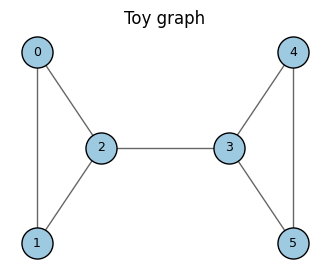

In [2]:
# A toy undirected graph: two triangles joined by the bridge (2, 3)
toy_edges = [(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)]
toy_num_nodes = 6


def draw_graph(edge_index, num_nodes, node_color=None, ax=None, pos=None, labels=True,
               cmap="coolwarm", node_size=500, title=None, vmin=None, vmax=None, edge_alpha=0.6):
    # Small helper around networkx for drawing an edge_index graph
    g = nx.Graph()
    g.add_nodes_from(range(num_nodes))
    g.add_edges_from(edge_index.t().tolist())
    if pos is None:
        pos = nx.spring_layout(g, seed=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    if node_color is None:
        node_color, cmap = "#9ecae1", None
    nx.draw_networkx_edges(g, pos, ax=ax, alpha=edge_alpha)
    nodes = nx.draw_networkx_nodes(g, pos, ax=ax, node_color=node_color, cmap=cmap,
                                   node_size=node_size, vmin=vmin, vmax=vmax, edgecolors="black")
    if labels:
        nx.draw_networkx_labels(g, pos, ax=ax, font_size=9)
    if title:
        ax.set_title(title)
    ax.axis("off")
    return pos, nodes


# Fixed layout so every picture of the toy graph looks the same
toy_pos = {0: (-2, 0.6), 1: (-2, -0.6), 2: (-1, 0), 3: (1, 0), 4: (2, 0.6), 5: (2, -0.6)}
_ = draw_graph(torch.tensor(toy_edges).t(), toy_num_nodes, pos=toy_pos, title="Toy graph")
plt.show()

## Representation 1: the adjacency matrix

The most mathematical way to store a graph is the **adjacency matrix** $A \in \{0,1\}^{N \times N}$:

$$
A_{ij} = \begin{cases} 1 & \text{if there is an edge between } i \text{ and } j \\ 0 & \text{otherwise} \end{cases}
$$

For an undirected graph $A$ is **symmetric** ($A = A^\top$). Weighted graphs simply store the weight instead of 1. Everything in spectral graph theory (Part 2) is linear algebra on this matrix.

The problem is memory: $A$ has $N^2$ entries, but real graphs are **sparse**: the number of edges grows roughly linearly with $N$, not quadratically. Cora (Part 5) has 2,708 nodes, so $A$ has 7.3 million entries, of which only about 10,500 are non-zero (0.14%).

## Representation 2: `edge_index` (COO format)

So in practice every GNN library stores a graph as a list of edges, a tensor of shape $(2, E)$ called `edge_index`:

```
edge_index = [[ j_0, j_1, j_2, ... ],   # row 0: source nodes  (who sends the message)
              [ i_0, i_1, i_2, ... ]]   # row 1: target nodes  (who receives the message)
```

Conventions we follow (same as PyTorch Geometric):

* column $e$ is a **directed** edge $j \rightarrow i$ with $j$ = `edge_index[0, e]` and $i$ = `edge_index[1, e]`.
* an **undirected** edge is stored **twice**, once in each direction. So our toy graph with 7 undirected edges has $E = 14$ columns.
* memory is $O(E)$ instead of $O(N^2)$, and, as we'll see in Part 3, message passing becomes two indexing operations on this tensor.

In [3]:
def to_undirected(edge_index: torch.Tensor, num_nodes: int) -> torch.Tensor:
    # Add the reverse of every edge and remove duplicates
    # Shape: (2, E) -> (2, 2E) -> (2, E_unique)
    reversed_edges = edge_index.flip(0)
    edge_index = torch.cat([edge_index, reversed_edges], dim=1)
    # Encode each edge (j, i) as a unique integer j * N + i so we can deduplicate with torch.unique
    edge_ids = edge_index[0] * num_nodes + edge_index[1]
    edge_ids = torch.unique(edge_ids)  # sorted, unique
    return torch.stack([edge_ids // num_nodes, edge_ids % num_nodes], dim=0)


def edge_index_to_adjacency(edge_index: torch.Tensor, num_nodes: int, edge_weight=None) -> torch.Tensor:
    # Scatter ones (or weights) into a dense (N, N) matrix: A[i, j] = 1 for each edge j -> i
    # For undirected graphs the result is symmetric, so the convention does not matter.
    if edge_weight is None:
        edge_weight = torch.ones(edge_index.size(1))
    adjacency = torch.zeros(num_nodes, num_nodes)
    adjacency[edge_index[1], edge_index[0]] = edge_weight
    return adjacency


def adjacency_to_edge_index(adjacency: torch.Tensor) -> torch.Tensor:
    # A[i, j] = 1 means j -> i, so the nonzeros of A^T are (source=j, target=i) pairs.
    # nonzero() returns them sorted by source, then target, the same order to_undirected produces.
    # Shape: (N, N) -> (2, num_nonzero)
    source, target = adjacency.t().nonzero(as_tuple=True)
    return torch.stack([source, target], dim=0)


# Build the toy graph's edge_index from the list of undirected edges
toy_edge_index = to_undirected(torch.tensor(toy_edges).t(), toy_num_nodes)
print("edge_index (2, E):")
print(toy_edge_index)
print(f"E = {toy_edge_index.size(1)} directed edges for {len(toy_edges)} undirected edges\n")

A_toy = edge_index_to_adjacency(toy_edge_index, toy_num_nodes)
print("Adjacency matrix A:")
print(A_toy)
print("Symmetric:", torch.equal(A_toy, A_toy.T))
print("Round trip adjacency -> edge_index matches:", torch.equal(adjacency_to_edge_index(A_toy), toy_edge_index))

edge_index (2, E):
tensor([[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5],
        [1, 2, 0, 2, 0, 1, 3, 2, 4, 5, 3, 5, 3, 4]])
E = 14 directed edges for 7 undirected edges

Adjacency matrix A:
tensor([[0., 1., 1., 0., 0., 0.],
        [1., 0., 1., 0., 0., 0.],
        [1., 1., 0., 1., 0., 0.],
        [0., 0., 1., 0., 1., 1.],
        [0., 0., 0., 1., 0., 1.],
        [0., 0., 0., 1., 1., 0.]])
Symmetric: True
Round trip adjacency -> edge_index matches: True


## Degree

The **degree** of node $i$ is the number of neighbours it has:

$$
d_i = \sum_{j} A_{ij} \qquad D = \operatorname{diag}(d_1, \ldots, d_N)
$$

With `edge_index` this is just counting how many times each node appears as a target, which is a single `bincount`. Degrees show up everywhere: in normalisation (GCN), in mean aggregation (GraphSAGE), and in the Laplacian.

## Self-loops

A **self-loop** is an edge $i \rightarrow i$. Many GNN layers add self-loops so that when a node aggregates over its neighbourhood, **its own features are included** in the aggregation. In matrix form this is $\tilde{A} = A + I$. We will see in Part 2 that this innocent-looking trick is also a crucial *spectral* fix that keeps GCNs numerically stable.

In [4]:
def degree(index: torch.Tensor, num_nodes: int, dtype=torch.float) -> torch.Tensor:
    # Count how many edges point INTO each node (pass edge_index[1])
    # Shape: (E,) -> (N,)
    return torch.bincount(index, minlength=num_nodes).to(dtype)


def remove_self_loops(edge_index: torch.Tensor) -> torch.Tensor:
    # Keep only the edges where source != target
    mask = edge_index[0] != edge_index[1]
    return edge_index[:, mask]


def add_self_loops(edge_index: torch.Tensor, num_nodes: int) -> torch.Tensor:
    # Append the edges (i, i) for every node. Remove existing ones first so none are duplicated.
    # Shape: (2, E) -> (2, E + N)
    edge_index = remove_self_loops(edge_index)
    loops = torch.arange(num_nodes).unsqueeze(0).repeat(2, 1)
    return torch.cat([edge_index, loops], dim=1)


toy_deg = degree(toy_edge_index[1], toy_num_nodes)
print("degrees from edge_index :", toy_deg)
print("degrees from A.sum(1)   :", A_toy.sum(1))
toy_edge_index_sl = add_self_loops(toy_edge_index, toy_num_nodes)
print(f"edges with self loops: {toy_edge_index_sl.size(1)} = {toy_edge_index.size(1)} + {toy_num_nodes}")
print("A + I equals adjacency built from the self-loop edge_index:",
      torch.equal(edge_index_to_adjacency(toy_edge_index_sl, toy_num_nodes), A_toy + torch.eye(toy_num_nodes)))

degrees from edge_index : tensor([2., 2., 3., 3., 2., 2.])
degrees from A.sum(1)   : tensor([2., 2., 3., 3., 2., 2.])
edges with self loops: 20 = 14 + 6
A + I equals adjacency built from the self-loop edge_index: True


## Node features and the three levels of graph tasks

On top of the structure, each node carries a feature vector $x_i \in \mathbb{R}^F$, stacked into the **feature matrix** $X \in \mathbb{R}^{N \times F}$ (a word histogram of a paper, the one-hot atom type of an atom, the profile of a user). Edges can carry features too (bond type), and so can the whole graph.

A GNN turns $(X, A)$ into node embeddings $H \in \mathbb{R}^{N \times d}$. What we do with them depends on the task:

| Task level | Question | Example | How to get a prediction from $H$ |
|---|---|---|---|
| **Node** | what is node $i$? | topic of a paper in a citation graph (Part 5) | a classifier on $h_i$ |
| **Edge** | does edge $(i,j)$ exist / what type is it? | "will these two users become friends?" (Part 8) | a score $s(h_i, h_j)$, e.g. $h_i^\top h_j$ |
| **Graph** | what is the whole graph? | is this molecule mutagenic? (Part 7) | a *readout* $h_G = \text{pool}(\{h_i\})$, then a classifier |

## Permutation invariance and equivariance: the single most important constraint

Node IDs are arbitrary. If I relabel the nodes, I have the same graph. A relabelling is described by a **permutation matrix** $P$ (an identity matrix with its rows shuffled, so $P^\top P = I$). Under a relabelling:

$$
X \;\longrightarrow\; P X \qquad\qquad A \;\longrightarrow\; P A P^\top
$$

($PX$ shuffles the rows of $X$; $PAP^\top$ shuffles both rows and columns of $A$ the same way.)

Two properties follow:

* A **graph-level** function $f$ must be **permutation invariant**: the output must not change at all.
$$ f(PX, PAP^\top) = f(X, A) $$
* A **node-level** function $F$ (one output row per node) must be **permutation equivariant**: the output rows get shuffled in exactly the same way as the input.
$$ F(PX, PAP^\top) = P\,F(X, A) $$

**Claim: the basic GNN layer $F(X, A) = A X W$ is permutation equivariant.** Proof:

$$
F(PX, PAP^\top) = (PAP^\top)(PX)W = PA\underbrace{(P^\top P)}_{=I}XW = P\,(AXW) = P\,F(X, A) \qquad \blacksquare
$$

and any **sum (or mean, or max) over nodes** is permutation invariant because addition is commutative. So: *equivariant layers followed by an invariant readout* gives an invariant graph-level model. That is the blueprint of every model in this notebook.

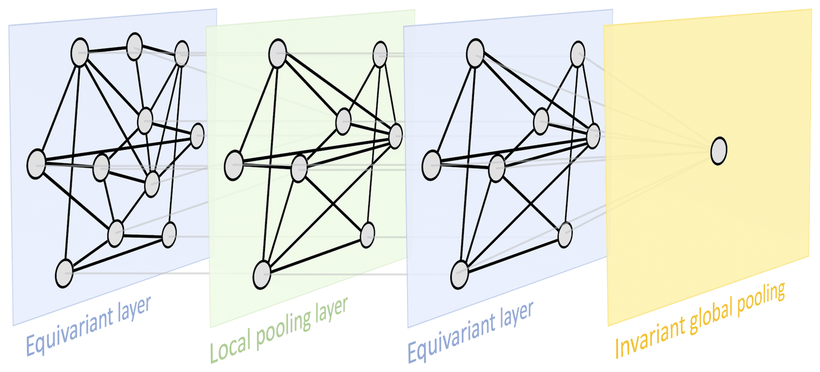

***The geometric deep learning blueprint.** Stack **permutation-equivariant** layers (each node's output moves with the node when we relabel), optionally coarsen the graph with local pooling, and finish with a **permutation-invariant** global pooling for graph-level outputs. Every model in this notebook follows this template. Source: [Bronstein, Bruna, Cohen & Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, 2021](https://arxiv.org/abs/2104.13478).*


**Why not just flatten $A$ and feed it to an MLP?** Because an MLP assigns a different weight to every input position, so relabelling the nodes changes the output. To learn invariance it would have to see all $N!$ orderings. Let's verify all three statements numerically.

In [5]:
set_seed(0)
num_feats = 3
X_toy = torch.randn(toy_num_nodes, num_feats)  # (N, F)
W = torch.randn(num_feats, 2)                   # (F, F_out)

# Random relabelling of the nodes as a permutation matrix
perm = torch.randperm(toy_num_nodes)
P = torch.eye(toy_num_nodes)[perm]              # (N, N), rows of I shuffled

X_perm = P @ X_toy                              # shuffle the rows of X
A_perm = P @ A_toy @ P.T                        # shuffle rows and columns of A


def gnn_layer(X, A):
    # F(X, A) = A X W  -- (N, N) @ (N, F) @ (F, F_out) -> (N, F_out)
    return A @ X @ W


def graph_readout(X, A):
    # Equivariant layer followed by a sum over nodes: (N, F_out) -> (F_out,)
    return gnn_layer(X, A).sum(dim=0)


mlp_on_flat_adjacency = nn.Linear(toy_num_nodes * toy_num_nodes, 2)

print("Equivariance  F(PX, PAP^T) == P F(X, A):",
      torch.allclose(gnn_layer(X_perm, A_perm), P @ gnn_layer(X_toy, A_toy), atol=1e-6))
print("Invariance    f(PX, PAP^T) == f(X, A):  ",
      torch.allclose(graph_readout(X_perm, A_perm), graph_readout(X_toy, A_toy), atol=1e-6))
with torch.no_grad():
    out_original = mlp_on_flat_adjacency(A_toy.flatten())
    out_permuted = mlp_on_flat_adjacency(A_perm.flatten())
print("MLP on flattened A is invariant:        ", torch.allclose(out_original, out_permuted, atol=1e-6))
print("   MLP(A)        =", out_original)
print("   MLP(P A P^T)  =", out_permuted)

Equivariance  F(PX, PAP^T) == P F(X, A): True
Invariance    f(PX, PAP^T) == f(X, A):   True
MLP on flattened A is invariant:         False
   MLP(A)        = tensor([ 0.186, -0.276])
   MLP(P A P^T)  = tensor([0.035, 0.080])


# Part 2: Spectral graph theory, the math underneath GNNs

The first GNNs were not invented as "message passing". They came from asking: **what does convolution mean on a graph?** On images, convolution is easy to define because every pixel has the same neighbourhood shape. On a graph there is no such shape. The answer comes from the **convolution theorem**: convolution is multiplication in the Fourier domain. So if we can define a Fourier transform on a graph, we can define convolution. The object that gives us a Fourier transform is the **graph Laplacian**.

This part is the theory behind *why* the GCN layer $\hat{A} H W$ looks the way it does. We will derive it step by step.

## The graph Laplacian

$$
L = D - A
$$

Written out entry by entry:

$$
L_{ij} = \begin{cases} d_i & i = j \\ -1 & i \neq j \text{ and } (i, j) \in E \\ 0 & \text{otherwise} \end{cases}
$$

Applying $L$ to a signal $x \in \mathbb{R}^N$ (one number per node) gives

$$
(Lx)_i = d_i x_i - \sum_{j \in \mathcal{N}(i)} x_j = \sum_{j \in \mathcal{N}(i)} (x_i - x_j)
$$

so $(Lx)_i$ measures **how different node $i$ is from its neighbours**. It is the graph analogue of the (negative) second derivative $-\frac{d^2}{dt^2}$: on a path graph, $(Lx)_i = 2x_i - x_{i-1} - x_{i+1}$, which is exactly the finite-difference stencil for $-x''$.

In [6]:
def laplacian(edge_index: torch.Tensor, num_nodes: int) -> torch.Tensor:
    # L = D - A  (dense, fine for small graphs)
    A = edge_index_to_adjacency(edge_index, num_nodes)
    D = torch.diag(A.sum(dim=1))
    return D - A


L_toy = laplacian(toy_edge_index, toy_num_nodes)
print("L = D - A:")
print(L_toy)
print("Row sums (always 0 because d_i = sum_j A_ij):", L_toy.sum(1))

L = D - A:
tensor([[ 2., -1., -1.,  0.,  0.,  0.],
        [-1.,  2., -1.,  0.,  0.,  0.],
        [-1., -1.,  3., -1.,  0.,  0.],
        [ 0.,  0., -1.,  3., -1., -1.],
        [ 0.,  0.,  0., -1.,  2., -1.],
        [ 0.,  0.,  0., -1., -1.,  2.]])
Row sums (always 0 because d_i = sum_j A_ij): tensor([0., 0., 0., 0., 0., 0.])


## The quadratic form: $L$ measures smoothness

The single most important identity in spectral graph theory. For any signal $x \in \mathbb{R}^N$:

$$
x^\top L x = \sum_{(i,j) \in E_{\text{undirected}}} (x_i - x_j)^2
$$

**Derivation.** Expand $L = D - A$:

$$
x^\top L x = x^\top D x - x^\top A x = \sum_i d_i x_i^2 - \sum_{i,j} A_{ij} x_i x_j
$$

Use $d_i = \sum_j A_{ij}$ to rewrite the first term, then split it in half and use the symmetry $A_{ij} = A_{ji}$ to swap the indices on one of the halves:

$$
\sum_i d_i x_i^2 = \sum_{i,j} A_{ij} x_i^2 = \tfrac{1}{2}\sum_{i,j} A_{ij} x_i^2 + \tfrac{1}{2}\sum_{i,j} A_{ij} x_j^2
$$

Put it back together:

$$
x^\top L x = \tfrac{1}{2}\sum_{i,j} A_{ij}\left(x_i^2 - 2x_i x_j + x_j^2\right) = \tfrac{1}{2}\sum_{i,j} A_{ij}(x_i - x_j)^2 = \sum_{(i,j) \in E_{\text{undirected}}} (x_i - x_j)^2 \qquad \blacksquare
$$

(the $\tfrac12$ disappears because the double sum counts every undirected edge twice).

This quantity is called the **Dirichlet energy** of $x$. It is small when connected nodes have similar values (a *smooth* signal) and large when neighbours disagree (a *rough* signal). Three consequences we will use over and over:

1. **$L$ is positive semi-definite**: $x^\top L x \geq 0$ because it is a sum of squares. So all eigenvalues of $L$ are $\geq 0$.
2. **The constant vector is an eigenvector with eigenvalue 0**: $L\mathbf{1} = 0$ since every row of $L$ sums to zero.
3. **The number of zero eigenvalues equals the number of connected components**: $x^\top L x = 0$ forces $x_i = x_j$ across every edge, i.e. $x$ is constant on each connected component, and there is one independent such vector per component.

x^T L x               = 35.0038
sum over edges (xi-xj)^2 = 35.0038

Dirichlet energy of a smooth signal: 3.28
Dirichlet energy of a rough signal:  20.00


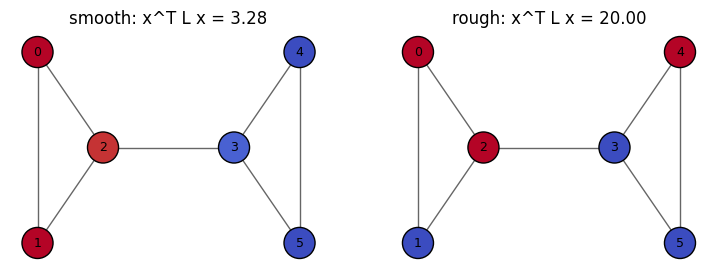

eigenvalues with the bridge:    tensor([    -0.000,      0.438,      3.000,      3.000,      3.000,      4.562])
eigenvalues without the bridge: tensor([0., 0., 3., 3., 3., 3.])


In [7]:
def dirichlet_energy_edges(x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
    # Sum of squared differences over directed edges, halved because each undirected edge appears twice
    # Works for x of shape (N,) or (N, F) (summed over features)
    diff = x[edge_index[0]] - x[edge_index[1]]
    return 0.5 * (diff ** 2).sum()


set_seed(0)
x = torch.randn(toy_num_nodes)
print(f"x^T L x               = {x @ L_toy @ x:.4f}")
print(f"sum over edges (xi-xj)^2 = {dirichlet_energy_edges(x, toy_edge_index):.4f}")

smooth = torch.tensor([1.0, 1.0, 0.9, -0.9, -1.0, -1.0])   # agrees within each triangle
rough = torch.tensor([1.0, -1.0, 1.0, -1.0, 1.0, -1.0])    # flips sign along many edges
print(f"\nDirichlet energy of a smooth signal: {smooth @ L_toy @ smooth:.2f}")
print(f"Dirichlet energy of a rough signal:  {rough @ L_toy @ rough:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
draw_graph(toy_edge_index, toy_num_nodes, node_color=smooth, ax=axes[0], pos=toy_pos, vmin=-1, vmax=1,
           title=f"smooth: x^T L x = {smooth @ L_toy @ smooth:.2f}")
draw_graph(toy_edge_index, toy_num_nodes, node_color=rough, ax=axes[1], pos=toy_pos, vmin=-1, vmax=1,
           title=f"rough: x^T L x = {rough @ L_toy @ rough:.2f}")
plt.show()

# Connected components <-> zero eigenvalues: remove the bridge (2, 3) and we get two components
two_triangles = to_undirected(torch.tensor([(0, 1), (0, 2), (1, 2), (3, 4), (3, 5), (4, 5)]).t(), 6)
print("eigenvalues with the bridge:   ", torch.linalg.eigvalsh(L_toy))
print("eigenvalues without the bridge:", torch.linalg.eigvalsh(laplacian(two_triangles, 6)))

## Normalized Laplacians

$L$'s eigenvalues scale with the node degrees, which is a problem when degrees vary a lot (a hub with 100 neighbours dominates). Two normalized versions fix this:

$$
L_{\text{sym}} = D^{-1/2} L D^{-1/2} = I - D^{-1/2} A D^{-1/2} \qquad\qquad L_{\text{rw}} = D^{-1} L = I - D^{-1}A
$$

* $L_{\text{sym}}$ is **symmetric**, so it has real eigenvalues and orthonormal eigenvectors. This is the one used by ChebNet and GCN.
* $L_{\text{rw}}$ is related to random walks: $D^{-1}A$ is the transition matrix of a random walk on the graph (row $i$ is a uniform distribution over $i$'s neighbours). It has the same eigenvalues as $L_{\text{sym}}$.

The quadratic form of $L_{\text{sym}}$ is the Dirichlet energy of the **degree-rescaled** signal:

$$
x^\top L_{\text{sym}} x = \sum_{(i,j) \in E} \left(\frac{x_i}{\sqrt{d_i}} - \frac{x_j}{\sqrt{d_j}}\right)^2
$$

**The eigenvalues of $L_{\text{sym}}$ lie in $[0, 2]$.** The lower bound is the sum of squares again. For the upper bound, use $(a-b)^2 \leq 2a^2 + 2b^2$ on each edge:

$$
x^\top L_{\text{sym}} x \leq \sum_{(i,j) \in E} \left(\frac{2x_i^2}{d_i} + \frac{2x_j^2}{d_j}\right) = 2\sum_i \frac{x_i^2}{d_i} \cdot d_i = 2\, x^\top x
$$

(each node $i$ appears in exactly $d_i$ edges). By the Rayleigh quotient, every eigenvalue is at most 2, with equality only for bipartite graphs. This bounded range is what makes Chebyshev polynomials (which live on $[-1,1]$) usable.

In [8]:
def normalized_laplacian(edge_index: torch.Tensor, num_nodes: int) -> torch.Tensor:
    # L_sym = I - D^{-1/2} A D^{-1/2}
    A = edge_index_to_adjacency(edge_index, num_nodes)
    deg = A.sum(dim=1)
    deg_inv_sqrt = deg.pow(-0.5)
    deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0  # isolated nodes have degree 0
    # D^{-1/2} A D^{-1/2} as broadcasting: scale row i by d_i^{-1/2} and column j by d_j^{-1/2}
    A_norm = deg_inv_sqrt.unsqueeze(1) * A * deg_inv_sqrt.unsqueeze(0)
    return torch.eye(num_nodes) - A_norm


L_sym_toy = normalized_laplacian(toy_edge_index, toy_num_nodes)
D_inv = torch.diag(1 / toy_deg)
L_rw_toy = torch.eye(toy_num_nodes) - D_inv @ A_toy
print("eigenvalues of L_sym:", torch.linalg.eigvalsh(L_sym_toy))
print("eigenvalues of L_rw: ", torch.linalg.eigvals(L_rw_toy).real.sort().values)

# A bipartite graph (a 6-cycle) reaches the upper bound of 2
cycle6 = to_undirected(torch.tensor([(i, (i + 1) % 6) for i in range(6)]).t(), 6)
print("eigenvalues of L_sym for a 6-cycle (bipartite):", torch.linalg.eigvalsh(normalized_laplacian(cycle6, 6)))

eigenvalues of L_sym: tensor([    0.000,     0.205,     1.167,     1.500,     1.500,     1.629])
eigenvalues of L_rw:  tensor([0.000, 0.205, 1.167, 1.500, 1.500, 1.629])
eigenvalues of L_sym for a 6-cycle (bipartite): tensor([    0.000,     0.500,     0.500,     1.500,     1.500,     2.000])


## The graph Fourier transform

Because $L$ (or $L_{\text{sym}}$) is real and symmetric, the spectral theorem gives an eigendecomposition with orthonormal eigenvectors:

$$
L = U \Lambda U^\top \qquad U = [u_1, \ldots, u_N],\;\; U^\top U = I, \qquad \Lambda = \operatorname{diag}(\lambda_1 \leq \lambda_2 \leq \ldots \leq \lambda_N)
$$

The eigenvectors form a basis for signals on the graph. The **graph Fourier transform** expresses a signal in this basis:

$$
\hat{x} = U^\top x \quad \text{(forward)} \qquad\qquad x = U \hat{x} = \sum_k \hat{x}_k u_k \quad \text{(inverse)}
$$

**Why call it "Fourier"?** Look at the energy of an eigenvector:

$$
u_k^\top L u_k = u_k^\top (\lambda_k u_k) = \lambda_k \quad\Longrightarrow\quad \lambda_k = \sum_{(i,j)\in E}\big(u_k(i) - u_k(j)\big)^2
$$

**The eigenvalue is the roughness of its eigenvector.** Small $\lambda$ means a slowly varying eigenvector (a low frequency); large $\lambda$ means it oscillates across edges (a high frequency). And on a **cycle graph** (the graph version of a periodic 1-D signal) the eigenvectors of $L$ are *exactly* the sines and cosines of the classical discrete Fourier transform. Let's check that.

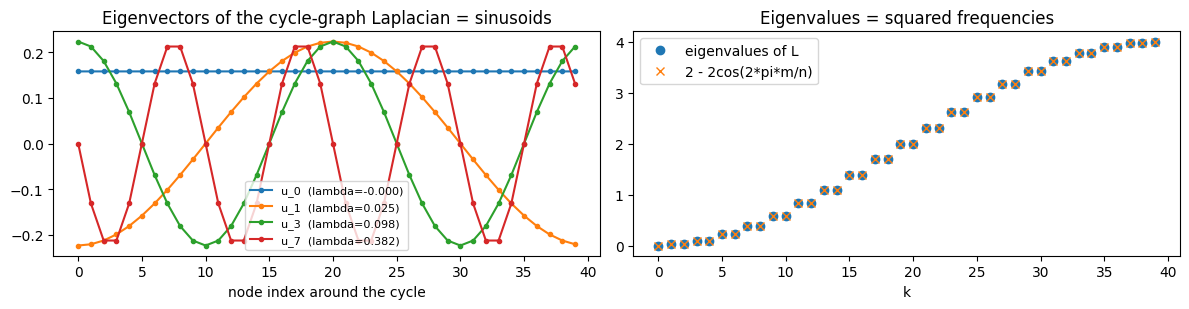

max |eigenvalue - theory| = 7.152557373046875e-07


In [9]:
# Eigenvectors of a 40-node cycle graph are the classical Fourier modes
n_cycle = 40
cycle = to_undirected(torch.tensor([(i, (i + 1) % n_cycle) for i in range(n_cycle)]).t(), n_cycle)
eigvals, eigvecs = torch.linalg.eigh(laplacian(cycle, n_cycle))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for k in [0, 1, 3, 7]:
    axes[0].plot(eigvecs[:, k], marker=".", label=f"u_{k}  (lambda={eigvals[k]:.3f})")
axes[0].set_title("Eigenvectors of the cycle-graph Laplacian = sinusoids")
axes[0].set_xlabel("node index around the cycle")
axes[0].legend(fontsize=8)

# Theory for the cycle: lambda = 2 - 2cos(2 pi m / n), the DFT frequencies
m = torch.arange(n_cycle)
theory = (2 - 2 * torch.cos(2 * math.pi * m / n_cycle)).sort().values
axes[1].plot(eigvals, "o", label="eigenvalues of L")
axes[1].plot(theory, "x", label="2 - 2cos(2*pi*m/n)")
axes[1].set_title("Eigenvalues = squared frequencies")
axes[1].set_xlabel("k")
axes[1].legend()
plt.tight_layout()
plt.show()
print("max |eigenvalue - theory| =", (eigvals - theory).abs().max().item())

## Eigenvectors of a real graph: Zachary's karate club

The karate club graph (34 members of a university karate club, edges = friendships outside the club) is the classic small social network. The club famously split into two after a dispute between the instructor (node 0, "Mr. Hi") and the administrator (node 33, "Officer").

Below we draw a few eigenvectors of $L_{\text{sym}}$ as node colours. $u_1$ is (degree-weighted) constant, $u_2$ is smooth, and the high-index ones flip sign between neighbours. $u_2$ is the famous **Fiedler vector**: the smoothest non-trivial signal on the graph. Because it changes slowly along edges, it changes sign where there are few edges, which means **its sign splits the graph into two communities** (spectral clustering in one line). Let's see how well it recovers the real split of the club, without any learning.

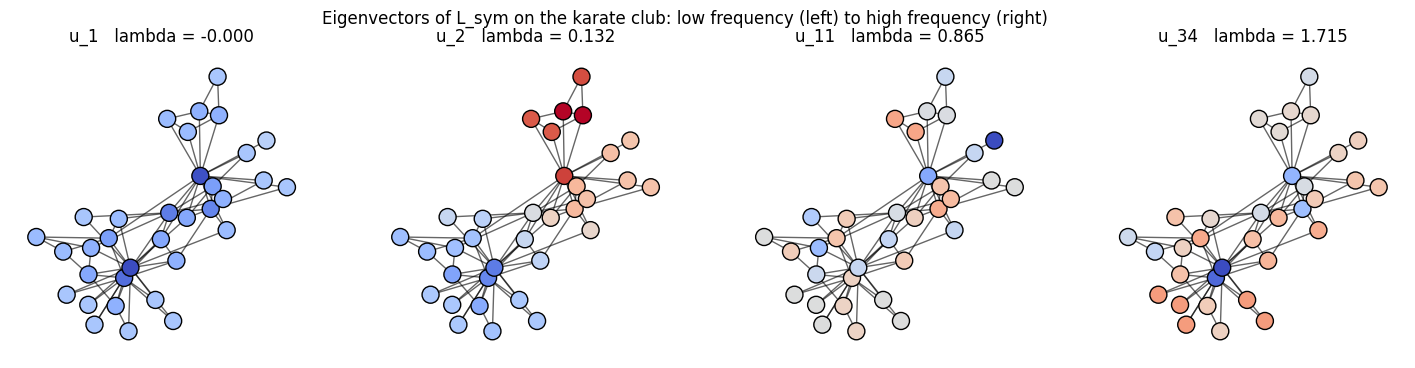

Sign of the Fiedler vector matches the real club split for 94% of members


In [10]:
karate = nx.karate_club_graph()
karate_num_nodes = karate.number_of_nodes()
karate_edge_index = to_undirected(torch.tensor(list(karate.edges())).t(), karate_num_nodes)
karate_labels = torch.tensor([0 if karate.nodes[i]["club"] == "Mr. Hi" else 1 for i in range(karate_num_nodes)])
karate_pos = nx.spring_layout(karate, seed=3)

L_sym_karate = normalized_laplacian(karate_edge_index, karate_num_nodes)
karate_eigvals, karate_eigvecs = torch.linalg.eigh(L_sym_karate)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, [0, 1, 10, 33]):
    vec = karate_eigvecs[:, k]
    lim = vec.abs().max()
    draw_graph(karate_edge_index, karate_num_nodes, node_color=vec, ax=ax, pos=karate_pos,
               labels=False, node_size=150, vmin=-lim, vmax=lim,
               title=f"u_{k + 1}   lambda = {karate_eigvals[k]:.3f}")
plt.suptitle("Eigenvectors of L_sym on the karate club: low frequency (left) to high frequency (right)")
plt.show()

fiedler = karate_eigvecs[:, 1]
pred = (fiedler > 0).long()
agreement = max((pred == karate_labels).float().mean(), (pred != karate_labels).float().mean())
print(f"Sign of the Fiedler vector matches the real club split for {agreement:.0%} of members")

## Spectral filtering = convolution on graphs

The **convolution theorem** says convolution in the signal domain is element-wise multiplication in the frequency domain. We take that as the *definition* of convolution on a graph. A spectral filter $g$ is a function of frequency $\lambda$, and filtering a signal $x$ means:

$$
y = g_\theta \star x = U\, g_\theta(\Lambda)\, U^\top x
$$

Read right to left: (1) transform to the frequency domain with $U^\top x$, (2) scale frequency $k$ by $g_\theta(\lambda_k)$, (3) transform back with $U$.

A **low-pass** filter keeps small $\lambda$ (smooth components) and kills large $\lambda$ (noise). A classical choice is the heat kernel $g(\lambda) = e^{-\tau \lambda}$. Below we create a noisy signal on the karate club (the true club label plus heavy noise) and denoise it with a low-pass filter. The same principle explains why GCNs work on graphs where **neighbours tend to share labels** (homophily): the GCN is a learned low-pass filter.

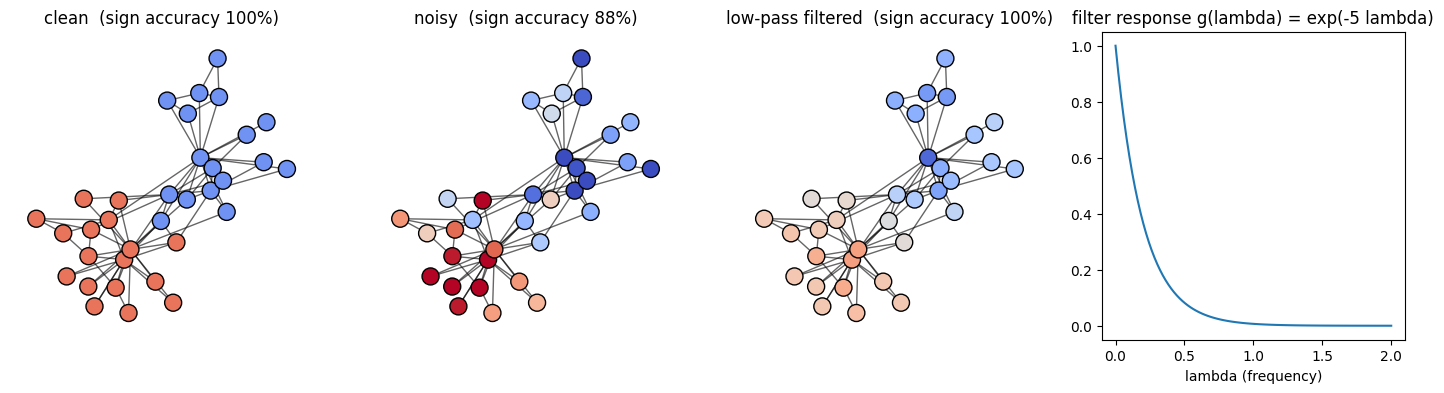

In [11]:
set_seed(0)
clean_signal = karate_labels.float() * 2 - 1                    # +1 / -1 club membership
noisy_signal = clean_signal + 1.0 * torch.randn(karate_num_nodes)


def spectral_filter(x, eigvecs, eigvals, g):
    # y = U g(Lambda) U^T x
    x_hat = eigvecs.T @ x                # graph Fourier transform, (N,)
    y_hat = g(eigvals) * x_hat           # scale each frequency, (N,)
    return eigvecs @ y_hat               # inverse transform, (N,)


low_pass = lambda lam: torch.exp(-5.0 * lam)
filtered = spectral_filter(noisy_signal, karate_eigvecs, karate_eigvals, low_pass)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, sig, name in zip(axes[:3], [clean_signal, noisy_signal, filtered], ["clean", "noisy", "low-pass filtered"]):
    acc = ((sig > 0).long() == karate_labels).float().mean()
    draw_graph(karate_edge_index, karate_num_nodes, node_color=sig, ax=ax, pos=karate_pos, labels=False,
               node_size=150, vmin=-1.5, vmax=1.5, title=f"{name}  (sign accuracy {acc:.0%})")
lam_grid = torch.linspace(0, 2, 100)
axes[3].plot(lam_grid, low_pass(lam_grid))
axes[3].set_title("filter response g(lambda) = exp(-5 lambda)")
axes[3].set_xlabel("lambda (frequency)")
plt.show()

## The first spectral GNN, and why it was impractical

Bruna et al. (2014) made the filter learnable: one free parameter per frequency, $g_\theta(\Lambda) = \operatorname{diag}(\theta_1, \ldots, \theta_N)$. This works in principle, but:

1. **Cost**: computing $U$ is an $O(N^3)$ eigendecomposition, and every forward pass multiplies by dense $N \times N$ matrices, $O(N^2)$.
2. **Not localized**: a free-form $g_\theta(\Lambda)$ gives a dense $U g_\theta(\Lambda) U^\top$, so every node's output depends on every other node, unlike a CNN's small kernel.
3. **Not transferable**: the parameters are tied to *this graph's* eigenbasis $U$. A different graph (another molecule) has a different $U$, so the learned filter means nothing there.
4. **$O(N)$ parameters**, growing with the graph.

## Polynomial filters are localized and need no eigendecomposition

The fix is to restrict the filter to a **polynomial** of degree $K$ in $\lambda$:

$$
g_\theta(\Lambda) = \sum_{k=0}^{K} \theta_k \Lambda^k \quad\Longrightarrow\quad U g_\theta(\Lambda) U^\top = \sum_{k=0}^{K} \theta_k U \Lambda^k U^\top = \sum_{k=0}^{K} \theta_k L^k
$$

(using $L^k = U\Lambda^k U^\top$, because $U^\top U = I$). This changes everything:

* **No eigendecomposition**: $\sum_k \theta_k L^k x$ is just repeated multiplication by the sparse matrix $L$, $O(K \lvert E \rvert)$.
* **$K$-hop localized**: $(L^k)_{ij} = 0$ whenever the shortest path between $i$ and $j$ is longer than $k$ (by induction: $L$ only connects neighbours, so each multiplication extends the reach by one hop). A degree-$K$ filter is a "kernel of radius $K$", exactly like a CNN kernel.
* **$K+1$ parameters**, independent of $N$, and they **transfer to any graph** because they are defined through $L$, not through a specific $U$.

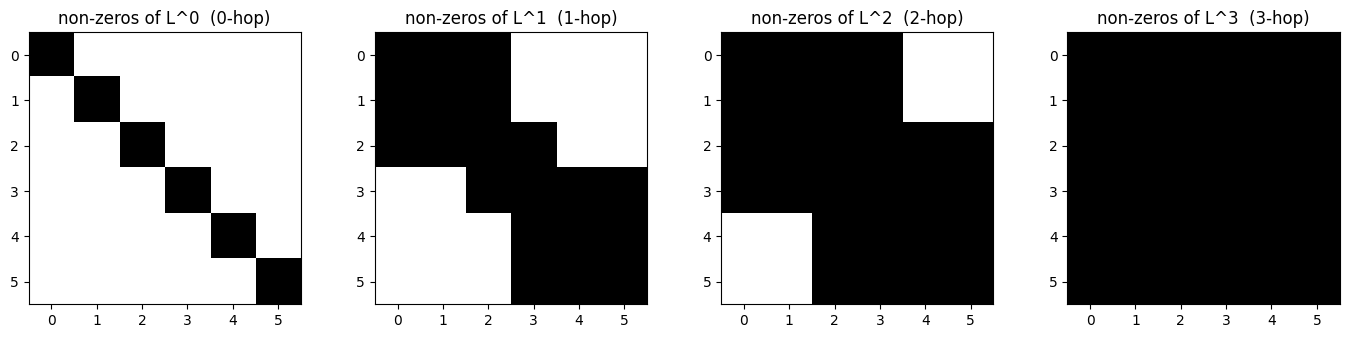

In [12]:
# Sparsity pattern of L^k on the toy graph grows one hop at a time
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
Lk = torch.eye(toy_num_nodes)
for k, ax in enumerate(axes):
    ax.imshow((Lk.abs() > 1e-9).float(), cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"non-zeros of L^{k}  ({k}-hop)")
    ax.set_xticks(range(toy_num_nodes))
    ax.set_yticks(range(toy_num_nodes))
    Lk = Lk @ L_toy
plt.tight_layout()
plt.show()

## ChebNet: Chebyshev polynomial filters

The monomial basis $1, \lambda, \lambda^2, \ldots$ is numerically unstable (the powers get large and become nearly collinear). Defferrard et al. (2016) use **Chebyshev polynomials** instead, which form an orthogonal basis on $[-1, 1]$ and are defined by a recurrence:

$$
T_0(x) = 1, \qquad T_1(x) = x, \qquad T_k(x) = 2x\,T_{k-1}(x) - T_{k-2}(x)
$$

Since the eigenvalues of $L_{\text{sym}}$ are in $[0, \lambda_{\max}] \subseteq [0, 2]$, we first rescale them into $[-1, 1]$:

$$
\tilde{L} = \frac{2}{\lambda_{\max}} L_{\text{sym}} - I
$$

and the filter becomes

$$
y = \sum_{k=0}^{K} \theta_k\, T_k(\tilde{L})\, x
$$

**We never form $T_k(\tilde{L})$.** We apply the recurrence to the signal itself: $\bar{x}_0 = x$, $\bar{x}_1 = \tilde{L}x$, $\bar{x}_k = 2\tilde{L}\bar{x}_{k-1} - \bar{x}_{k-2}$, then $y = \sum_k \theta_k \bar{x}_k$. That is $K$ sparse matrix-vector products.

For a layer with $F_{in}$ input channels and $F_{out}$ output channels each $\theta_k$ becomes a weight matrix $\Theta_k \in \mathbb{R}^{F_{in} \times F_{out}}$:

$$
H' = \sum_{k=0}^{K} T_k(\tilde{L})\, H\, \Theta_k
$$

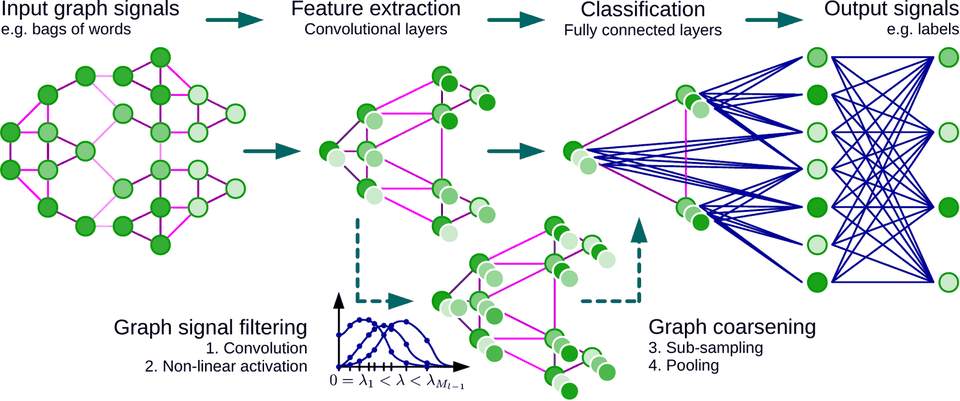

***ChebNet, a CNN for graphs.** Graph signal filtering is the spectral convolution with Chebyshev filters (the small plot shows filter responses over the eigenvalues $\lambda$), graph coarsening plays the role of pooling, and fully connected layers classify. GCN keeps the filtering idea with $K=1$; in Part 7 we replace the coarsening with a global readout. Source: [Defferrard, Bresson & Vandergheynst, *Convolutional Neural Networks on Graphs with Fast Localized Spectral Filtering*, NeurIPS 2016](https://arxiv.org/abs/1606.09375).*


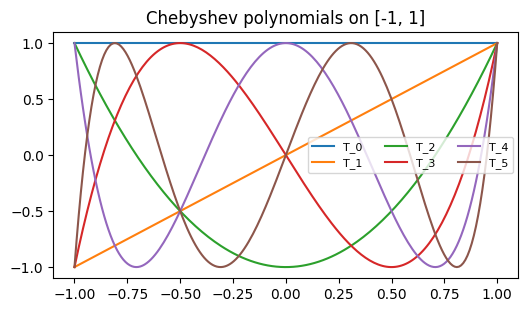

In [13]:
x_grid = torch.linspace(-1, 1, 200)
T = [torch.ones_like(x_grid), x_grid]
for k in range(2, 6):
    T.append(2 * x_grid * T[-1] - T[-2])
plt.figure(figsize=(6, 3.2))
for k, Tk in enumerate(T):
    plt.plot(x_grid, Tk, label=f"T_{k}")
plt.title("Chebyshev polynomials on [-1, 1]")
plt.legend(ncol=3, fontsize=8)
plt.show()

In [14]:
class ChebConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, K: int):
        # K is the polynomial degree, so the filter sees K hops
        super().__init__()
        self.K = K
        # One weight matrix Theta_k per Chebyshev order k = 0..K
        self.thetas = nn.ModuleList([nn.Linear(in_channels, out_channels, bias=False) for _ in range(K + 1)])
        self.bias = nn.Parameter(torch.zeros(out_channels))

    @staticmethod
    def scaled_laplacian(edge_index, num_nodes, lambda_max=None):
        # L_tilde = 2 L_sym / lambda_max - I, eigenvalues in [-1, 1]
        L_sym = normalized_laplacian(edge_index, num_nodes)
        if lambda_max is None:
            lambda_max = torch.linalg.eigvalsh(L_sym).max()
        return 2.0 * L_sym / lambda_max - torch.eye(num_nodes)

    def forward(self, x: torch.Tensor, L_tilde: torch.Tensor) -> torch.Tensor:
        # x: (N, F_in), L_tilde: (N, N) (dense here for clarity; a sparse matmul works the same way)
        # Chebyshev recurrence applied to the features, never to the matrix
        x_bar_prev = x                                      # T_0(L~) x = x            (N, F_in)
        out = self.thetas[0](x_bar_prev)                    # (N, F_out)
        if self.K >= 1:
            x_bar = L_tilde @ x                             # T_1(L~) x = L~ x         (N, F_in)
            out = out + self.thetas[1](x_bar)
            for k in range(2, self.K + 1):
                x_bar_next = 2 * (L_tilde @ x_bar) - x_bar_prev  # T_k = 2 L~ T_{k-1} - T_{k-2}
                out = out + self.thetas[k](x_bar_next)
                x_bar_prev, x_bar = x_bar, x_bar_next
        return out + self.bias


# Numerical check: ChebConv (vertex domain) == spectral filter U g(Lambda) U^T x with g = sum_k theta_k T_k
set_seed(0)
K = 3
cheb = ChebConv(in_channels=1, out_channels=1, K=K)
lambda_max = karate_eigvals.max()
L_tilde_karate = ChebConv.scaled_laplacian(karate_edge_index, karate_num_nodes, lambda_max)
x = torch.randn(karate_num_nodes, 1)

with torch.no_grad():
    vertex_domain = cheb(x, L_tilde_karate) - cheb.bias
    thetas = [layer.weight.item() for layer in cheb.thetas]

    def cheb_response(lam):
        # g(lambda) = sum_k theta_k T_k(2 lambda / lambda_max - 1)
        lam_s = 2 * lam / lambda_max - 1
        Tk = [torch.ones_like(lam_s), lam_s]
        for _ in range(2, K + 1):
            Tk.append(2 * lam_s * Tk[-1] - Tk[-2])
        return sum(t * Tk[k] for k, t in enumerate(thetas))

    spectral_domain = spectral_filter(x[:, 0], karate_eigvecs, karate_eigvals, cheb_response).unsqueeze(1)

print("ChebConv output == U g(Lambda) U^T x :", torch.allclose(vertex_domain, spectral_domain, atol=1e-5))

ChebConv output == U g(Lambda) U^T x : True


## From ChebNet to GCN: the derivation

Kipf & Welling (2017) asked: what is the *simplest* useful spectral filter? Their answer is the GCN layer, and every step of the derivation is a deliberate simplification.

**Step 1: keep only $K = 1$** (a filter that looks one hop away). Deep networks can still see far by stacking layers, the same way a CNN stacks 3x3 kernels.

$$
y = \theta_0 x + \theta_1 \tilde{L} x
$$

**Step 2: approximate $\lambda_{\max} \approx 2$** (the upper bound of $L_{\text{sym}}$; the network can adapt to the scale). Then $\tilde{L} = L_{\text{sym}} - I = -D^{-1/2} A D^{-1/2}$, so

$$
y = \theta_0 x - \theta_1 D^{-1/2} A D^{-1/2} x
$$

**Step 3: tie the two parameters**, $\theta = \theta_0 = -\theta_1$, to reduce overfitting:

$$
y = \theta\left(I + D^{-1/2} A D^{-1/2}\right)x
$$

**Step 4: the renormalization trick.** The eigenvalues of $I + D^{-1/2} A D^{-1/2} = 2I - L_{\text{sym}}$ lie in $[0, 2]$. Stacking $l$ layers multiplies by this matrix $l$ times, so components with eigenvalue near 2 grow like $2^l$ and those near 0 vanish: exploding/vanishing signals and gradients. The fix is to put the identity *inside* the normalization, i.e. **add self-loops first, then normalize**:

$$
I + D^{-1/2} A D^{-1/2} \;\;\longrightarrow\;\; \hat{A} = \tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2}, \qquad \tilde{A} = A + I,\;\; \tilde{D}_{ii} = \sum_j \tilde{A}_{ij} = d_i + 1
$$

$\hat{A}$ is the normalized adjacency of the self-looped graph, so $\hat{A} = I - \tilde{L}_{\text{sym}}$ where $\tilde{L}_{\text{sym}}$ is the normalized Laplacian of the self-looped graph. Its eigenvalues are in $(-1, 1]$: repeated application can no longer explode. (Wu et al. 2019 also proved adding self-loops shrinks the largest Laplacian eigenvalue, so the negative end stays well away from $-1$.)

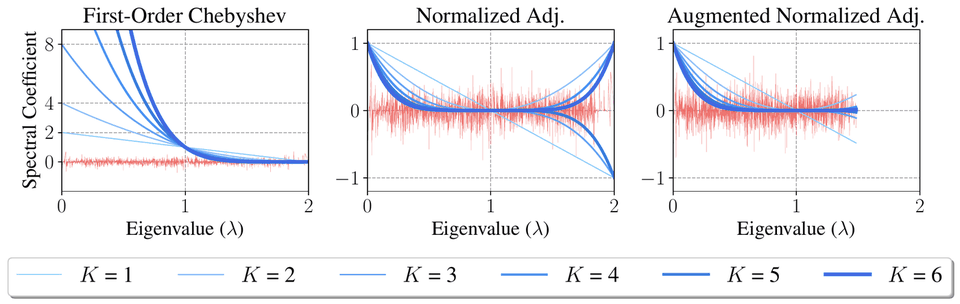

***The renormalization trick, seen in the spectrum.** Frequency response of $K = 1, \ldots, 6$ stacked propagations (blue) over the eigenvalues $\lambda$ of Cora, with the spectrum of one input feature in red. **Left:** Step 3's operator $I + D^{-1/2}AD^{-1/2}$ (first-order Chebyshev) has response $(2-\lambda)^K$, which explodes like $2^K$ at low frequencies. **Middle:** $D^{-1/2}AD^{-1/2}$ alone has response $(1-\lambda)^K$, which keeps magnitude ~1 near $\lambda = 2$, so high frequencies are *not* removed. **Right:** the self-looped $\hat{A}$ shrinks the spectrum, and $\hat{A}^K$ becomes a clean low-pass filter. Our own version of this plot on the karate club is below. Source: [Wu et al., *Simplifying Graph Convolutional Networks*, ICML 2019](https://arxiv.org/abs/1902.07153).*


**Step 5: multiple channels.** Replace the scalar $\theta$ by a weight matrix and add a nonlinearity:

$$
\boxed{\;H^{(l+1)} = \sigma\!\left(\hat{A}\, H^{(l)}\, W^{(l)}\right)\;}
$$

That is the GCN layer. In spectral terms, $\hat{A}$ is the fixed filter $g(\tilde{\lambda}) = 1 - \tilde{\lambda}$ on the self-looped graph's frequencies, and $\hat{A}^k$ (k stacked layers, ignoring weights and nonlinearities) is $g(\tilde{\lambda}) = (1 - \tilde{\lambda})^k$, a **low-pass filter** that gets sharper with depth. Hold on to that last sentence: it is the explanation for over-smoothing in Part 6.

I + D^-1/2 A D^-1/2 eigenvalues in [0.285, 2.000]
A_hat               eigenvalues in [-0.420, 1.000]


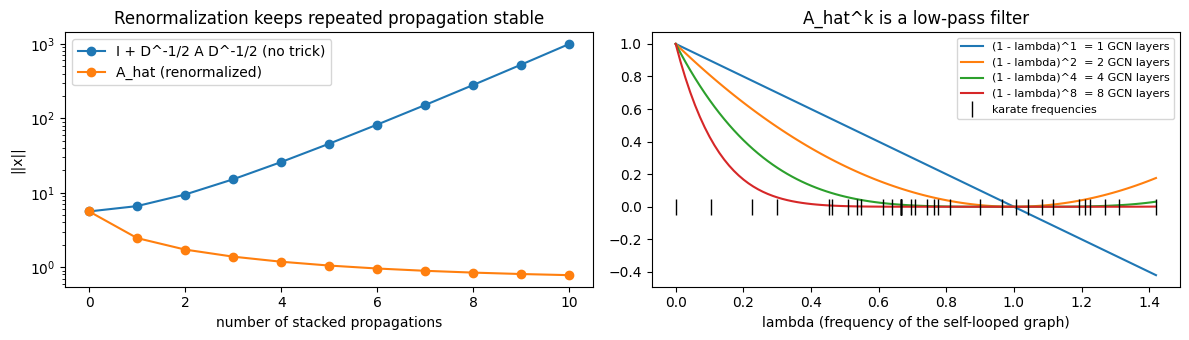

In [15]:
def gcn_norm_dense(edge_index, num_nodes):
    # A_hat = D~^{-1/2} (A + I) D~^{-1/2}
    A_tilde = edge_index_to_adjacency(edge_index, num_nodes) + torch.eye(num_nodes)
    deg_inv_sqrt = A_tilde.sum(1).pow(-0.5)
    return deg_inv_sqrt.unsqueeze(1) * A_tilde * deg_inv_sqrt.unsqueeze(0)


A_karate = edge_index_to_adjacency(karate_edge_index, karate_num_nodes)
deg_k = A_karate.sum(1)
before_trick = torch.eye(karate_num_nodes) + (deg_k.pow(-0.5).unsqueeze(1) * A_karate * deg_k.pow(-0.5).unsqueeze(0))
A_hat_karate = gcn_norm_dense(karate_edge_index, karate_num_nodes)

ev_before = torch.linalg.eigvalsh(before_trick)
ev_after = torch.linalg.eigvalsh(A_hat_karate)
print(f"I + D^-1/2 A D^-1/2 eigenvalues in [{ev_before.min():.3f}, {ev_before.max():.3f}]")
print(f"A_hat               eigenvalues in [{ev_after.min():.3f}, {ev_after.max():.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
# What happens to the norm of a random signal when we apply each operator 10 times?
set_seed(0)
x = torch.randn(karate_num_nodes)
norms_before, norms_after = [x.norm().item()], [x.norm().item()]
xb, xa = x.clone(), x.clone()
for _ in range(10):
    xb, xa = before_trick @ xb, A_hat_karate @ xa
    norms_before.append(xb.norm().item())
    norms_after.append(xa.norm().item())
axes[0].semilogy(norms_before, "o-", label="I + D^-1/2 A D^-1/2 (no trick)")
axes[0].semilogy(norms_after, "o-", label="A_hat (renormalized)")
axes[0].set_xlabel("number of stacked propagations")
axes[0].set_ylabel("||x||")
axes[0].set_title("Renormalization keeps repeated propagation stable")
axes[0].legend()

# Filter response of A_hat^k as a function of the self-looped graph's frequencies
lam_tilde = 1 - ev_after   # eigenvalues of L~_sym = I - A_hat
grid = torch.linspace(0, lam_tilde.max(), 100)
for k in [1, 2, 4, 8]:
    axes[1].plot(grid, (1 - grid) ** k, label=f"(1 - lambda)^{k}  = {k} GCN layers")
axes[1].plot(lam_tilde, torch.zeros_like(lam_tilde), "k|", markersize=12, label="karate frequencies")
axes[1].set_xlabel("lambda (frequency of the self-looped graph)")
axes[1].set_title("A_hat^k is a low-pass filter")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Part 3: Message passing, the spatial view

The GCN layer $H' = \sigma(\hat{A} H W)$ came from spectral theory, but look at what it does to **one node**. Row $i$ of $\hat{A} H W$ is

$$
h_i' = \sigma\Big( \sum_{j \in \mathcal{N}(i) \cup \{i\}} \hat{A}_{ij}\, W h_j \Big) = \sigma\Big( \sum_{j \in \mathcal{N}(i) \cup \{i\}} \frac{1}{\sqrt{\tilde{d}_i \tilde{d}_j}}\, W h_j \Big)
$$

(writing $h_j$ as a column vector; in code this is `h_j @ W`). Read it as a three-step recipe:

1. every neighbour $j$ (and $i$ itself, thanks to the self-loop) **sends a message**: its transformed features $W h_j$, scaled by $1/\sqrt{\tilde{d}_i \tilde{d}_j}$,
2. node $i$ **aggregates** the incoming messages with a sum,
3. node $i$ **updates** its state by applying $\sigma$.

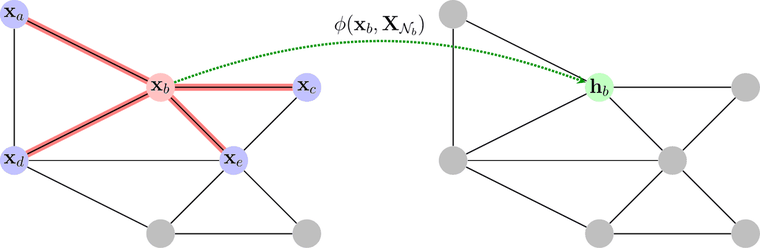

***A GNN layer, locally.** Node $b$ computes its new representation $\mathbf{h}_b = \phi(\mathbf{x}_b, \mathbf{X}_{\mathcal{N}_b})$ from its own features and the multiset of its neighbours' features (highlighted edges). The same $\phi$ is applied at every node, which is what makes the layer permutation equivariant. Source: [Bronstein, Bruna, Cohen & Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, 2021](https://arxiv.org/abs/2104.13478).*


No eigenvectors, no Fourier transform. The spectral filter is equivalent to a purely local computation, which is why GCNs scale to graphs with millions of nodes. Every popular GNN fits this local recipe.

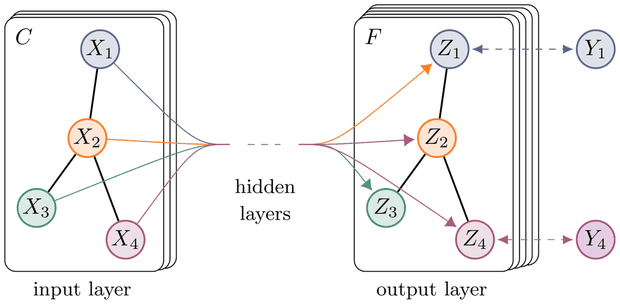

***A multi-layer GCN.** Every node starts with $C$ input channels $X_i$; hidden layers propagate over the *same* graph; the output layer gives $F$ channels $Z_i$ per node. Labels $Y_i$ exist for only a few nodes (semi-supervised training, Part 5). Source: [Kipf & Welling, *Semi-Supervised Classification with Graph Convolutional Networks*, ICLR 2017](https://arxiv.org/abs/1609.02907).*


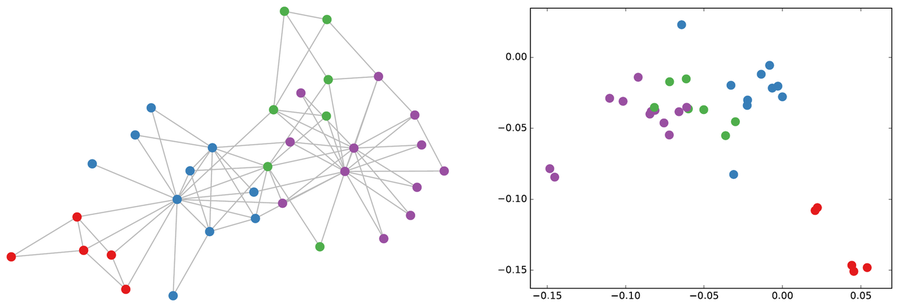

***Even an untrained GCN finds communities.** Left: the karate club, coloured by communities found with modularity clustering. Right: the 2-D output of a 3-layer GCN with **random, untrained weights**. The communities already separate, because $\hat{A}$ is a low-pass filter: it makes connected nodes similar (Part 2). Source: [Kipf & Welling, *Semi-Supervised Classification with Graph Convolutional Networks*, ICLR 2017](https://arxiv.org/abs/1609.02907).*


## The general framework: Message Passing Neural Networks (MPNN)

Gilmer et al. (2017) wrote down the general form. One layer of message passing is:

$$
\begin{aligned}
m_{j \rightarrow i} &= \phi\left(h_i,\; h_j,\; e_{ji}\right) && \text{message: computed on every edge} \\
m_i &= \bigoplus_{j \in \mathcal{N}(i)} m_{j \rightarrow i} && \text{aggregate: a permutation-invariant reduction (sum, mean, max, ...)} \\
h_i' &= \psi\left(h_i,\; m_i\right) && \text{update: combine the node's own state with the aggregate}
\end{aligned}
$$

* $\phi$ and $\psi$ are learnable (linear layers, MLPs, GRUs, ...) and **shared by every edge / node**, the same way a CNN shares its kernel across pixels. This is why the number of parameters does not depend on the size of the graph.
* $\bigoplus$ must be **permutation invariant** and must accept **any number of inputs** (degrees vary). That rules out concatenation and leaves sum / mean / max / attention-weighted sum. This choice is what makes every layer permutation equivariant.
* Stacking $K$ layers lets information travel $K$ hops.

For graph-level tasks a final **readout** $h_G = R(\{h_i : i \in V\})$ (again permutation invariant) pools the nodes into one vector.

Every architecture in this notebook is a particular choice of $(\phi, \bigoplus, \psi)$:

| Model | message $\phi$ | aggregate $\bigoplus$ | update $\psi$ |
|---|---|---|---|
| GCN | $\frac{1}{\sqrt{\tilde{d}_i\tilde{d}_j}} W h_j$ | sum over $\mathcal{N}(i) \cup \{i\}$ | $\sigma(m_i)$ |
| GraphSAGE | $h_j$ | mean (or max) | $\sigma(W_1 h_i + W_2 m_i)$ |
| GAT | $\alpha_{ij} W h_j$, with learned $\alpha_{ij}$ | sum over $\mathcal{N}(i) \cup \{i\}$ | $\sigma(m_i)$ |
| GIN | $h_j$ | sum | $\text{MLP}\left((1+\epsilon) h_i + m_i\right)$ |
| MPNN (chemistry) | $\text{MLP}(h_i, h_j, e_{ji})$ | sum | $\text{GRU}(h_i, m_i)$ |


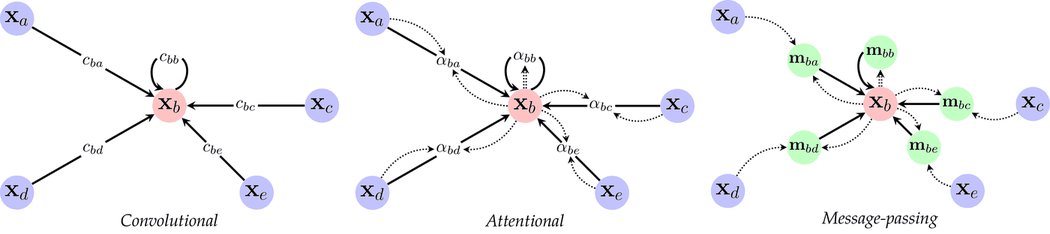

***The three flavours of GNN layers**, in increasing generality. **Convolutional:** sender features are multiplied by a constant $c_{ij}$ fixed by the graph structure (GCN, ChebNet, SGC). **Attentional:** the multiplier is computed from the features, $\alpha_{ij} = a(\mathbf{x}_i, \mathbf{x}_j)$ (GAT). **Message-passing:** arbitrary vector messages $\mathbf{m}_{ij} = \psi(\mathbf{x}_i, \mathbf{x}_j)$ computed from both sender and receiver (MPNN, GIN with edge features). Convolutional $\subseteq$ attentional $\subseteq$ message passing. Source: [Bronstein, Bruna, Cohen & Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, 2021](https://arxiv.org/abs/2104.13478).*

## The mechanics: gather and scatter

With `edge_index` of shape $(2, E)$, a message passing layer is two indexing operations:

1. **Gather**: `x[edge_index[0]]` copies the features of the *source* of every edge into an $(E, F)$ tensor, one row per message. (Similarly `x[edge_index[1]]` gathers the *target* features, needed when the message depends on $h_i$.)
2. **Scatter**: reduce the $(E, F)$ messages back into $(N, F)$ by grouping on the target index `edge_index[1]`. For a sum this is `torch.zeros(N, F).index_add_(0, edge_index[1], messages)`.

Both are $O(E \cdot F)$, and both parallelize perfectly on a GPU. Let's trace it on the toy graph with $h_j = 10 \cdot j$ so we can read the numbers.

In [16]:
# Node j holds the value 10 * j, so we can see who sent what
h = (torch.arange(toy_num_nodes).float() * 10).unsqueeze(1)    # (N, 1)
source, target = toy_edge_index                                 # (E,), (E,)

# 1. GATHER: one message per edge, the feature of the sender
# Shape: (N, F) indexed by (E,) -> (E, F)
messages = h[source]
print("edge (j -> i)   message h_j")
for e in range(toy_edge_index.size(1)):
    print(f"   {source[e].item()} -> {target[e].item()}          {messages[e].item():4.0f}")

# 2. SCATTER: sum the messages that arrive at each target node
# Shape: (E, F) grouped by target -> (N, F)
aggregated = torch.zeros(toy_num_nodes, 1).index_add_(0, target, messages)
print("\nsum of incoming messages per node:", aggregated.squeeze().tolist())
print("same as the dense product A @ h:   ", (A_toy @ h).squeeze().tolist())

edge (j -> i)   message h_j
   0 -> 1             0
   0 -> 2             0
   1 -> 0            10
   1 -> 2            10
   2 -> 0            20
   2 -> 1            20
   2 -> 3            20
   3 -> 2            30
   3 -> 4            30
   3 -> 5            30
   4 -> 3            40
   4 -> 5            40
   5 -> 3            50
   5 -> 4            50

sum of incoming messages per node: [30.0, 20.0, 40.0, 110.0, 80.0, 70.0]
same as the dense product A @ h:    [30.0, 20.0, 40.0, 110.0, 80.0, 70.0]


## A general `scatter` with sum / mean / max / min

`index_add_` only sums. For mean we divide by the number of incoming messages (the in-degree), and for max/min we use `Tensor.scatter_reduce_` with `include_self=False` so the zeros we start from do not take part in the reduction. Nodes that receive no message (isolated nodes) end up with 0.

We also need one more reduction for attention: the **softmax over the incoming edges of each node** (an "edge softmax"):

$$
\alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{k \in \mathcal{N}(i)} \exp(e_{ik})} = \frac{\exp(e_{ij} - \max_k e_{ik})}{\sum_{k \in \mathcal{N}(i)} \exp(e_{ik} - \max_k e_{ik})}
$$

The second form subtracts the per-node maximum for numerical stability (the same trick as a normal softmax). It is built from three scatters: a max, a sum, and a gather.

In [17]:
def scatter(src: torch.Tensor, index: torch.Tensor, dim_size: int, reduce: str = "sum") -> torch.Tensor:
    # Reduce rows of src that share the same index.
    # src: (E, *F) messages, index: (E,) target node of each message -> (dim_size, *F)
    out_shape = (dim_size,) + tuple(src.shape[1:])
    if reduce in ("sum", "add"):
        return torch.zeros(out_shape, dtype=src.dtype, device=src.device).index_add_(0, index, src)
    if reduce == "mean":
        total = torch.zeros(out_shape, dtype=src.dtype, device=src.device).index_add_(0, index, src)
        count = torch.bincount(index, minlength=dim_size).clamp(min=1).to(src.dtype)
        # Broadcast the counts over the feature dimensions: (N,) -> (N, 1, ..., 1)
        return total / count.view(-1, *([1] * (src.dim() - 1)))
    if reduce in ("max", "min"):
        # scatter_reduce_ needs the index expanded to the full shape of src
        index_expanded = index.view(-1, *([1] * (src.dim() - 1))).expand_as(src)
        out = torch.zeros(out_shape, dtype=src.dtype, device=src.device)
        return out.scatter_reduce_(0, index_expanded, src, reduce="a" + reduce, include_self=False)
    raise ValueError(f"unknown reduce {reduce}")


def scatter_softmax(src: torch.Tensor, index: torch.Tensor, num_nodes: int) -> torch.Tensor:
    # Softmax over all edges that point to the same target node.
    # src: (E,) or (E, heads) raw scores -> same shape, sums to 1 within each target group
    src_max = scatter(src, index, num_nodes, reduce="max")     # (N, heads) max score per node
    src = src - src_max[index]                                 # (E, heads) subtract for stability
    exp = src.exp()
    denom = scatter(exp, index, num_nodes, reduce="sum")       # (N, heads) normalizer per node
    return exp / (denom[index] + 1e-16)                        # (E, heads)


for reduce in ["sum", "mean", "max", "min"]:
    print(f"{reduce:>4}: {scatter(messages, target, toy_num_nodes, reduce).squeeze().tolist()}")

scores = torch.randn(toy_edge_index.size(1))
alpha = scatter_softmax(scores, target, toy_num_nodes)
print("\nedge-softmax weights sum to 1 per node:", scatter(alpha, target, toy_num_nodes).tolist())

 sum: [30.0, 20.0, 40.0, 110.0, 80.0, 70.0]
mean: [15.0, 10.0, 13.333333015441895, 36.66666793823242, 40.0, 35.0]
 max: [20.0, 20.0, 30.0, 50.0, 50.0, 40.0]
 min: [10.0, 0.0, 0.0, 20.0, 30.0, 30.0]

edge-softmax weights sum to 1 per node: [1.0, 1.0, 1.0, 0.9999999403953552, 1.0, 1.0]


## The `MessagePassing` base class

Now we package gather → message → scatter → update into a reusable base class (the same design PyTorch Geometric uses). Subclasses only override the parts that differ:

* `message(x_i, x_j, **kwargs)`: compute one message per edge. `x_j` are the source (sender) features and `x_i` the target (receiver) features, both of shape $(E, F)$. Any extra per-edge tensor passed to `propagate` (edge weights, attention coefficients, edge features) arrives as a keyword argument.
* `aggregate(messages, index, num_nodes)`: by default the `scatter` above with `self.aggr`.
* `update(aggregated, x)`: by default the identity.

The direction convention matters: **messages flow from `edge_index[0]` to `edge_index[1]`**, so a node aggregates over its *incoming* edges. For undirected graphs every edge is stored in both directions, so this is the full neighbourhood.

In [18]:
class MessagePassing(nn.Module):
    def __init__(self, aggr: str = "sum"):
        # aggr is the permutation-invariant reduction used to combine incoming messages
        super().__init__()
        self.aggr = aggr

    def propagate(self, edge_index: torch.Tensor, x: torch.Tensor, num_nodes: int = None, **kwargs):
        num_nodes = x.size(0) if num_nodes is None else num_nodes
        source, target = edge_index
        # Gather the features of both endpoints of every edge
        # Shape: (N, *F) -> (E, *F)
        x_j = x[source]     # sender
        x_i = x[target]     # receiver
        # One message per edge. `index`/`num_nodes` are passed so attention layers can do an edge softmax.
        messages = self.message(x_i=x_i, x_j=x_j, index=target, num_nodes=num_nodes, **kwargs)
        # Reduce the messages of each target node
        # Shape: (E, *F) -> (N, *F)
        aggregated = self.aggregate(messages, target, num_nodes)
        return self.update(aggregated, x=x)

    def message(self, x_i, x_j, **kwargs):
        return x_j

    def aggregate(self, messages, index, num_nodes):
        return scatter(messages, index, num_nodes, reduce=self.aggr)

    def update(self, aggregated, x):
        return aggregated


# Sanity check: the default layer (message = x_j, sum) is exactly A @ x
mp = MessagePassing(aggr="sum")
print("MessagePassing(sum)  == A @ h:", torch.allclose(mp.propagate(toy_edge_index, h), A_toy @ h))
mp.aggr = "mean"
print("MessagePassing(mean) == D^-1 A @ h:", torch.allclose(mp.propagate(toy_edge_index, h), (A_toy / toy_deg.unsqueeze(1)) @ h))

MessagePassing(sum)  == A @ h: True
MessagePassing(mean) == D^-1 A @ h: True


## Our first real layer: `GCNConv` as message passing

The GCN layer as message passing:

* **preprocess**: add self-loops and compute one normalization coefficient per edge, $\text{norm}_{j \rightarrow i} = \tilde{d}_i^{-1/2}\, \tilde{d}_j^{-1/2}$. These depend only on the graph, so we can cache them.
* **transform first**: compute $XW$ before propagating. By associativity $\hat{A}(XW) = (\hat{A}X)W$, but on Cora $X$ is $2708 \times 1433$ and $XW$ is $2708 \times 16$, so propagating the smaller matrix is ~90x cheaper.
* **message**: $\text{norm}_{j \rightarrow i} \cdot (W h_j)$.
* **aggregate**: sum.

We verify it against the dense formula $\hat{A} X W + b$ from Part 2.

In [19]:
def gcn_norm(edge_index: torch.Tensor, num_nodes: int, add_loops: bool = True):
    # Returns the (self-looped) edge_index and the symmetric normalization of every edge
    if add_loops:
        edge_index = add_self_loops(edge_index, num_nodes)
    source, target = edge_index
    deg = degree(target, num_nodes)                    # d~_i (includes the self loop)
    deg_inv_sqrt = deg.pow(-0.5)
    deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0
    # norm_{j->i} = d~_i^{-1/2} * d~_j^{-1/2}   Shape: (E,)
    norm = deg_inv_sqrt[target] * deg_inv_sqrt[source]
    return edge_index, norm


class GCNConv(MessagePassing):
    def __init__(self, in_channels: int, out_channels: int, cached: bool = False):
        super().__init__(aggr="sum")
        self.linear = nn.Linear(in_channels, out_channels, bias=False)   # W
        self.bias = nn.Parameter(torch.zeros(out_channels))
        nn.init.xavier_uniform_(self.linear.weight)                     # Glorot init, as in the paper
        # For transductive training on one fixed graph the normalization never changes, so cache it
        self.cached = cached
        self._cache = None

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        num_nodes = x.size(0)
        if self.cached and self._cache is not None:
            edge_index, norm = self._cache
        else:
            edge_index, norm = gcn_norm(edge_index, num_nodes)
            if self.cached:
                self._cache = (edge_index, norm)
        # Transform first: (N, F_in) -> (N, F_out)
        x = self.linear(x)
        # Propagate: (N, F_out) -> (E, F_out) messages -> (N, F_out)
        out = self.propagate(edge_index, x, norm=norm)
        return out + self.bias

    def message(self, x_i, x_j, norm, **kwargs):
        # Scale each sender's features by its edge normalization
        # Shape: (E, 1) * (E, F_out) -> (E, F_out)
        return norm.unsqueeze(-1) * x_j


set_seed(0)
conv = GCNConv(in_channels=3, out_channels=4)
X_karate = torch.randn(karate_num_nodes, 3)
with torch.no_grad():
    sparse_out = conv(X_karate, karate_edge_index)
    dense_out = A_hat_karate @ X_karate @ conv.linear.weight.T + conv.bias
print("GCNConv (message passing) == A_hat X W + b :", torch.allclose(sparse_out, dense_out, atol=1e-6))
print("output shape:", sparse_out.shape)

GCNConv (message passing) == A_hat X W + b : True
output shape: torch.Size([34, 4])


## Receptive field: $K$ layers see $K$ hops

Each layer moves information one hop, so the output of node $i$ after $K$ layers depends exactly on its **$K$-hop neighbourhood**. A useful mental picture is the **computation tree**: unroll node $i$'s neighbourhood $K$ levels deep; the GNN computes $h_i^{(K)}$ by running the shared message/update functions bottom-up on that tree. Two nodes with identical computation trees (same features, same structure) *must* get identical embeddings, which is the root of the expressivity limits in Part 4.

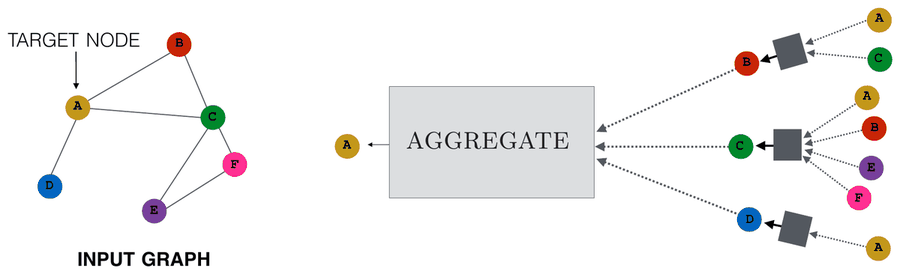

***The computation graph.** Target node A aggregates messages from its neighbours B, C and D, whose messages were in turn aggregated from *their* neighbours. Unrolled, a 2-layer GNN is a depth-2 tree rooted at the target node, and every square box is the same shared aggregate/update function. Source: [Hamilton, *Graph Representation Learning*, Morgan & Claypool 2020](https://www.cs.mcgill.ca/~wlh/grl_book/).*


Below we put a one-hot signal on node 0 and propagate it with GCN normalization (no weights). The set of nodes that "know" about node 0 grows by one hop per layer.

(A related problem: on graphs where the $K$-hop neighbourhood grows exponentially, all that information has to be squeezed into one fixed-size vector, a bottleneck known as **over-squashing**, Alon & Yahav 2021.)

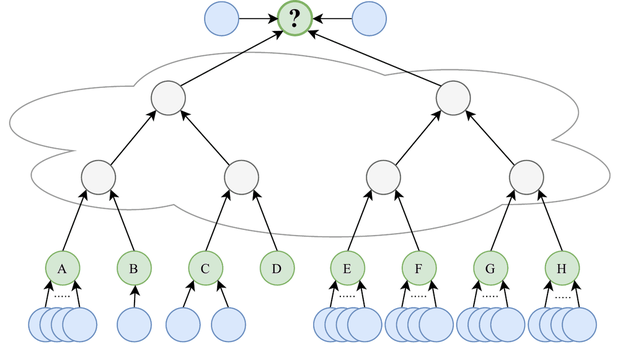

***Over-squashing.** The receptive field of the target node "?" grows exponentially with the number of layers (the cloud), but all of that information has to be squeezed into one fixed-size vector at the root. Source: [Alon & Yahav, *On the Bottleneck of Graph Neural Networks and its Practical Implications*, ICLR 2021](https://arxiv.org/abs/2006.05205).*


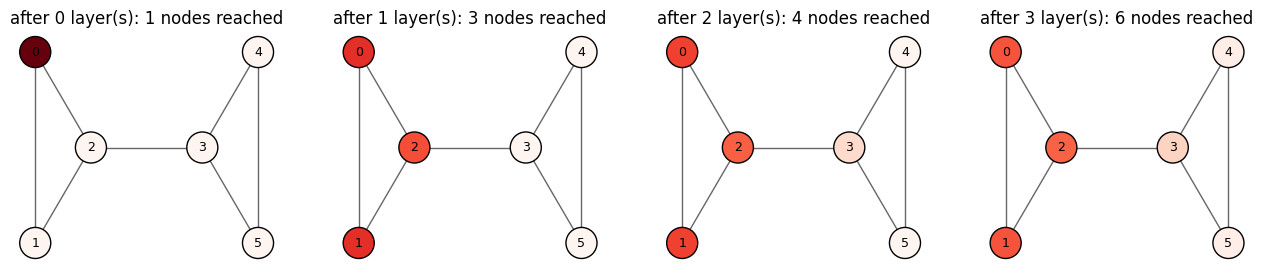

In [20]:
edge_index_sl, norm_sl = gcn_norm(toy_edge_index, toy_num_nodes)
propagate_only = MessagePassing(aggr="sum")
propagate_only.message = lambda x_i, x_j, norm, **kw: norm.unsqueeze(-1) * x_j

signal = torch.zeros(toy_num_nodes, 1)
signal[0] = 1.0
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for k, ax in enumerate(axes):
    reached = (signal.squeeze() > 1e-9).sum().item()
    draw_graph(toy_edge_index, toy_num_nodes, node_color=signal.squeeze(), ax=ax, pos=toy_pos,
               cmap="Reds", vmin=0, vmax=0.5, title=f"after {k} layer(s): {reached} nodes reached")
    signal = propagate_only.propagate(edge_index_sl, signal, norm=norm_sl)
plt.show()

## Aggregators: what can sum, mean and max tell apart?

The aggregator sees a **multiset** of neighbour features (a set that can contain repeats). Different aggregators throw away different information (Xu et al. 2019):

* **mean** sees the *distribution* (the proportions) of the multiset, but not its size: $\{a, b\}$ and $\{a, a, b, b\}$ look identical.
* **max** sees only the *set* of distinct (per-feature extreme) values: $\{a, a, b\}$ and $\{a, b, b\}$ look identical, and so do $\{a\}$ and $\{a, a\}$.
* **sum** sees the *whole multiset*. For one-hot / countable features, sum is **injective**: different multisets give different sums.

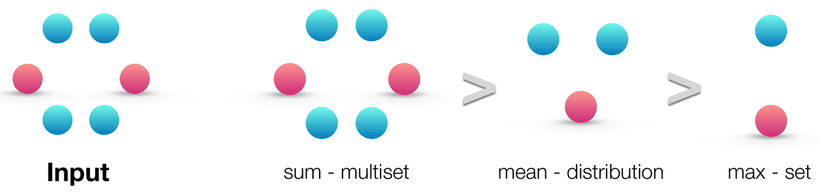

***Ranking by expressive power.** For the input multiset on the left, **sum** captures the full multiset, **mean** only the proportions (distribution) of its elements, and **max** reduces it to the set of distinct elements. Source: [Xu, Hu, Leskovec & Jegelka, *How Powerful are Graph Neural Networks?*, ICLR 2019](https://arxiv.org/abs/1810.00826).*


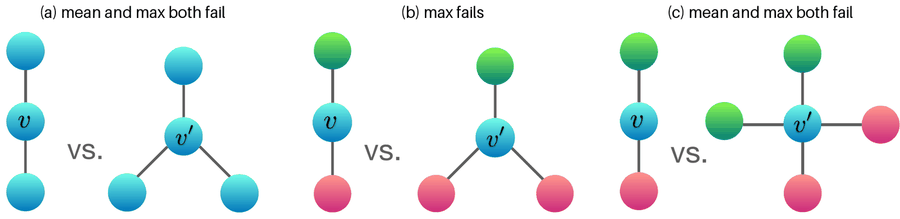

***Neighbourhoods the aggregators confuse** (same colour = same feature; we want to tell $v$ from $v'$). (a) All neighbours identical: mean and max give the same answer for 2 or 3 neighbours. (b) $\{g, r\}$ vs $\{g, r, r\}$: the proportions differ (mean works) but the set is the same (max fails). (c) $\{g, r\}$ vs $\{g, g, r, r\}$: same proportions and same set, so both fail. Sum distinguishes all three. Source: [Xu, Hu, Leskovec & Jegelka, *How Powerful are Graph Neural Networks?*, ICLR 2019](https://arxiv.org/abs/1810.00826).*


So sum is the most expressive. Mean and max are not useless though: mean is robust to degree differences (a hub's sum can be 100x larger than a leaf's), and max is good at detecting "is there at least one neighbour with property X". The right choice depends on the task, but sum is what you need for maximum distinguishing power, which is the idea behind GIN.

In [21]:
a, b = torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])
multiset_pairs = {
    "{a, b}     vs {a, a, b, b}": ([a, b], [a, a, b, b]),
    "{a, a, b}  vs {a, b, b}   ": ([a, a, b], [a, b, b]),
    "{a}        vs {a, a}      ": ([a], [a, a]),
}
print(f"{'multisets':30s}{'sum':>12s}{'mean':>12s}{'max':>12s}")
for name, (m1, m2) in multiset_pairs.items():
    m1, m2 = torch.stack(m1), torch.stack(m2)
    row = []
    for reduce in ["sum", "mean", "max"]:
        r1 = scatter(m1, torch.zeros(len(m1), dtype=torch.long), 1, reduce)
        r2 = scatter(m2, torch.zeros(len(m2), dtype=torch.long), 1, reduce)
        row.append("distinct" if not torch.allclose(r1, r2) else "SAME")
    print(f"{name:30s}" + "".join(f"{r:>12s}" for r in row))

multisets                              sum        mean         max
{a, b}     vs {a, a, b, b}        distinct        SAME        SAME
{a, a, b}  vs {a, b, b}           distinct    distinct        SAME
{a}        vs {a, a}              distinct        SAME        SAME


# Part 4: The architectures

We already have `GCNConv`. Its defining property is that the weight of each neighbour, $1/\sqrt{\tilde{d}_i \tilde{d}_j}$, is **fixed by the graph structure**: every neighbour of the same degree contributes equally, and the node's own state is averaged in with its neighbours using the same $W$. The next three architectures each relax one of GCN's limitations:

* **GraphSAGE**: separate weights for "self" and "neighbours", flexible aggregators, and **neighbour sampling** so it scales and works inductively.
* **GAT**: the neighbour weights $\alpha_{ij}$ are **learned from the features** (attention).
* **GIN**: the **most expressive** aggregation possible for message passing, as powerful as the Weisfeiler-Lehman test.

## GraphSAGE (Hamilton et al., 2017)

SAGE = **SA**mple and aggre**G**at**E**. The layer:

$$
\begin{aligned}
h_{\mathcal{N}(i)} &= \text{AGG}\left(\{h_j : j \in \mathcal{S}(i)\}\right) && \mathcal{S}(i) \subseteq \mathcal{N}(i) \text{ is a random sample of neighbours} \\
h_i' &= \sigma\left(W \cdot \left[h_i \,\Vert\, h_{\mathcal{N}(i)}\right]\right) = \sigma\left(W_{\text{self}}\, h_i + W_{\text{neigh}}\, h_{\mathcal{N}(i)}\right) \\
h_i' &\leftarrow h_i' / \lVert h_i' \rVert_2 && \text{(optional L2 normalization)}
\end{aligned}
$$

($\Vert$ is concatenation; multiplying a concatenation by $W = [W_{\text{self}}\; W_{\text{neigh}}]$ is the same as two separate matrices.)

What is different from GCN:

1. **Self vs neighbours.** GCN mixes $h_i$ into the neighbour average with the same weight matrix. SAGE keeps $h_i$ on its own path with its own weights, similar to a skip connection, so a node can keep its identity even when its neighbours look different.
2. **Aggregators.** The paper proposes mean, a "pooling" aggregator $\max_j \sigma(W_{\text{pool}} h_j + b)$ (an MLP on each neighbour, then an element-wise max), and an LSTM over a random ordering of the neighbours (which is not truly permutation invariant).
3. **Neighbour sampling.** Instead of all neighbours, each node samples a fixed number $S_l$ at layer $l$ (the paper uses $S_1 = 25, S_2 = 10$). The cost of computing one node's embedding becomes $O(\prod_l S_l)$ no matter how large the hubs are, which enables mini-batch training on graphs with billions of edges (Pinterest's PinSage is a GraphSAGE variant).
4. **Inductive.** SAGE learns an *aggregation function*, not an embedding per node, so it generalizes to nodes and graphs never seen in training. (GCN, being local, can too; the contrast is with older embedding-lookup methods like DeepWalk/node2vec.)

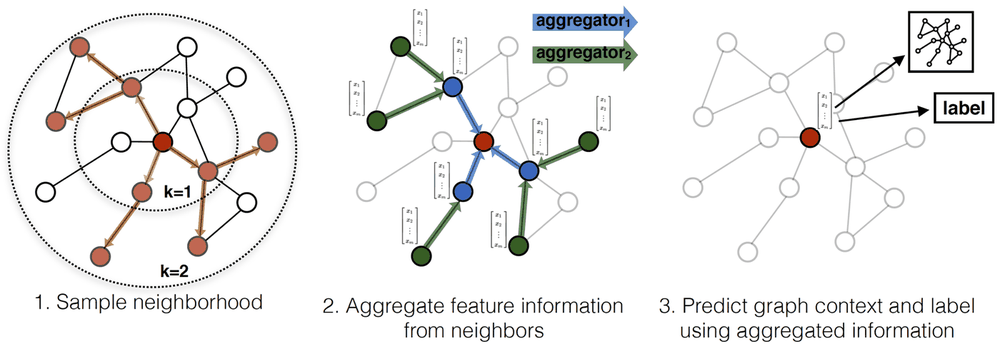

***GraphSAGE.** (1) Sample a fixed-size neighbourhood for each hop ($k = 1, 2$), (2) aggregate the sampled neighbours' features with a learned aggregator per depth, (3) use the resulting embedding to predict the node's label. Because only a fixed number of neighbours is sampled per hop, the cost per node is bounded no matter how large the hubs are. Source: [Hamilton, Ying & Leskovec, *Inductive Representation Learning on Large Graphs*, NeurIPS 2017](https://arxiv.org/abs/1706.02216).*


In [22]:
class SAGEConv(MessagePassing):
    def __init__(self, in_channels: int, out_channels: int, aggr: str = "mean", normalize: bool = False):
        # aggr="mean" -> mean aggregator; aggr="pool" -> max over an MLP of each neighbour
        super().__init__(aggr="max" if aggr == "pool" else aggr)
        self.pool = aggr == "pool"
        if self.pool:
            self.pool_mlp = nn.Sequential(nn.Linear(in_channels, in_channels), nn.ReLU())
        self.lin_self = nn.Linear(in_channels, out_channels)               # W_self (with bias)
        self.lin_neigh = nn.Linear(in_channels, out_channels, bias=False)  # W_neigh
        self.normalize = normalize

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        # Aggregate the neighbours: (N, F_in) -> (N, F_in)
        neigh_input = self.pool_mlp(x) if self.pool else x
        h_neigh = self.propagate(edge_index, neigh_input)
        # Combine self and neighbourhood with separate weights: (N, F_in) -> (N, F_out)
        out = self.lin_self(x) + self.lin_neigh(h_neigh)
        if self.normalize:
            out = F.normalize(out, p=2, dim=-1)
        return out


def sample_neighbors(edge_index: torch.Tensor, num_nodes: int, fanout: int) -> torch.Tensor:
    # Keep at most `fanout` randomly chosen incoming edges per target node (vectorized).
    # 1. shuffle the edges, 2. stable-sort by target so each node's edges are contiguous (in random order),
    # 3. compute each edge's rank inside its target group, 4. keep ranks < fanout.
    num_edges = edge_index.size(1)
    shuffled = torch.randperm(num_edges)
    order = shuffled[torch.argsort(edge_index[1, shuffled], stable=True)]
    target_sorted = edge_index[1, order]
    counts = torch.bincount(target_sorted, minlength=num_nodes)
    group_start = torch.cumsum(counts, 0) - counts                  # first position of each node's group
    rank_in_group = torch.arange(num_edges) - group_start[target_sorted]
    return edge_index[:, order[rank_in_group < fanout]]


set_seed(0)
sampled = sample_neighbors(karate_edge_index, karate_num_nodes, fanout=4)
deg_full = degree(karate_edge_index[1], karate_num_nodes)
deg_sampled = degree(sampled[1], karate_num_nodes)
print(f"edges before sampling: {karate_edge_index.size(1)}, after (fanout=4): {sampled.size(1)}")
print("max in-degree before:", int(deg_full.max()), " after:", int(deg_sampled.max()))
print("every sampled edge exists in the graph:",
      torch.isin(sampled[0] * karate_num_nodes + sampled[1], karate_edge_index[0] * karate_num_nodes + karate_edge_index[1]).all().item())

sage = SAGEConv(3, 4, aggr="mean")
print("SAGEConv output shape:", sage(X_karate, karate_edge_index).shape)

edges before sampling: 156, after (fanout=4): 105
max in-degree before: 17  after: 4
every sampled edge exists in the graph: True
SAGEConv output shape: torch.Size([34, 4])


## Graph Attention Networks: GAT (Veličković et al., 2018)

In GCN the weight of neighbour $j$ is fixed by degrees. GAT **learns** it from the features of $i$ and $j$, so the model can decide which neighbours matter. One attention head:

$$
\begin{aligned}
z_i &= W h_i && \text{shared linear projection} \\
e_{ij} &= \text{LeakyReLU}\left(a^\top \left[z_i \,\Vert\, z_j\right]\right) && \text{unnormalized score for edge } j \rightarrow i \text{ (slope 0.2)} \\
\alpha_{ij} &= \operatorname{softmax}_{j \in \mathcal{N}(i) \cup \{i\}}\left(e_{ij}\right) = \frac{\exp(e_{ij})}{\sum_{k \in \mathcal{N}(i) \cup \{i\}} \exp(e_{ik})} && \text{edge softmax over } i\text{'s neighbourhood} \\
h_i' &= \sigma\Big(\sum_{j \in \mathcal{N}(i) \cup \{i\}} \alpha_{ij}\, z_j\Big) && \text{attention-weighted sum}
\end{aligned}
$$


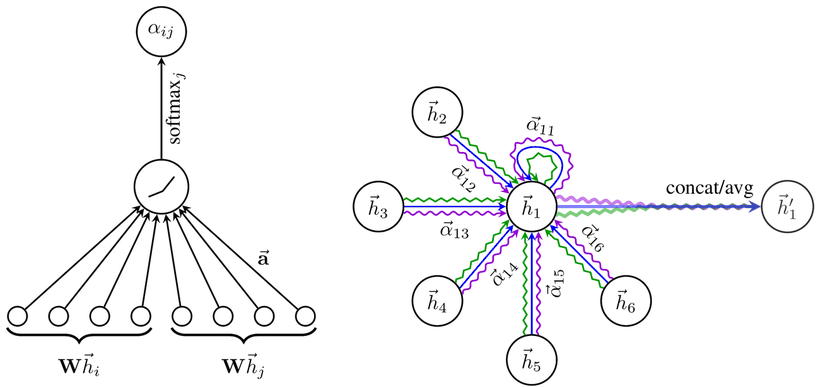

***GAT. Left:** the attention mechanism $a(\mathbf{W}\vec{h}_i, \mathbf{W}\vec{h}_j)$: concatenate the two projected vectors, take the dot product with the weight vector $\vec{\mathbf{a}}$, apply LeakyReLU, and softmax over the neighbours $j$. **Right:** multi-head attention ($K = 3$ heads, one colour each) by node 1 over its neighbourhood. Each head computes its own $\vec{\alpha}_{1j}$, and the heads' outputs are concatenated (hidden layers) or averaged (output layer) into $\vec{h}'_1$. Source: [Veličković et al., *Graph Attention Networks*, ICLR 2018](https://arxiv.org/abs/1710.10903).*

**Multi-head attention**, as in the Transformer: run $K$ independent heads and concatenate them (hidden layers) or average them (the output layer):

$$
h_i' = \Big\Vert_{k=1}^{K}\, \sigma\Big(\sum_j \alpha_{ij}^{(k)} W^{(k)} h_j\Big) \qquad\text{or}\qquad h_i' = \sigma\Big(\frac{1}{K}\sum_{k=1}^{K} \sum_j \alpha_{ij}^{(k)} W^{(k)} h_j\Big)
$$

**The efficiency trick.** Split $a = [a_{\text{dst}};\, a_{\text{src}}]$. Then

$$
a^\top [z_i \,\Vert\, z_j] = a_{\text{dst}}^\top z_i + a_{\text{src}}^\top z_j
$$

so we compute one scalar per node per head, $s^{\text{dst}}_i = a_{\text{dst}}^\top z_i$ and $s^{\text{src}}_j = a_{\text{src}}^\top z_j$ (shape $(N, K)$), and the edge score is just `s_dst[target] + s_src[source]`. We never build the $(E, 2C)$ concatenation.

**Regularization.** The paper applies dropout (p=0.6) both to the inputs and to the normalized attention coefficients $\alpha$, which means each node sees a random subset of its neighbours at every training step.

### GAT is a Transformer restricted to the graph

Compare GAT with the scaled dot-product attention we built in notebook 09:

$$
\textbf{Transformer:}\quad h_i' = \sum_{j=1}^{N} \operatorname{softmax}_j\left(\frac{(W_Q h_i)^\top (W_K h_j)}{\sqrt{d}}\right) W_V h_j
$$

$$
\textbf{GAT:}\quad h_i' = \sum_{j \in \mathcal{N}(i) \cup \{i\}} \operatorname{softmax}_j\Big(\text{LeakyReLU}\big(a^\top[W h_i \,\Vert\, W h_j]\big)\Big) W h_j
$$

They differ in three ways:

1. **Who can attend to whom.** The Transformer attends over *all* tokens; GAT only over graph neighbours. GAT is attention with an **attention mask equal to $\tilde{A}$**.
2. **The score function.** The Transformer uses a (multiplicative) dot product of query and key; GAT uses an additive score (like Bahdanau attention).
3. **Projections.** GAT uses one $W$ for query, key and value.

So **a Transformer is a GNN on the complete graph** (every token is connected to every token), and positional encodings are how it gets back the structure the complete graph throws away. We will build on this in Part 9. Below, the GAT layer is implemented with message passing and then checked against a dense implementation that builds the full $N \times N$ score matrix and masks it, exactly like the causal mask in notebook 09.

### GATv2: static vs dynamic attention (Brody et al., 2022)

GAT has a subtle flaw. $\text{LeakyReLU}$ is monotonic, and the score splits as $a_{\text{dst}}^\top z_i + a_{\text{src}}^\top z_j$. For a fixed query $i$, the first term is a constant, so **the ranking of the neighbours $j$ is determined by $a_{\text{src}}^\top z_j$ alone, and is the same for every query node $i$**. If $j^*$ has the largest $a_{\text{src}}^\top z_j$ in the whole graph, every node that neighbours $j^*$ attends most to $j^*$. Brody et al. call this *static attention*.

GATv2 moves the nonlinearity between the two linear maps:

$$
e_{ij}^{\text{GATv2}} = a^\top\, \text{LeakyReLU}\left(W_{\text{dst}} h_i + W_{\text{src}} h_j\right)
$$

Now the score cannot be split into an $i$-part plus a $j$-part, so the ranking of the neighbours can depend on the query: *dynamic attention*. Our `GATConv` supports both with a `v2` flag.

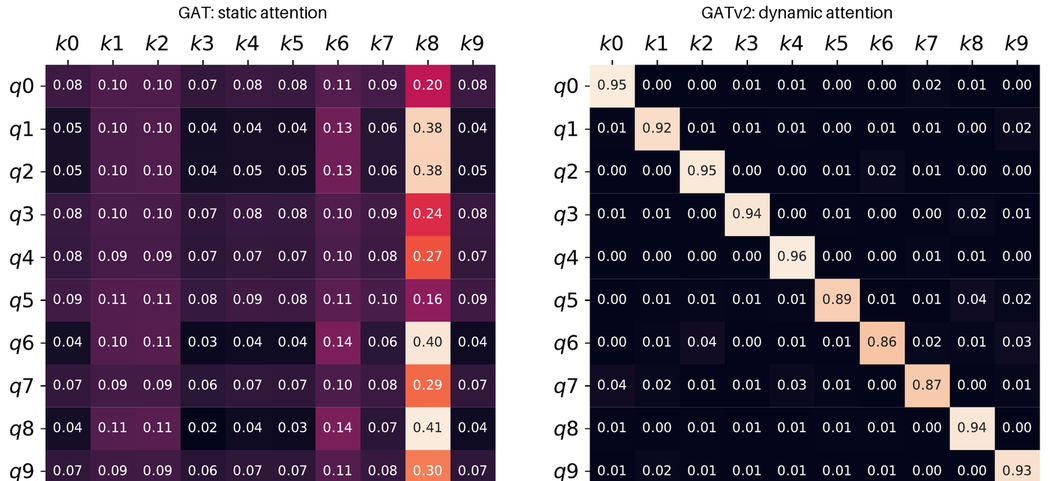

***Static vs dynamic attention.** Attention weights learned on a task where every query $q_i$ must attend to its own key $k_i$. GAT (left) learns the *same* ranking of keys for every query (all queries attend most to $k_8$) and cannot solve the task. GATv2 (right) learns a nearly perfect diagonal. Our 6-node experiment below reproduces the effect. Source: [Brody, Alon & Yahav, *How Attentive are Graph Attention Networks?*, ICLR 2022](https://arxiv.org/abs/2105.14491).*


In [23]:
class GATConv(MessagePassing):
    def __init__(self, in_channels: int, out_channels: int, heads: int = 1, concat: bool = True,
                 negative_slope: float = 0.2, dropout: float = 0.0, add_loops: bool = True, v2: bool = False):
        # out_channels is the size PER HEAD. With concat=True the output is heads * out_channels.
        super().__init__(aggr="sum")
        self.heads, self.out_channels, self.concat = heads, out_channels, concat
        self.negative_slope, self.dropout, self.add_loops, self.v2 = negative_slope, dropout, add_loops, v2
        # W for all heads at once: (F_in) -> (heads * C)
        self.lin_src = nn.Linear(in_channels, heads * out_channels, bias=False)
        # GAT shares W between source and target; GATv2 has a separate W_dst
        self.lin_dst = nn.Linear(in_channels, heads * out_channels, bias=False) if v2 else self.lin_src
        if v2:
            self.att = nn.Parameter(torch.empty(1, heads, out_channels))          # a, applied after LeakyReLU
        else:
            self.att_src = nn.Parameter(torch.empty(1, heads, out_channels))      # a_src
            self.att_dst = nn.Parameter(torch.empty(1, heads, out_channels))      # a_dst
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))
        self.reset_parameters()
        self.last_attention = None   # stores (edge_index, alpha) of the last forward for inspection

    def reset_parameters(self):
        for p in [self.lin_src.weight, self.lin_dst.weight]:
            nn.init.xavier_uniform_(p)
        for name in ["att", "att_src", "att_dst"]:
            if hasattr(self, name):
                nn.init.xavier_uniform_(getattr(self, name))

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        N, H, C = x.size(0), self.heads, self.out_channels
        if self.add_loops:
            edge_index = add_self_loops(edge_index, N)
        source, target = edge_index
        # Project and split into heads: (N, F_in) -> (N, H * C) -> (N, H, C)
        z_src = self.lin_src(x).view(N, H, C)
        z_dst = self.lin_dst(x).view(N, H, C)

        if self.v2:
            # e_ij = a^T LeakyReLU(W_dst h_i + W_src h_j)   Shape: (E, H, C) -> (E, H)
            pair = F.leaky_relu(z_dst[target] + z_src[source], self.negative_slope)
            scores = (pair * self.att).sum(dim=-1)
        else:
            # e_ij = LeakyReLU(a_dst^T z_i + a_src^T z_j)  -- one scalar per node per head, then gather per edge
            # Shape: (N, H, C) * (1, H, C) -> sum over C -> (N, H)
            s_src = (z_src * self.att_src).sum(dim=-1)
            s_dst = (z_dst * self.att_dst).sum(dim=-1)
            scores = F.leaky_relu(s_dst[target] + s_src[source], self.negative_slope)   # (E, H)

        # Normalize over the incoming edges of every node, separately per head: (E, H)
        alpha = scatter_softmax(scores, target, N)
        self.last_attention = (edge_index, alpha.detach())
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        # Weighted sum of the source projections: (E, H, C) -> (N, H, C)
        out = self.propagate(edge_index, z_src, alpha=alpha)
        if self.concat:
            out = out.reshape(N, H * C)       # concatenate heads: (N, H * C)
        else:
            out = out.mean(dim=1)             # average heads: (N, C)
        return out + self.bias

    def message(self, x_i, x_j, alpha, **kwargs):
        # x_j: (E, H, C) source projections, alpha: (E, H) -> (E, H, C)
        return alpha.unsqueeze(-1) * x_j


def dense_gat(layer: GATConv, x: torch.Tensor, adjacency: torch.Tensor) -> torch.Tensor:
    # The same layer written as masked "Transformer-style" attention over an (N, N) score matrix
    N, H, C = x.size(0), layer.heads, layer.out_channels
    z = layer.lin_src(x).view(N, H, C)
    s_src = (z * layer.att_src).sum(-1)                       # (N, H)
    s_dst = (z * layer.att_dst).sum(-1)                       # (N, H)
    # scores[h, i, j] = LeakyReLU(s_dst[i] + s_src[j])  Shape: (H, N, N)
    scores = F.leaky_relu(s_dst.T.unsqueeze(2) + s_src.T.unsqueeze(1), layer.negative_slope)
    mask = (adjacency + torch.eye(N)) > 0                     # attend only to neighbours and self
    scores = scores.masked_fill(~mask, float("-inf"))
    alpha = torch.softmax(scores, dim=-1)                     # (H, N, N) row-wise softmax
    out = torch.einsum("hij,jhc->ihc", alpha, z)              # (N, H, C)
    return out.reshape(N, H * C) + layer.bias


set_seed(0)
gat = GATConv(in_channels=3, out_channels=4, heads=2)
with torch.no_grad():
    sparse_out = gat(X_karate, karate_edge_index)
    dense_out = dense_gat(gat, X_karate, A_karate)
print("GATConv (message passing) == dense masked attention:", torch.allclose(sparse_out, dense_out, atol=1e-6))
print("output shape (N, heads * C):", sparse_out.shape)

GATConv (message passing) == dense masked attention: True
output shape (N, heads * C): torch.Size([34, 8])


In [24]:
# Static vs dynamic attention on a complete graph of 6 nodes:
# which neighbour does each query node attend to most?
set_seed(1)
n = 6
complete = torch.tensor([(j, i) for i in range(n) for j in range(n) if i != j]).t()
x = torch.randn(n, 8)
for v2 in [False, True]:
    layer = GATConv(8, 8, heads=1, add_loops=False, v2=v2)
    with torch.no_grad():
        layer(x, complete)
    edges, alpha = layer.last_attention
    A_att = torch.zeros(n, n)
    A_att[edges[1], edges[0]] = alpha[:, 0]
    print(f"{'GATv2' if v2 else 'GAT  '}: most-attended neighbour for each query node 0..5 ->", A_att.argmax(1).tolist())

GAT  : most-attended neighbour for each query node 0..5 -> [5, 0, 0, 0, 0, 0]
GATv2: most-attended neighbour for each query node 0..5 -> [5, 0, 5, 0, 0, 2]


In GAT (static) every query node attends most to the same globally "best" key (any node that is its own best key is excluded since there are no self-loops, so it picks the runner-up). With GATv2 the favourite neighbour depends on the query.

## GIN and the Weisfeiler-Lehman test (Xu et al., 2019)

How powerful can message passing be? To answer this we need a yardstick: the **Weisfeiler-Lehman (1-WL) graph isomorphism test**, a classical algorithm from 1968 for deciding whether two graphs might be the same.

**1-WL colour refinement:**

1. Give every node an initial colour $c_i^{(0)}$ (its feature, or the same colour for all nodes if there are no features).
2. Repeat: each node's new colour is a hash of its own colour and the **multiset** of its neighbours' colours:
$$ c_i^{(t+1)} = \text{HASH}\left(c_i^{(t)},\; \{\!\{ c_j^{(t)} : j \in \mathcal{N}(i) \}\!\}\right) $$
3. If at some iteration the two graphs have different **histograms of colours**, they are definitely **not isomorphic**. If the histograms stay equal, the test is inconclusive.


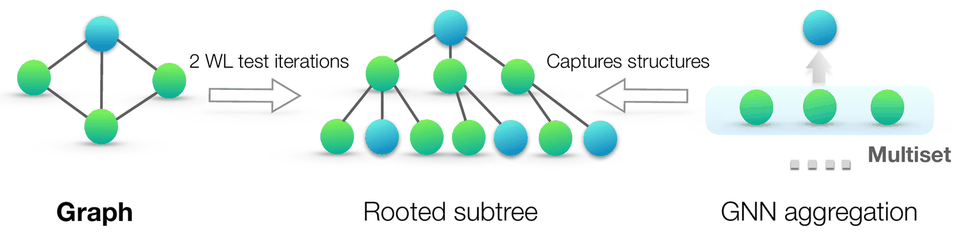

***From WL to GNNs.** Two WL iterations on the graph (left) correspond to the **rooted subtree** of each node (middle): a node's WL colour after $t$ rounds encodes its depth-$t$ computation tree. If a GNN's aggregation captures the *full multiset* of neighbours (right), it maps different subtrees to different embeddings, recursively, and is as powerful as WL. Source: [Xu, Hu, Leskovec & Jegelka, *How Powerful are Graph Neural Networks?*, ICLR 2019](https://arxiv.org/abs/1810.00826).*

This is message passing with a perfect (injective) aggregate-and-update function, and that is the key result of the GIN paper:

* **Lemma 2 (upper bound).** If 1-WL cannot tell two graphs apart, **no message passing GNN can either.** Intuition: the 1-WL colour of a node after $t$ rounds encodes the node's whole depth-$t$ computation tree, and a GNN's output is a function of that same tree.
* **Theorem 3 (achievability).** A GNN matches 1-WL if its aggregation and update are **injective** on multisets, and so is its readout.
* **Lemma 5.** For countable features, **sum** can be injective on multisets ($h(X) = \sum_{x \in X} f(x)$ is unique for each multiset for some $f$). **Mean and max are not** (as we showed above).

This gives the **Graph Isomorphism Network**:

$$
\boxed{\;h_i' = \text{MLP}\Big( (1 + \epsilon)\, h_i + \sum_{j \in \mathcal{N}(i)} h_j \Big)\;}
$$

* **sum** aggregation, because it is injective on multisets.
* **an MLP** for the update, because by the universal approximation theorem an MLP can learn the injective functions ($f$ and the composition $\phi$) the theorem requires. A single linear layer + ReLU (as in GCN) is not enough.
* **$(1+\epsilon)$**, a scalar (learnable, or fixed at 0), so the node's own feature is weighted differently from the neighbour sum and the model can tell "my feature" apart from "one of my neighbours' features".

**What 1-WL (and so every MPNN) cannot do:** it cannot distinguish two graphs where every node has the same computation tree. Classic failure: all **regular graphs of the same degree and size** look identical, so it cannot count triangles or cycles. We will see the fix (structural / positional encodings) in Part 9.

Let's implement 1-WL and `GINConv` and compare them on three pairs of non-isomorphic graphs.

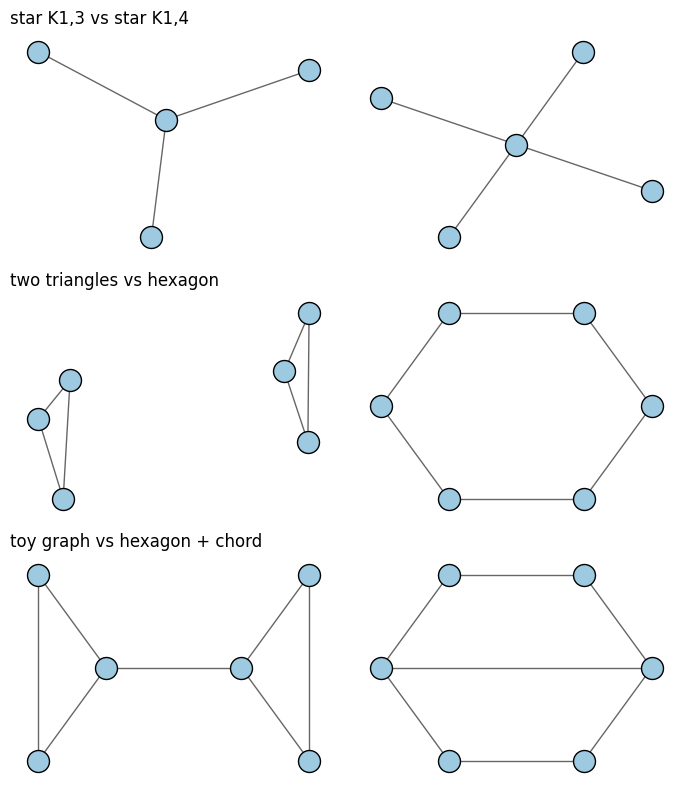

In [25]:
class GINConv(MessagePassing):
    def __init__(self, mlp: nn.Module, eps: float = 0.0, train_eps: bool = True):
        super().__init__(aggr="sum")
        self.mlp = mlp
        if train_eps:
            self.eps = nn.Parameter(torch.tensor([eps]))
        else:
            self.register_buffer("eps", torch.tensor([eps]))

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        # Sum of the neighbours (no self loops; the node itself enters through (1 + eps) * x)
        # Shape: (N, F_in) -> (N, F_in)
        neighbor_sum = self.propagate(edge_index, x)
        # Shape: (N, F_in) -> (N, F_out)
        return self.mlp((1 + self.eps) * x + neighbor_sum)


def wl_refinement(graphs, iterations: int = 3):
    # Run 1-WL on several graphs at once with a SHARED colour table, return the colour histogram per iteration.
    # graphs: list of (edge_index, num_nodes)
    colour_table = {}
    colours = [[0] * n for _, n in graphs]                   # same initial colour for every node
    histories = [[Counter(c)] for c in colours]
    for _ in range(iterations):
        new_colours = []
        for (edge_index, n), col in zip(graphs, colours):
            neighbours = [[] for _ in range(n)]
            for j, i in edge_index.t().tolist():
                neighbours[i].append(col[j])
            # signature = (own colour, sorted multiset of neighbour colours) -> new integer colour
            sigs = [(col[i], tuple(sorted(neighbours[i]))) for i in range(n)]
            new_colours.append([colour_table.setdefault(s, len(colour_table)) for s in sigs])
        colours = new_colours
        for hist, col in zip(histories, colours):
            hist.append(Counter(col))
    return histories


def wl_distinguishes(g1, g2, iterations: int = 4) -> bool:
    h1, h2 = wl_refinement([g1, g2], iterations)
    return any(a != b for a, b in zip(h1, h2))


def make_graph(edges, n):
    return to_undirected(torch.tensor(edges).t(), n), n


graph_pairs = {
    "star K1,3 vs star K1,4": (
        make_graph([(0, 1), (0, 2), (0, 3)], 4),
        make_graph([(0, 1), (0, 2), (0, 3), (0, 4)], 5)),
    "two triangles vs hexagon": (
        make_graph([(0, 1), (1, 2), (2, 0), (3, 4), (4, 5), (5, 3)], 6),
        make_graph([(i, (i + 1) % 6) for i in range(6)], 6)),
    "toy graph vs hexagon + chord": (
        (toy_edge_index, toy_num_nodes),
        make_graph([(i, (i + 1) % 6) for i in range(6)] + [(0, 3)], 6)),
}

# Layouts: spring layout by default, a circle for the hexagons, the usual layout for the toy graph
layouts = [(None, None), (None, nx.circular_layout(range(6))), (toy_pos, nx.circular_layout(range(6)))]
fig, axes = plt.subplots(len(graph_pairs), 2, figsize=(7, 8))
for row, (name, (g1, g2)) in enumerate(graph_pairs.items()):
    for col, (ei, n) in enumerate([g1, g2]):
        draw_graph(ei, n, ax=axes[row, col], node_size=250, labels=False, pos=layouts[row][col])
    axes[row, 0].set_title(name, loc="left")
plt.tight_layout()
plt.show()

In [26]:
def gin_mlp(dim_in, dim_out):
    return nn.Sequential(nn.Linear(dim_in, dim_out), nn.ReLU(), nn.Linear(dim_out, dim_out))


class TinyGNN(nn.Module):
    # 3 layers of either GIN (sum) or a mean-aggregation SAGE, followed by a sum or mean readout
    def __init__(self, kind: str, hidden: int = 16):
        super().__init__()
        self.kind = kind
        if kind == "gin":
            self.convs = nn.ModuleList([GINConv(gin_mlp(1 if l == 0 else hidden, hidden)) for l in range(3)])
        else:
            self.convs = nn.ModuleList([SAGEConv(1 if l == 0 else hidden, hidden, aggr=kind) for l in range(3)])

    def forward(self, edge_index, n):
        x = torch.ones(n, 1)                 # no features: every node starts identical
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
        return x.sum(0) if self.kind == "gin" else x.mean(0)


set_seed(0)
models = {"GIN (sum)": TinyGNN("gin"), "SAGE (mean)": TinyGNN("mean"), "SAGE (max-pool)": TinyGNN("pool")}
print(f"{'pair':32s}{'1-WL':>14s}" + "".join(f"{m:>18s}" for m in models))
with torch.no_grad():
    for name, (g1, g2) in graph_pairs.items():
        row = f"{name:32s}{'distinct' if wl_distinguishes(g1, g2) else 'SAME':>14s}"
        for model in models.values():
            same = torch.allclose(model(*g1), model(*g2), atol=1e-5)
            row += f"{'SAME' if same else 'distinct':>18s}"
        print(row)

pair                                      1-WL         GIN (sum)       SAGE (mean)   SAGE (max-pool)
star K1,3 vs star K1,4                distinct          distinct              SAME              SAME
two triangles vs hexagon                  SAME              SAME              SAME              SAME
toy graph vs hexagon + chord              SAME              SAME              SAME              SAME


Reading the table:

* **Stars**: 1-WL separates them (the centre has degree 3 vs 4). An untrained GIN already separates them because sum aggregation counts neighbours. Mean and max aggregation cannot: with identical features, the mean (or max) of 3 neighbours equals the mean of 4.
* **Two triangles vs hexagon** and **toy graph vs hexagon + chord**: every node has an identical computation tree (the graphs in each pair have the same degree sequence and every node sees the same multiset of neighbour degrees), so 1-WL fails and **so does every message passing GNN**, including GIN. This is not a training problem; no weights can fix it. Note the left graphs contain triangles and the right ones don't, so **message passing GNNs cannot count triangles**.

# Part 5: Node classification on Cora

**Cora** is the "MNIST of GNNs": a citation network of 2,708 machine learning papers, each described by a 1,433-dimensional binary bag-of-words vector, and labelled with one of 7 topics (Neural Networks, Rule Learning, Reinforcement Learning, ...). Edges are citations, which we treat as undirected.

The task is **semi-supervised**, **transductive** node classification: we see the whole graph (all features and all edges), but labels for only **20 papers per class** (140 in total, 5% of the nodes). The model has to propagate the label information through the citation structure. We follow the standard protocol of Kipf & Welling: 20 labelled nodes per class for training, 500 for validation (model selection), 1,000 for testing. (The official "Planetoid" split uses one specific set of indices; we draw ours at random with a fixed seed from the original LINQS release of the data, so numbers are comparable but not identical to the papers.)

## A container for graph data

We use one small dataclass for every graph in the notebook: a single big graph like Cora, or one small molecule in Part 7.

In [27]:
@dataclass
class Graph:
    x: torch.Tensor                          # (N, F) node features
    edge_index: torch.Tensor                 # (2, E) edges, source -> target
    y: torch.Tensor = None                   # (N,) node labels or (1,) graph label
    train_mask: torch.Tensor = None          # (N,) bool, node-level splits
    val_mask: torch.Tensor = None
    test_mask: torch.Tensor = None

    @property
    def num_nodes(self) -> int:
        return self.x.size(0)

    @property
    def num_edges(self) -> int:
        return self.edge_index.size(1)

    def to(self, device):
        for name, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, name, value.to(device))
        return self

## Downloading and parsing Cora

The LINQS release has two text files:

* `cora.content`: one line per paper, `<paper_id> <1433 binary word features> <class_label>`
* `cora.cites`: one line per citation, `<cited_paper_id> <citing_paper_id>`

Paper IDs are arbitrary integers, so we map them to node indices $0..N-1$. Following Kipf & Welling we **row-normalize** the features (each row sums to 1), which keeps papers with many words from dominating.

In [28]:
def download(url: str, path: Path):
    if not path.exists():
        print(f"downloading {url}")
        urllib.request.urlretrieve(url, path)


def load_cora(root: Path = DATA_DIR, num_train_per_class: int = 20, num_val: int = 500,
              num_test: int = 1000, seed: int = 0) -> Graph:
    archive = root / "cora.tgz"
    download("https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz", archive)
    if not (root / "cora").exists():
        with tarfile.open(archive) as tar:
            tar.extractall(root)

    # --- nodes: features and labels ---
    rows = [line.split() for line in open(root / "cora" / "cora.content")]
    paper_ids = [r[0] for r in rows]
    id_to_index = {pid: i for i, pid in enumerate(paper_ids)}
    x = torch.tensor([[float(v) for v in r[1:-1]] for r in rows])          # (N, 1433) binary
    class_names = sorted(set(r[-1] for r in rows))
    y = torch.tensor([class_names.index(r[-1]) for r in rows])             # (N,)

    # --- edges: citations, made undirected, without self loops ---
    cites = [line.split() for line in open(root / "cora" / "cora.cites")]
    edges = [(id_to_index[citing], id_to_index[cited]) for cited, citing in cites
             if cited in id_to_index and citing in id_to_index]
    edge_index = to_undirected(torch.tensor(edges).t(), len(rows))
    edge_index = remove_self_loops(edge_index)

    # --- features: row-normalize so every row sums to 1 ---
    x = x / x.sum(dim=1, keepdim=True).clamp(min=1)

    # --- splits: 20 per class for training, then 500 val and 1000 test from the rest ---
    generator = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(rows), generator=generator)
    train_idx = torch.cat([perm[y[perm] == c][:num_train_per_class] for c in range(len(class_names))])
    rest = perm[~torch.isin(perm, train_idx)]
    val_idx, test_idx = rest[:num_val], rest[num_val:num_val + num_test]
    masks = []
    for idx in [train_idx, val_idx, test_idx]:
        mask = torch.zeros(len(rows), dtype=torch.bool)
        mask[idx] = True
        masks.append(mask)

    graph = Graph(x=x, edge_index=edge_index, y=y, train_mask=masks[0], val_mask=masks[1], test_mask=masks[2])
    graph.class_names = class_names
    return graph


cora = load_cora()
print(f"nodes: {cora.num_nodes}, directed edges: {cora.num_edges} ({cora.num_edges // 2} undirected)")
print(f"features: {cora.x.size(1)}, classes: {len(cora.class_names)}")
print(f"train / val / test: {cora.train_mask.sum().item()} / {cora.val_mask.sum().item()} / {cora.test_mask.sum().item()}")
print("classes:", cora.class_names)

nodes: 2708, directed edges: 10556 (5278 undirected)
features: 1433, classes: 7
train / val / test: 140 / 500 / 1000
classes: ['Case_Based', 'Genetic_Algorithms', 'Neural_Networks', 'Probabilistic_Methods', 'Reinforcement_Learning', 'Rule_Learning', 'Theory']


## Why should a GNN work here? Homophily

GNNs (and especially GCN, a low-pass filter) work best on **homophilous** graphs, where connected nodes tend to share a label: papers cite papers on the same topic. We measure this with the **edge homophily ratio**, the fraction of edges whose endpoints share a label:

$$
h = \frac{\lvert\{(j, i) \in E : y_i = y_j\}\rvert}{\lvert E \rvert}
$$

If $h$ is high, smoothing features over neighbours averages away noise without mixing classes. If $h$ is low (heterophily: e.g. fraudsters connecting to normal users), plain low-pass GNNs can do *worse* than an MLP, and you want architectures that keep the self and neighbour signals separate (like SAGE's two weight matrices) or that can learn high-pass filters.

We also look at the degree distribution. Like most real networks it is heavy-tailed: most papers have a handful of citations and a few have over a hundred. That is why degree normalization matters.

edge homophily: 0.810  (a random labelling would give ~0.180)
degree: mean 3.90, median 3, max 168
isolated nodes: 0, connected components: 78


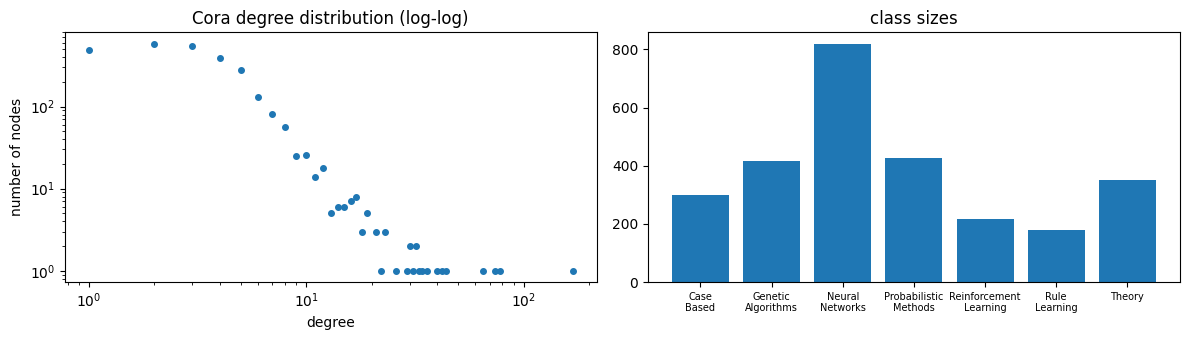

In [29]:
def edge_homophily(edge_index, y):
    return (y[edge_index[0]] == y[edge_index[1]]).float().mean().item()


def count_components(edge_index, num_nodes):
    g = nx.Graph()
    g.add_nodes_from(range(num_nodes))
    g.add_edges_from(edge_index.t().tolist())
    return nx.number_connected_components(g)


cora_deg = degree(cora.edge_index[1], cora.num_nodes)
print(f"edge homophily: {edge_homophily(cora.edge_index, cora.y):.3f}  "
      f"(a random labelling would give ~{(torch.bincount(cora.y).float() / cora.num_nodes).pow(2).sum():.3f})")
print(f"degree: mean {cora_deg.mean():.2f}, median {cora_deg.median():.0f}, max {cora_deg.max():.0f}")
print(f"isolated nodes: {(cora_deg == 0).sum().item()}, connected components: {count_components(cora.edge_index, cora.num_nodes)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
values, counts = torch.unique(cora_deg, return_counts=True)
axes[0].loglog(values, counts, "o", markersize=4)
axes[0].set_xlabel("degree")
axes[0].set_ylabel("number of nodes")
axes[0].set_title("Cora degree distribution (log-log)")
axes[1].bar(range(len(cora.class_names)), torch.bincount(cora.y))
axes[1].set_xticks(range(len(cora.class_names)))
axes[1].set_xticklabels([c.replace("_", "\n") for c in cora.class_names], fontsize=7)
axes[1].set_title("class sizes")
plt.tight_layout()
plt.show()

## One model class for all four approaches

All models have the same two-layer shape so the comparison is fair:

$$
\text{logits} = \text{Layer}_2\Big(\text{dropout}\big(\sigma(\text{Layer}_1(\text{dropout}(X)))\big)\Big)
$$

| Model | Layer | Hidden size | Notes |
|---|---|---|---|
| MLP | `nn.Linear` | 16 | **ignores the graph entirely**: our baseline |
| GCN | `GCNConv` | 16 | Kipf & Welling hyperparameters: dropout 0.5, lr 0.01, weight decay 5e-4 |
| GraphSAGE | `SAGEConv` (mean) | 16 | trained with **neighbour sampling** (fanout 10), full neighbourhood at test time |
| GAT | `GATConv` | 8 heads x 8 | Veličković et al.: ELU, dropout 0.6 (inputs and attention), lr 0.005; output layer has 1 head |

With only 140 labels, overfitting is the main enemy, which is why dropout and weight decay are so aggressive.

In [30]:
class NodeClassifier(nn.Module):
    def __init__(self, kind: str, in_dim: int, hidden_dim: int, out_dim: int, dropout: float = 0.5, heads: int = 8):
        super().__init__()
        self.kind, self.dropout = kind, dropout
        if kind == "mlp":
            self.layer1, self.layer2 = nn.Linear(in_dim, hidden_dim), nn.Linear(hidden_dim, out_dim)
        elif kind == "gcn":
            # cached=True: the graph never changes, so compute the normalization once
            self.layer1 = GCNConv(in_dim, hidden_dim, cached=True)
            self.layer2 = GCNConv(hidden_dim, out_dim, cached=True)
        elif kind == "sage":
            self.layer1, self.layer2 = SAGEConv(in_dim, hidden_dim), SAGEConv(hidden_dim, out_dim)
        elif kind == "gat":
            # hidden: `heads` heads of size hidden_dim, concatenated -> heads * hidden_dim
            self.layer1 = GATConv(in_dim, hidden_dim, heads=heads, dropout=dropout)
            # output: a single head producing the class logits
            self.layer2 = GATConv(hidden_dim * heads, out_dim, heads=1, concat=False, dropout=dropout)
        else:
            raise ValueError(kind)

    def apply_layer(self, layer, x, edge_index):
        return layer(x) if self.kind == "mlp" else layer(x, edge_index)

    def forward(self, x, edge_index):
        # (N, F_in) -> (N, hidden) -> (N, num_classes)
        x = F.dropout(x, self.dropout, self.training)
        x = self.apply_layer(self.layer1, x, edge_index)
        x = F.elu(x) if self.kind == "gat" else F.relu(x)
        self.hidden = x                     # kept for visualization
        x = F.dropout(x, self.dropout, self.training)
        return self.apply_layer(self.layer2, x, edge_index)

## The training loop

Transductive training is **full-batch**: every step runs the model on the entire graph (all 2,708 nodes), but the loss only uses the 140 training nodes:

$$
\mathcal{L} = -\frac{1}{\lvert \mathcal{V}_{\text{train}} \rvert} \sum_{i \in \mathcal{V}_{\text{train}}} \log \operatorname{softmax}(\text{logits}_i)_{y_i}
$$

The unlabelled nodes still matter: their features flow into the labelled nodes' representations through message passing. That is the "semi-supervised" part.

We keep the weights with the best validation accuracy (ties broken by validation loss) and report the test accuracy of that checkpoint. For GraphSAGE we resample the neighbourhoods every epoch.

In [31]:
@torch.no_grad()
def evaluate_nodes(model, graph):
    model.eval()
    logits = model(graph.x, graph.edge_index)
    pred = logits.argmax(dim=-1)
    result = {}
    for split in ["train", "val", "test"]:
        mask = getattr(graph, f"{split}_mask")
        result[f"{split}_acc"] = (pred[mask] == graph.y[mask]).float().mean().item()
    result["val_loss"] = F.cross_entropy(logits[graph.val_mask], graph.y[graph.val_mask]).item()
    return result


def train_node_classifier(model, graph, epochs=200, lr=0.01, weight_decay=5e-4, fanout=None):
    model = model.to(device)
    graph = graph.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best, best_state = [], None, None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        # GraphSAGE: a fresh random neighbourhood sample every step
        edge_index = sample_neighbors(graph.edge_index, graph.num_nodes, fanout) if fanout else graph.edge_index
        logits = model(graph.x, edge_index)
        # Only the labelled training nodes contribute to the loss
        loss = F.cross_entropy(logits[graph.train_mask], graph.y[graph.train_mask])
        loss.backward()
        optimizer.step()

        metrics = evaluate_nodes(model, graph)
        metrics["train_loss"] = loss.item()
        history.append(metrics)
        key = (metrics["val_acc"], -metrics["val_loss"])
        if best is None or key > best:
            best = key
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_metrics = metrics
    model.load_state_dict(best_state)
    return history, best_metrics


node_configs = {
    "MLP":       dict(kind="mlp",  hidden_dim=16, dropout=0.5, lr=0.01,  fanout=None),
    "GCN":       dict(kind="gcn",  hidden_dim=16, dropout=0.5, lr=0.01,  fanout=None),
    "GraphSAGE": dict(kind="sage", hidden_dim=16, dropout=0.5, lr=0.01,  fanout=10),
    "GAT":       dict(kind="gat",  hidden_dim=8,  dropout=0.6, lr=0.005, fanout=None),
}
num_classes = len(cora.class_names)
seeds = [0, 1, 2, 3, 4]
results, histories, trained = {}, {}, {}
for name, cfg in node_configs.items():
    test_accs = []
    for seed in seeds:
        set_seed(seed)
        model = NodeClassifier(cfg["kind"], cora.x.size(1), cfg["hidden_dim"], num_classes, dropout=cfg["dropout"])
        history, best = train_node_classifier(model, cora, lr=cfg["lr"], fanout=cfg["fanout"])
        test_accs.append(best["test_acc"])
        if seed == 0:
            histories[name], trained[name] = history, model
    results[name] = torch.tensor(test_accs)
    print(f"{name:10s} test accuracy: {results[name].mean():.3f} +/- {results[name].std():.3f}   (5 seeds)")

MLP        test accuracy: 0.558 +/- 0.008   (5 seeds)
GCN        test accuracy: 0.780 +/- 0.005   (5 seeds)
GraphSAGE  test accuracy: 0.772 +/- 0.012   (5 seeds)
GAT        test accuracy: 0.796 +/- 0.007   (5 seeds)


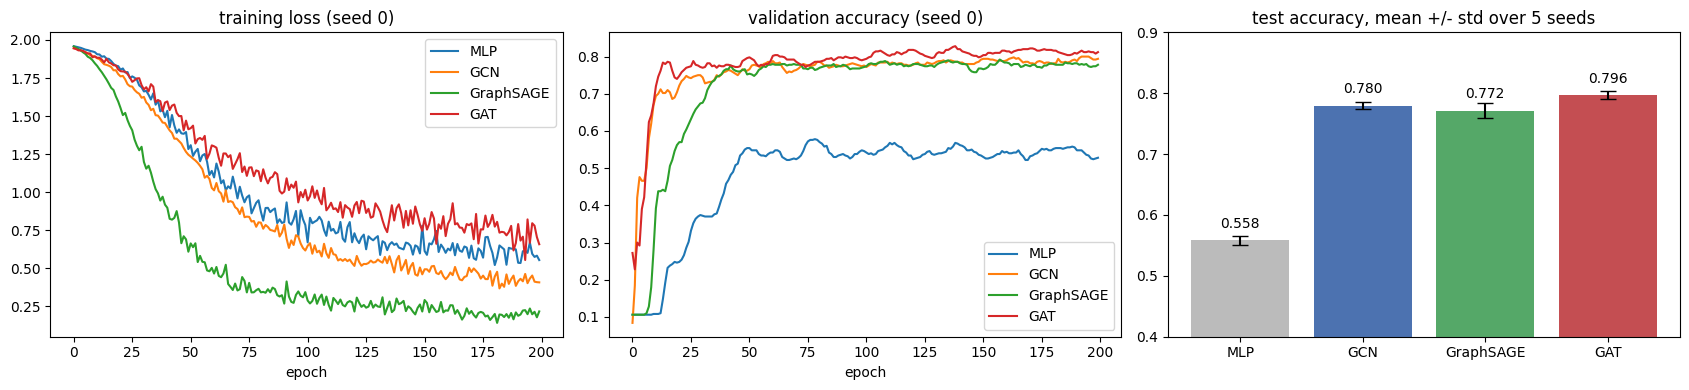

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, history in histories.items():
    axes[0].plot([h["train_loss"] for h in history], label=name)
    axes[1].plot([h["val_acc"] for h in history], label=name)
axes[0].set_title("training loss (seed 0)")
axes[1].set_title("validation accuracy (seed 0)")
for ax in axes[:2]:
    ax.set_xlabel("epoch")
    ax.legend()
names = list(results)
axes[2].bar(names, [results[n].mean() for n in names], yerr=[results[n].std() for n in names], capsize=6,
            color=["#bbbbbb", "#4c72b0", "#55a868", "#c44e52"])
axes[2].set_ylim(0.4, 0.9)
axes[2].set_title("test accuracy, mean +/- std over 5 seeds")
for i, n in enumerate(names):
    axes[2].text(i, results[n].mean() + 0.02, f"{results[n].mean():.3f}", ha="center")
plt.tight_layout()
plt.show()

What the results say:

* **The graph is worth more than 20 accuracy points.** The MLP only sees each paper's own words and reaches about 56%. Every GNN reaches 77-80% with the *same* 140 labels and a model of the same size. 81% of edges connect papers with the same topic, so averaging over neighbours is a very good prior.
* **GCN, GraphSAGE and GAT end up close together** (within about 2 points). Our numbers are a bit below the papers (GCN 81.5%, GAT 83.0%) because we use a random split instead of the fixed Planetoid indices, and we did no tuning, but the ordering MLP << GraphSAGE ~ GCN < GAT matches the literature.
* **GraphSAGE drives its training loss lowest but does not generalize better.** With its separate self-weight $W_{\text{self}}$ it can fit the 140 labelled nodes from their own features more easily (closer to an MLP), so it overfits slightly more than GCN, whose self-loop forces each node to be averaged with its neighbours.

## Looking inside: what did message passing change?

Same hidden size, same training labels, same optimizer: the only difference between the MLP and the GCN is $\hat{A}$. Below we project the 16-dimensional hidden representations of all 2,708 papers into 2-D with t-SNE, coloured by the true topic (which the model only saw for 140 of them).

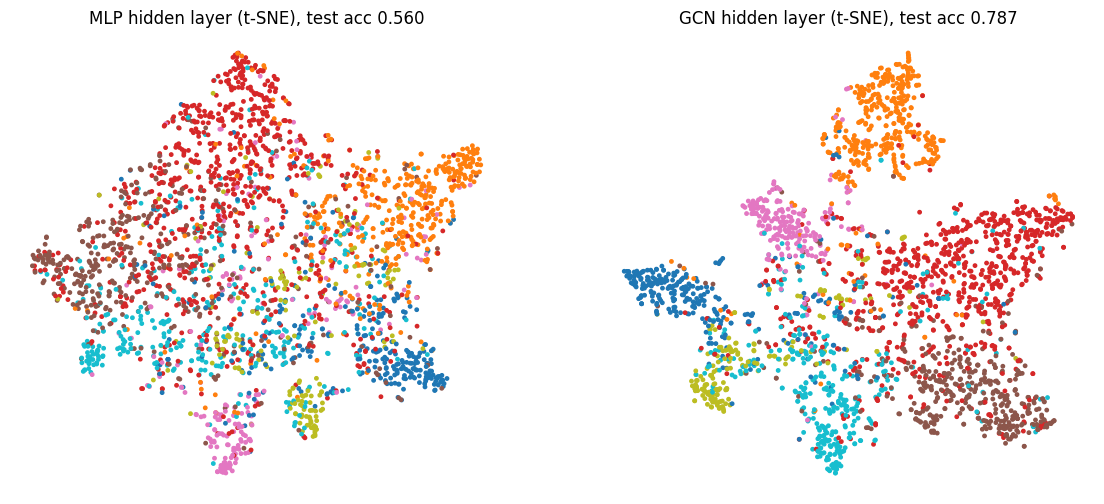

In [33]:
from sklearn.manifold import TSNE  # visualization only

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["MLP", "GCN"]):
    model = trained[name]
    model.eval()
    with torch.no_grad():
        model(cora.x, cora.edge_index)
    with np.errstate(all="ignore"):  # numpy 2 + macOS Accelerate emits spurious matmul warnings in PCA init
        emb = TSNE(n_components=2, init="pca", random_state=0).fit_transform(model.hidden.cpu().numpy())
    ax.scatter(emb[:, 0], emb[:, 1], c=cora.y.cpu(), cmap="tab10", s=6)
    ax.set_title(f"{name} hidden layer (t-SNE), test acc {results[name][0]:.3f}")
    ax.axis("off")
plt.show()

In the MLP's hidden space the topics overlap heavily. After two rounds of GCN propagation the same papers form clearly separated clusters. Message passing has pulled each paper towards the papers it cites, and because citations mostly stay within a topic, the clusters tighten.

## What did GAT's attention learn?

For every node we compare the entropy of its attention distribution (averaged over the 8 heads of the first layer) with the entropy of a **uniform** distribution over its neighbourhood, $\log(d_i + 1)$. If GAT learned to focus on a few neighbours, its entropy would be much lower than uniform. We also measure how much attention lands on neighbours with the **same label**, compared with what uniform weights would give.

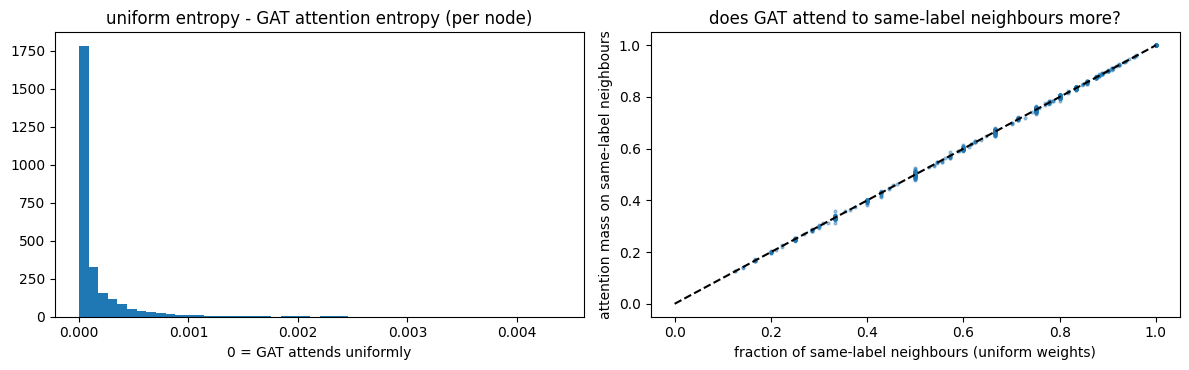

mean entropy gap: 0.0002 nats (uniform entropy averages 1.412 nats)
attention mass on same-label neighbours: 0.8709 vs 0.8708 with uniform weights


In [34]:
gat_model = trained["GAT"]
gat_model.eval()
with torch.no_grad():
    gat_model(cora.x, cora.edge_index)
att_edge_index, att = gat_model.layer1.last_attention          # (2, E + N), (E + N, heads)
att = att.mean(dim=1)                                            # average over heads -> (E + N,)
src, dst = att_edge_index

# Entropy of each node's attention distribution: -sum_j alpha_ij log alpha_ij
entropy = scatter(-att * torch.log(att + 1e-16), dst, cora.num_nodes)
uniform_entropy = torch.log(degree(dst, cora.num_nodes))         # degree here includes the self loop
mask = degree(dst, cora.num_nodes) > 1                           # skip nodes whose only edge is the self loop

same_label = (cora.y[src] == cora.y[dst]).float()
att_same = scatter(att * same_label, dst, cora.num_nodes)        # attention mass on same-label neighbours
uni_same = scatter(same_label, dst, cora.num_nodes, reduce="mean")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist((uniform_entropy - entropy)[mask].cpu(), bins=50)
axes[0].set_title("uniform entropy - GAT attention entropy (per node)")
axes[0].set_xlabel("0 = GAT attends uniformly")
axes[1].scatter(uni_same[mask].cpu(), att_same[mask].cpu(), s=4, alpha=0.4)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("fraction of same-label neighbours (uniform weights)")
axes[1].set_ylabel("attention mass on same-label neighbours")
axes[1].set_title("does GAT attend to same-label neighbours more?")
plt.tight_layout()
plt.show()
print(f"mean entropy gap: {(uniform_entropy - entropy)[mask].mean():.4f} nats "
      f"(uniform entropy averages {uniform_entropy[mask].mean():.3f} nats)")
print(f"attention mass on same-label neighbours: {att_same[mask].mean():.4f} vs {uni_same[mask].mean():.4f} with uniform weights")

**GAT's attention on Cora is almost exactly uniform.** The entropy gap is a tiny fraction of a nat, and the attention mass on same-label neighbours is the same as with uniform weights. This is a known result (the DGL GAT tutorial and several follow-up papers observe the same thing on the citation datasets): the learned scores $e_{ij}$ barely vary, so $\alpha_{ij} \approx 1 / (d_i + 1)$. That is a **mean** over the neighbourhood, close to what GCN does.

So where does GAT's small edge come from? Mostly from **regularization and capacity**: 8 heads give 64 hidden units instead of 16, and dropout on the attention coefficients randomly removes neighbours at every step (like DropEdge). Attention pays off on graphs where **neighbours differ in relevance**. On the inductive PPI benchmark (protein interactions, 121 labels per node), GAT reaches 0.973 micro-F1 against 0.768 for GraphSAGE. Lesson: **always check whether your attention is actually attending** before reading meaning into it.

# Part 6: Over-smoothing: why deep GNNs fail

CNNs got better by going deeper (ResNet-152). Plain GNNs get **worse** after 2-3 layers. The spectral view from Part 2 explains why exactly.

Ignore the weights and nonlinearities for a moment: $K$ GCN layers apply $\hat{A}$ $K$ times. $\hat{A}$ is symmetric, so write it in its eigenbasis, $\hat{A} = \sum_k \mu_k v_k v_k^\top$ with $\mu_k = 1 - \tilde{\lambda}_k$. Then

$$
\hat{A}^K X = \sum_k \mu_k^K\, v_k v_k^\top X
$$

We showed the eigenvalues of $\hat{A}$ lie in $(-1, 1]$. For a connected graph with self-loops, $\mu = 1$ is a simple eigenvalue and every other $\lvert\mu_k\rvert < 1$, so $\mu_k^K \rightarrow 0$ for every component except the top one:

$$
\hat{A}^K X \;\xrightarrow{K \rightarrow \infty}\; v_1 v_1^\top X, \qquad v_1 = \frac{\tilde{D}^{1/2}\mathbf{1}}{\lVert \tilde{D}^{1/2}\mathbf{1} \rVert}
$$

(check: $\hat{A}\tilde{D}^{1/2}\mathbf{1} = \tilde{D}^{-1/2}\tilde{A}\mathbf{1} = \tilde{D}^{-1/2}\tilde{D}\mathbf{1} = \tilde{D}^{1/2}\mathbf{1}$.) Row $i$ of the limit is $\sqrt{\tilde{d}_i}\cdot c^\top$ for **one shared vector** $c^\top = v_1^\top X / \lVert\tilde{D}^{1/2}\mathbf{1}\rVert$. **Every node ends up with the same feature vector, scaled only by the square root of its degree.** All the information that distinguished the nodes, and so their classes, has been averaged away. This is **over-smoothing** (Li et al. 2018). In filter terms, $(1-\tilde{\lambda})^K$ becomes a filter so sharp that only the $\tilde{\lambda} = 0$ component survives.

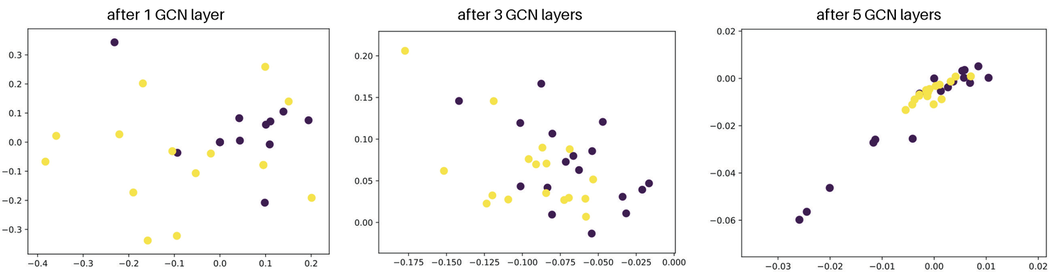

***Over-smoothing on the karate club.** Node embeddings from GCNs with 1, 3 and 5 layers (colours = the two clubs). As depth grows the points collapse onto a line through the origin: the features differ only by a per-node scale (our $\sqrt{\tilde{d}_i}$), and the two classes mix. Source: [Li, Han & Wu, *Deeper Insights into Graph Convolutional Networks for Semi-Supervised Learning*, AAAI 2018](https://arxiv.org/abs/1801.07606).*


(Cora has 78 connected components, so $\mu = 1$ has multiplicity 78 and the features converge to one shared vector *per component*, which is just as uninformative.)

We measure this two ways:

1. **Normalized Dirichlet energy** $\;E(X) = \dfrac{\operatorname{tr}\left(X^\top (I - \hat{A}) X\right)}{\operatorname{tr}(X^\top X)}$: how much the features still vary across edges, scale-free. It goes to 0 as $X$ converges to the null space of $I - \hat{A}$.
2. **Linear probe accuracy**: train a logistic regression on $\hat{A}^K X$. This is exactly the **SGC** model (Wu et al. 2019): $\operatorname{softmax}(\hat{A}^K X W)$, a GCN with the nonlinearities removed. It is strong for small $K$ and should collapse as $K$ grows.

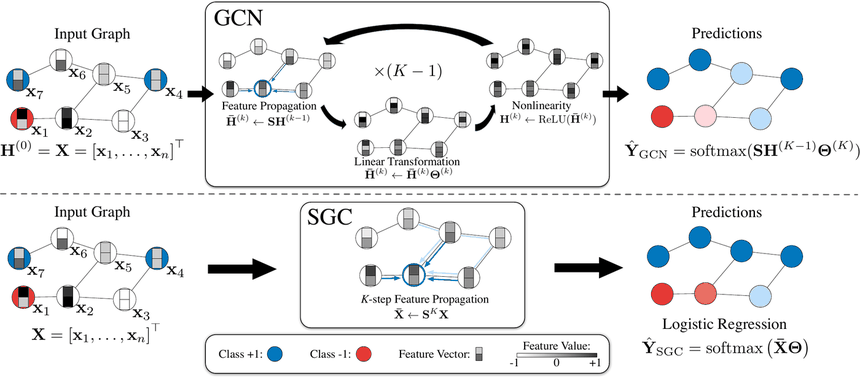

***GCN vs SGC.** A $K$-layer GCN alternates feature propagation ($\bar{H} \leftarrow S H$), a linear transformation and a ReLU. SGC removes the nonlinearities, so the whole network collapses into $K$ propagations of the input followed by a single logistic regression, $\hat{Y} = \operatorname{softmax}(S^K X \Theta)$. Source: [Wu et al., *Simplifying Graph Convolutional Networks*, ICML 2019](https://arxiv.org/abs/1902.07153).*


In [35]:
cora = cora.to(device)
cora_ei_sl, cora_norm = gcn_norm(cora.edge_index, cora.num_nodes)
propagator = MessagePassing(aggr="sum")
propagator.message = lambda x_i, x_j, norm, **kw: norm.unsqueeze(-1) * x_j


def propagate_A_hat(x):
    # One multiplication by A_hat, done with sparse message passing: (N, F) -> (N, F)
    return propagator.propagate(cora_ei_sl, x, norm=cora_norm)


def normalized_dirichlet_energy(x):
    # tr(X^T (I - A_hat) X) / tr(X^T X)
    return ((x * x).sum() - (x * propagate_A_hat(x)).sum()) / (x * x).sum()


def linear_probe(features, graph, epochs=200, lr=0.2, weight_decay=5e-5):
    # SGC: logistic regression on (pre-propagated) features, best validation epoch -> test accuracy
    set_seed(0)
    clf = nn.Linear(features.size(1), int(graph.y.max()) + 1).to(features.device)
    opt = optim.Adam(clf.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_test = 0, 0
    for _ in range(epochs):
        opt.zero_grad()
        F.cross_entropy(clf(features[graph.train_mask]), graph.y[graph.train_mask]).backward()
        opt.step()
        with torch.no_grad():
            pred = clf(features).argmax(-1)
            val = (pred[graph.val_mask] == graph.y[graph.val_mask]).float().mean().item()
            test = (pred[graph.test_mask] == graph.y[graph.test_mask]).float().mean().item()
        if val > best_val:
            best_val, best_test = val, test
    return best_test


# Largest connected component, to measure how similar the node features become
g_nx = nx.Graph()
g_nx.add_edges_from(cora.edge_index.t().tolist())
largest_cc = torch.tensor(sorted(max(nx.connected_components(g_nx), key=len)))

ks = [0, 1, 2, 4, 8, 16, 32, 64, 128, 256]
energies, probe_accs, cosines = [], [], []
x_k = cora.x
for k in range(max(ks) + 1):
    if k in ks:
        energies.append(normalized_dirichlet_energy(x_k).item())
        probe_accs.append(linear_probe(x_k, cora))
        # mean cosine similarity of each node's features to the component's average direction
        rows = F.normalize(x_k[largest_cc], dim=1)
        cosines.append((rows @ F.normalize(rows.mean(0), dim=0)).mean().item())
    x_k = propagate_A_hat(x_k)

for k, e, a, c in zip(ks, energies, probe_accs, cosines):
    print(f"K={k:4d}   energy={e:.4f}   cosine-to-mean={c:.3f}   SGC test acc={a:.3f}")

K=   0   energy=0.6167   cosine-to-mean=0.241   SGC test acc=0.543
K=   1   energy=0.2148   cosine-to-mean=0.384   SGC test acc=0.745
K=   2   energy=0.1038   cosine-to-mean=0.490   SGC test acc=0.781
K=   4   energy=0.0457   cosine-to-mean=0.596   SGC test acc=0.779
K=   8   energy=0.0188   cosine-to-mean=0.707   SGC test acc=0.776
K=  16   energy=0.0068   cosine-to-mean=0.813   SGC test acc=0.767
K=  32   energy=0.0022   cosine-to-mean=0.898   SGC test acc=0.730
K=  64   energy=0.0006   cosine-to-mean=0.954   SGC test acc=0.614
K= 128   energy=0.0001   cosine-to-mean=0.982   SGC test acc=0.348
K= 256   energy=0.0000   cosine-to-mean=0.995   SGC test acc=0.236


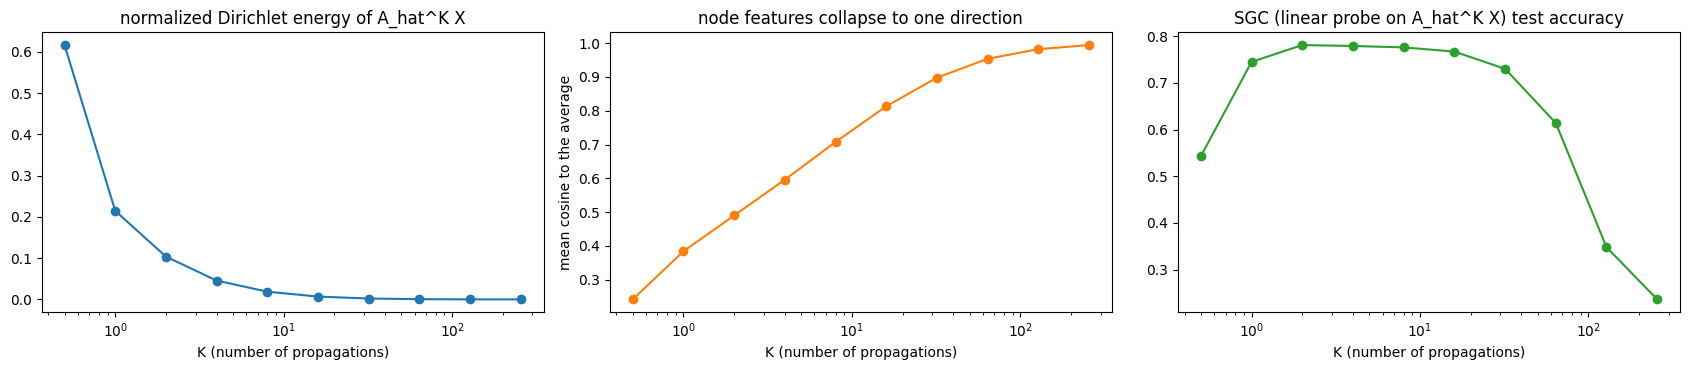

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
x_axis = [max(k, 0.5) for k in ks]   # so K=0 shows up on a log axis
axes[0].semilogx(x_axis, energies, "o-")
axes[0].set_title("normalized Dirichlet energy of A_hat^K X")
axes[1].semilogx(x_axis, cosines, "o-", color="tab:orange")
axes[1].set_title("node features collapse to one direction")
axes[1].set_ylabel("mean cosine to the average")
axes[2].semilogx(x_axis, probe_accs, "o-", color="tab:green")
axes[2].set_title("SGC (linear probe on A_hat^K X) test accuracy")
for ax in axes:
    ax.set_xlabel("K (number of propagations)")
plt.tight_layout()
plt.show()

The three curves tell one story:

* **A few propagations help a lot.** Plain logistic regression on the raw features ($K=0$) is our MLP baseline; two hops of smoothing ($K=2$) lift a *linear* model to the level of the 2-layer GCN. This is the SGC paper's point: on homophilous graphs most of GCN's power is the low-pass filter, not the nonlinearity.
* **Then the filter destroys the signal.** The energy falls towards 0 and the node features align to a single direction (cosine to the mean approaching 1), and accuracy falls with them.

## Does training rescue a deep GCN? Residual connections

With learned weights between the propagations, can a deep GCN learn to fight the smoothing? We train GCNs of depth 2 to 32 (hidden size 64), once **plain** and once with **residual connections** on the hidden layers:

$$
H^{(l+1)} = H^{(l)} + \operatorname{ReLU}\left(\hat{A} H^{(l)} W^{(l)}\right)
$$

A residual connection keeps the un-propagated $H^{(l)}$ as one of the terms, so the network can always pass the high-frequency part of the signal forward. (Other fixes in the literature: PairNorm, DropEdge, jumping-knowledge connections, GCNII's initial residual + identity mapping.)

In [37]:
class DeepGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers, residual=False, dropout=0.5):
        super().__init__()
        self.residual, self.dropout = residual, dropout
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        self.convs = nn.ModuleList([GCNConv(dims[l], dims[l + 1], cached=True) for l in range(num_layers)])

    def forward(self, x, edge_index):
        for l, conv in enumerate(self.convs[:-1]):
            x_in = x
            x = F.dropout(x, self.dropout, self.training)
            x = F.relu(conv(x, edge_index))
            if self.residual and l > 0:       # hidden -> hidden layers only (dimensions match)
                x = x + x_in
        x = F.dropout(x, self.dropout, self.training)
        return self.convs[-1](x, edge_index)


depths = [2, 4, 8, 16, 32]
deep_results = {"plain": [], "residual": []}
deep_train_acc = {"plain": [], "residual": []}
for variant in deep_results:
    for depth in depths:
        set_seed(0)
        model = DeepGCN(cora.x.size(1), 64, num_classes, depth, residual=(variant == "residual"))
        history, best = train_node_classifier(model, cora, epochs=200, lr=0.01)
        deep_results[variant].append(best["test_acc"])
        # Best training accuracy reached at any epoch: can the model even fit its 140 labels?
        deep_train_acc[variant].append(max(h["train_acc"] for h in history))
        print(f"{variant:9s} depth {depth:2d}: test acc {best['test_acc']:.3f}   best train acc {deep_train_acc[variant][-1]:.3f}")

plain     depth  2: test acc 0.779   best train acc 1.000
plain     depth  4: test acc 0.770   best train acc 1.000
plain     depth  8: test acc 0.265   best train acc 0.257
plain     depth 16: test acc 0.249   best train acc 0.250
plain     depth 32: test acc 0.230   best train acc 0.250
residual  depth  2: test acc 0.779   best train acc 1.000
residual  depth  4: test acc 0.778   best train acc 1.000
residual  depth  8: test acc 0.769   best train acc 1.000
residual  depth 16: test acc 0.748   best train acc 0.993
residual  depth 32: test acc 0.238   best train acc 0.257


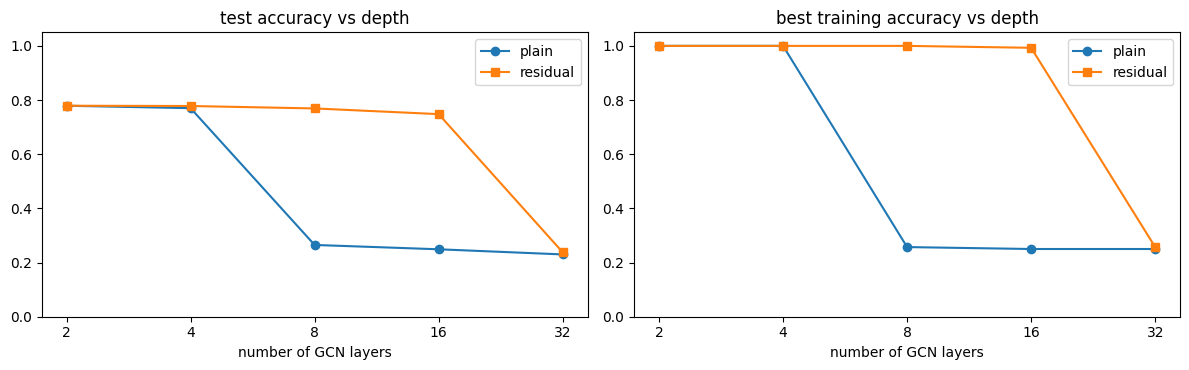

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for variant, marker in [("plain", "o-"), ("residual", "s-")]:
    axes[0].plot(depths, deep_results[variant], marker, label=variant)
    axes[1].plot(depths, deep_train_acc[variant], marker, label=variant)
axes[0].set_title("test accuracy vs depth")
axes[1].set_title("best training accuracy vs depth")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(depths)
    ax.set_xticklabels(depths)
    ax.set_xlabel("number of GCN layers")
    ax.set_ylim(0, 1.05)
    ax.legend()
plt.tight_layout()
plt.show()

**Plain GCN.** 2 and 4 layers work (78% / 77%). From 8 layers on, test accuracy drops to about 25%, no better than predicting a single class (the largest class is 30% of Cora). The training accuracy shows why: **the deep plain GCNs cannot even fit their 140 training nodes** (best training accuracy around 25%). So the failure of a *trained* deep GCN is not only that the representations over-smooth. It is also an **optimization** failure: the gradient has to flow back through 8+ normalized propagations, ReLUs and dropout layers, and it vanishes. Over-smoothing in the forward pass and vanishing gradients in the backward pass are two faces of the same repeated low-pass multiplication. Later work (e.g. Zhou et al. 2020, Cong et al. 2021) argues that in practice the training difficulty dominates.

**Residual GCN.** The identity path carries the signal forward and the gradient backward, exactly as in ResNets: training accuracy stays at 100% and test accuracy stays at about 77% up to 8 layers and 75% at 16. At 32 layers it fails too: plain residuals *delay* the problem rather than remove it. (GCNII adds an *initial* residual to $H^{(0)}$ plus identity mappings and trains 64+ layers.)

**Takeaway:** depth is not free in GNNs, and on Cora no deeper model beats the 2-layer GCN. If you need a larger receptive field, decouple propagation from depth (SGC, APPNP), use residual / jumping-knowledge connections, or add global attention (Part 9).

# Part 7: Graph classification on MUTAG

Now the prediction target is a **whole graph**. MUTAG is a classic chemistry benchmark: 188 nitroaromatic compounds, each labelled by whether it is **mutagenic** on the bacterium *Salmonella typhimurium*. Each molecule is a small graph (17.9 atoms on average) whose:

* **nodes** are atoms, with a one-hot feature for the atom type (C, N, O, F, I, Cl, Br),
* **edges** are bonds (with a one-hot bond type: aromatic, single, double, triple, which we will not use, following the GIN paper).

This brings three new problems:

1. **Many graphs**: how do we put graphs with different numbers of nodes into one mini-batch?
2. **Readout**: how do we turn a variable number of node embeddings into one fixed-size vector, in a permutation-invariant way?
3. **Small data**: 188 graphs, so we evaluate with **10-fold cross-validation**, the standard protocol for the TU datasets.

The data comes from the TU Dortmund graph collection (Morris et al. 2020). We load a JSON-lines mirror of it from the Hugging Face hub.

graphs: 188, classes: [63, 125]
atoms per molecule: mean 17.9, min 10, max 28
bonds per molecule: mean 19.8
every edge stored in both directions: True


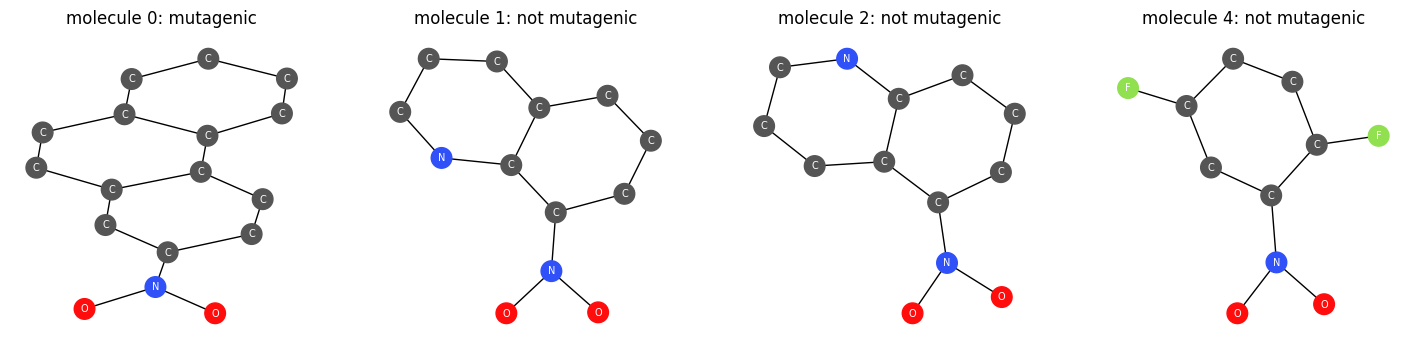

In [39]:
ATOM_TYPES = ["C", "N", "O", "F", "I", "Cl", "Br"]


def load_mutag(root: Path = DATA_DIR):
    path = root / "mutag.jsonl"
    download("https://huggingface.co/datasets/graphs-datasets/MUTAG/resolve/main/full.jsonl", path)
    graphs = []
    for line in open(path):
        record = json.loads(line)
        graph = Graph(
            x=torch.tensor(record["node_feat"], dtype=torch.float),        # (n, 7) one-hot atom type
            edge_index=torch.tensor(record["edge_index"], dtype=torch.long),  # (2, e), both directions stored
            y=torch.tensor(record["y"], dtype=torch.long),                 # (1,) mutagenic or not
        )
        graph.edge_attr = torch.tensor(record["edge_attr"], dtype=torch.float)  # (e, 4) bond type (unused)
        graphs.append(graph)
    return graphs


mutag = load_mutag()
num_nodes = torch.tensor([g.num_nodes for g in mutag], dtype=torch.float)
num_edges = torch.tensor([g.num_edges / 2 for g in mutag])
labels = torch.cat([g.y for g in mutag])
print(f"graphs: {len(mutag)}, classes: {torch.bincount(labels).tolist()}")
print(f"atoms per molecule: mean {num_nodes.mean():.1f}, min {num_nodes.min():.0f}, max {num_nodes.max():.0f}")
print(f"bonds per molecule: mean {num_edges.mean():.1f}")
print("every edge stored in both directions:",
      all(to_undirected(g.edge_index, g.num_nodes).size(1) == g.num_edges for g in mutag))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
atom_colours = ["#555555", "#3050f8", "#ff0d0d", "#90e050", "#940094", "#1ff01f", "#a62929"]
for ax, idx in zip(axes, [0, 1, 2, 4]):
    g = mutag[idx]
    atom = g.x.argmax(1)
    g_nx = nx.Graph()
    g_nx.add_nodes_from(range(g.num_nodes))   # add nodes first so their order matches `atom`
    g_nx.add_edges_from(g.edge_index.t().tolist())
    pos = nx.kamada_kawai_layout(g_nx)
    nx.draw_networkx_edges(g_nx, pos, ax=ax)
    nx.draw_networkx_nodes(g_nx, pos, ax=ax, node_color=[atom_colours[a] for a in atom], node_size=220)
    nx.draw_networkx_labels(g_nx, pos, labels={i: ATOM_TYPES[a] for i, a in enumerate(atom.tolist())},
                            font_color="white", font_size=7, ax=ax)
    ax.set_title(f"molecule {idx}: {'mutagenic' if g.y.item() == 1 else 'not mutagenic'}")
    ax.axis("off")
plt.show()

## Mini-batching graphs: one big disconnected graph

Images in a batch are stacked along a new dimension because they all have the same shape. Graphs do not. The standard trick is to **merge the $B$ graphs of a batch into one big graph with $B$ disconnected components**:

* concatenate the node feature matrices: $X = [X_1; X_2; \ldots; X_B]$, shape $(\sum_b n_b, F)$,
* concatenate the edge lists, **shifting each graph's node indices** by the number of nodes before it: graph $b$'s edges get $+\sum_{c<b} n_c$,
* keep a `batch` vector of shape $(\sum_b n_b,)$ that records which graph each node came from.

In matrix form the adjacency of the batch is **block diagonal**:

$$
A_{\text{batch}} = \begin{pmatrix} A_1 & & \\ & \ddots & \\ & & A_B \end{pmatrix}
$$

There are no edges between blocks, so **message passing on the big graph is exactly message passing on each graph independently**: no padding, no masking, no wasted computation. Then the readout pools nodes **per graph** using the `batch` vector as the scatter index.

x: (62, 7)  edge_index: (2, 138)  batch: (62,)  y: [1, 0, 0, 1]
nodes per graph: [17, 13, 13, 19]


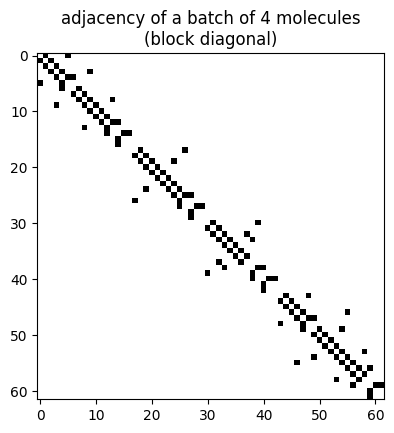

In [40]:
@dataclass
class GraphBatch:
    x: torch.Tensor            # (total_nodes, F)
    edge_index: torch.Tensor   # (2, total_edges), indices shifted per graph
    batch: torch.Tensor        # (total_nodes,) graph id of every node
    y: torch.Tensor            # (B,)
    num_graphs: int
    pe: torch.Tensor = None    # (total_nodes, K) optional positional encodings (Part 9)

    def to(self, device):
        for name, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, name, value.to(device))
        return self


def collate_graphs(graphs) -> GraphBatch:
    xs, edge_indices, batch_ids, ys, pes = [], [], [], [], []
    offset = 0
    for graph_id, g in enumerate(graphs):
        xs.append(g.x)
        edge_indices.append(g.edge_index + offset)          # shift node ids into this graph's block
        batch_ids.append(torch.full((g.num_nodes,), graph_id, dtype=torch.long))
        ys.append(g.y)
        if getattr(g, "pe", None) is not None:
            pes.append(g.pe)
        offset += g.num_nodes
    return GraphBatch(
        x=torch.cat(xs, dim=0),
        edge_index=torch.cat(edge_indices, dim=1),
        batch=torch.cat(batch_ids),
        y=torch.cat(ys),
        num_graphs=len(graphs),
        pe=torch.cat(pes, dim=0) if pes else None,
    )


example = collate_graphs(mutag[:4])
print("x:", tuple(example.x.shape), " edge_index:", tuple(example.edge_index.shape),
      " batch:", tuple(example.batch.shape), " y:", example.y.tolist())
print("nodes per graph:", torch.bincount(example.batch).tolist())
plt.figure(figsize=(4.5, 4.5))
plt.imshow(edge_index_to_adjacency(example.edge_index, example.x.size(0)), cmap="Greys")
plt.title("adjacency of a batch of 4 molecules\n(block diagonal)")
plt.show()

## Readout (global pooling)

The readout maps the node embeddings of graph $b$ to one vector, and must be permutation invariant:

$$
h_{G_b} = \sum_{i \in G_b} h_i \quad\text{(sum)} \qquad h_{G_b} = \frac{1}{n_b}\sum_{i \in G_b} h_i \quad\text{(mean)} \qquad h_{G_b} = \max_{i \in G_b} h_i \quad\text{(max, element-wise)}
$$

With the `batch` vector this is one `scatter` with `batch` as the index. The same expressivity argument as for aggregators applies: **sum** keeps the size of the graph and the counts of each node type (how many nitro groups does the molecule have?), mean only the proportions, max only which types are present. GIN uses sum.

**Jumping knowledge readout.** Early layers capture small substructures (atoms and their bonds), later layers larger ones. GIN pools *every* layer and concatenates:

$$
h_G = \Big\Vert_{l=0}^{L}\; \sum_{i \in G} h_i^{(l)}
$$

(More advanced *hierarchical* pooling methods, such as DiffPool, SAGPool and TopK pooling, coarsen the graph step by step like a CNN's pooling layers. Global pooling is the strong, simple baseline.)

In [41]:
def global_pool(x: torch.Tensor, batch: torch.Tensor, num_graphs: int, reduce: str = "sum") -> torch.Tensor:
    # Pool node embeddings into one vector per graph: (total_nodes, F) -> (B, F)
    return scatter(x, batch, num_graphs, reduce=reduce)


class GraphClassifier(nn.Module):
    def __init__(self, kind: str, in_dim: int, hidden_dim: int = 64, num_layers: int = 4, num_classes: int = 2,
                 dropout: float = 0.5, pe_dim: int = 0, heads: int = 4):
        super().__init__()
        self.kind = kind
        self.readout = "mean" if kind == "gcn" else "sum"
        self.node_encoder = nn.Linear(in_dim, hidden_dim)
        # Optional positional/structural encoding (Part 9), added to the node embedding
        self.pe_encoder = nn.Linear(pe_dim, hidden_dim) if pe_dim > 0 else None
        self.layers, self.norms = nn.ModuleList(), nn.ModuleList()
        for _ in range(num_layers):
            if kind == "gcn":
                self.layers.append(GCNConv(hidden_dim, hidden_dim))
            elif kind == "gin":
                mlp = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU(),
                                    nn.Linear(hidden_dim, hidden_dim))
                self.layers.append(GINConv(mlp, train_eps=True))
            elif kind == "gps":
                # Graph Transformer layer, defined in Part 9
                self.layers.append(GPSLayer(hidden_dim, heads=heads, dropout=dropout))
            # GIN gets BatchNorm (as in the paper). GCN's aggregation is already normalized by A_hat, and adding
            # BatchNorm on top made its evaluation unstable on these tiny test folds. GPS normalizes internally.
            self.norms.append(nn.BatchNorm1d(hidden_dim) if kind == "gin" else nn.Identity())
        # Jumping-knowledge readout: concatenate the pooled embedding of every layer (input included)
        self.head = nn.Sequential(nn.Linear((num_layers + 1) * hidden_dim, hidden_dim), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden_dim, num_classes))

    def forward(self, data: GraphBatch) -> torch.Tensor:
        h = self.node_encoder(data.x)                                  # (total_nodes, hidden)
        if self.pe_encoder is not None:
            h = h + self.pe_encoder(data.pe)
        readouts = [global_pool(h, data.batch, data.num_graphs, self.readout)]
        for layer, norm in zip(self.layers, self.norms):
            if self.kind == "gps":
                h = layer(h, data.edge_index, data.batch, data.num_graphs)
            else:
                h = F.relu(norm(layer(h, data.edge_index)))
            readouts.append(global_pool(h, data.batch, data.num_graphs, self.readout))   # (B, hidden)
        # (B, (num_layers + 1) * hidden) -> (B, num_classes)
        return self.head(torch.cat(readouts, dim=-1))


# Check: running a batch == running each graph on its own (the blocks really are independent)
set_seed(0)
model = GraphClassifier("gin", in_dim=7).eval()
with torch.no_grad():
    batched = model(collate_graphs(mutag[:8]))
    one_by_one = torch.cat([model(collate_graphs([g])) for g in mutag[:8]])
print("batched forward == graph-by-graph forward:", torch.allclose(batched, one_by_one, atol=1e-5))
print("logits shape (B, classes):", tuple(batched.shape))

batched forward == graph-by-graph forward: True
logits shape (B, classes): (8, 2)


## 10-fold cross-validation

With only 188 graphs a single train/test split is too noisy, so we use **stratified 10-fold cross-validation**: split the data into 10 folds with the same class balance, train on 9, test on the held-out one, rotate, and report the mean and standard deviation of the 10 test accuracies. Training follows the GIN paper's recipe (Adam, learning rate halved every 50 epochs, batch size 32, dropout 0.5) for 100 epochs, except that we use a learning rate of 0.001 instead of 0.01. With 0.01 the test accuracy of a fold jumped between ~33% (every graph predicted as the minority class) and ~90% from one epoch to the next, because BatchNorm's running statistics could not keep up with the large weight updates. We report the accuracy at the **last epoch** of every fold. (The GIN paper reports the epoch with the best accuracy *averaged over folds*, which is slightly optimistic; MUTAG numbers in the literature vary by several points for this reason.)

In [42]:
def stratified_folds(labels: torch.Tensor, k: int = 10, seed: int = 0):
    # Assign every graph to one of k folds, keeping the class ratio in every fold
    generator = torch.Generator().manual_seed(seed)
    fold_of = torch.empty(len(labels), dtype=torch.long)
    for c in labels.unique():
        idx = (labels == c).nonzero().squeeze(1)
        idx = idx[torch.randperm(len(idx), generator=generator)]
        fold_of[idx] = torch.arange(len(idx)) % k
    return [(fold_of != f).nonzero().squeeze(1).tolist() for f in range(k)], \
           [(fold_of == f).nonzero().squeeze(1).tolist() for f in range(k)]


@torch.no_grad()
def graph_accuracy(model, graphs, batch_size=64):
    model.eval()
    correct = 0
    for start in range(0, len(graphs), batch_size):
        data = collate_graphs(graphs[start:start + batch_size]).to(device)
        correct += (model(data).argmax(-1) == data.y).sum().item()
    return correct / len(graphs)


def cross_validate(make_model, graphs, k=10, epochs=100, batch_size=32, lr=0.001, seed=0, verbose=False):
    labels = torch.cat([g.y for g in graphs])
    train_folds, test_folds = stratified_folds(labels, k, seed)
    accs, curves = [], []
    for fold, (train_idx, test_idx) in enumerate(zip(train_folds, test_folds)):
        set_seed(seed + fold)
        model = make_model().to(device)
        optimizer = optim.Adam(model.parameters(), lr=lr)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)
        train_graphs = [graphs[i] for i in train_idx]
        test_graphs = [graphs[i] for i in test_idx]
        curve = []
        for epoch in range(epochs):
            model.train()
            order = torch.randperm(len(train_graphs)).tolist()
            for start in range(0, len(order), batch_size):
                data = collate_graphs([train_graphs[i] for i in order[start:start + batch_size]]).to(device)
                if data.num_graphs < 2:
                    continue     # BatchNorm needs more than one graph
                optimizer.zero_grad()
                loss = F.cross_entropy(model(data), data.y)
                loss.backward()
                optimizer.step()
            scheduler.step()
            curve.append(graph_accuracy(model, test_graphs))
        accs.append(curve[-1])
        curves.append(curve)
        if verbose:
            print(f"  fold {fold}: test acc {curve[-1]:.3f}")
    return torch.tensor(accs), torch.tensor(curves)


graph_results, graph_curves = {}, {}
for name, make in {
    "GCN + mean pool": lambda: GraphClassifier("gcn", in_dim=7),
    "GIN + sum pool": lambda: GraphClassifier("gin", in_dim=7),
}.items():
    graph_results[name], graph_curves[name] = cross_validate(make, mutag)
    print(f"{name:18s} 10-fold accuracy: {graph_results[name].mean():.3f} +/- {graph_results[name].std():.3f}")

GCN + mean pool    10-fold accuracy: 0.766 +/- 0.106
GIN + sum pool     10-fold accuracy: 0.858 +/- 0.093


**GIN + sum pooling beats GCN + mean pooling by about 9 points.** This is the expressivity argument from Part 4 showing up in a real task. Mutagenicity depends on *how many* of certain substructures a molecule has (nitro groups $\text{NO}_2$, fused aromatic rings, halogens). Mean aggregation and mean pooling only see proportions, so a molecule and a "doubled" version of it look the same. Sum aggregation, an MLP update and sum pooling keep the counts.

For reference, the GIN paper reports 89.4 ± 5.6 for GIN and 85.6 ± 5.8 for GCN on MUTAG. Our GIN is within the error bars. Our GCN is lower mainly because we gave it a mean readout to isolate the effect (the paper's GCN baseline uses a sum readout on these bioinformatics datasets).

**Look at the standard deviations.** Each test fold has 18-19 molecules, so a single misclassified graph moves a fold's accuracy by more than 5 points. Differences of a couple of points between models on MUTAG are noise. That is why we use 10 folds and report the spread.

# Part 8: Link prediction (edge-level tasks)

The third kind of task: **does an edge exist between $i$ and $j$?** This covers recommending friends or products, completing knowledge graphs, and predicting drug-target interactions. The standard recipe is an **encoder-decoder**:

$$
Z = \text{GNN}(X, A_{\text{train}}) \qquad\qquad \hat{p}_{ij} = \sigma\left(z_i^\top z_j\right)
$$

The GNN encodes every node into an embedding, and a simple decoder (here a dot product) scores pairs. Training is binary classification over **positive pairs** (edges we know) and **negative pairs** (random pairs of nodes, which are almost always non-edges in a sparse graph; this is **negative sampling**):

$$
\mathcal{L} = -\frac{1}{\lvert E^+ \rvert}\sum_{(i,j) \in E^+} \log \sigma(z_i^\top z_j) \;-\; \frac{1}{\lvert E^- \rvert}\sum_{(i,j) \in E^-} \log\left(1 - \sigma(z_i^\top z_j)\right)
$$

We draw fresh negatives every epoch, so the model sees many different non-edges.

### The leakage trap

We hide 5% of the edges for validation and 10% for testing. **The hidden edges must also be removed from the graph the GNN passes messages over.** If the test edge $(i, j)$ is still in $A$, then $i$ is literally a neighbour of $j$ during encoding, the embeddings $z_i$ and $z_j$ get mixed together, and the dot product is high "for free". The model gets to see the answer. We will measure how big that effect is.

We evaluate with **ROC-AUC**: the probability that a random true edge scores higher than a random non-edge (0.5 = chance, 1.0 = perfect). It equals the normalized Mann-Whitney U statistic, which we compute from ranks:

$$
\text{AUC} = \frac{\sum_{p \in \text{pos}} \operatorname{rank}(p) - \frac{n_+(n_+ + 1)}{2}}{n_+ \, n_-}
$$

In [43]:
def split_edges(edge_index, num_nodes, val_ratio=0.05, test_ratio=0.10, seed=0):
    # Work with each undirected edge once (i < j), split, then make the training graph undirected again
    generator = torch.Generator().manual_seed(seed)
    undirected = edge_index[:, edge_index[0] < edge_index[1]]
    undirected = undirected[:, torch.randperm(undirected.size(1), generator=generator)]
    n_val, n_test = int(val_ratio * undirected.size(1)), int(test_ratio * undirected.size(1))
    val_pos = undirected[:, :n_val]
    test_pos = undirected[:, n_val:n_val + n_test]
    train_pos = undirected[:, n_val + n_test:]
    return {
        "train_pos": train_pos,                                   # supervision for the training loss
        "train_graph": to_undirected(train_pos, num_nodes),       # the ONLY edges used for message passing
        "val_pos": val_pos,
        "test_pos": test_pos,
    }


def negative_sampling(edge_index, num_nodes, num_samples, generator=None):
    # Random node pairs that are not edges (and not self loops)
    existing = edge_index[0] * num_nodes + edge_index[1]
    samples = []
    count = 0
    while count < num_samples:
        pairs = torch.randint(0, num_nodes, (2, int(num_samples * 1.2) + 10), generator=generator)
        ids = pairs[0] * num_nodes + pairs[1]
        keep = (pairs[0] != pairs[1]) & ~torch.isin(ids, existing)
        samples.append(pairs[:, keep])
        count += keep.sum().item()
    return torch.cat(samples, dim=1)[:, :num_samples]


def roc_auc(pos_scores, neg_scores):
    # Mann-Whitney U: rank all scores together, sum the ranks of the positives
    scores = torch.cat([pos_scores, neg_scores])
    ranks = torch.empty_like(scores)
    ranks[scores.argsort()] = torch.arange(1, len(scores) + 1, dtype=scores.dtype, device=scores.device)
    n_pos, n_neg = len(pos_scores), len(neg_scores)
    return ((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)).item()


cora_cpu = cora.to("cpu")
link_split = split_edges(cora_cpu.edge_index, cora_cpu.num_nodes)
generator = torch.Generator().manual_seed(0)
# Fixed validation/test negatives, excluding ALL true edges
link_split["val_neg"] = negative_sampling(cora_cpu.edge_index, cora_cpu.num_nodes, link_split["val_pos"].size(1), generator)
link_split["test_neg"] = negative_sampling(cora_cpu.edge_index, cora_cpu.num_nodes, link_split["test_pos"].size(1), generator)
for key, value in link_split.items():
    print(f"{key:12s} {tuple(value.shape)}")
print("AUC sanity checks: perfect =", roc_auc(torch.tensor([2.0, 3.0]), torch.tensor([0.0, 1.0])),
      " inverted =", roc_auc(torch.tensor([0.0, 1.0]), torch.tensor([2.0, 3.0])))

train_pos    (2, 4488)
train_graph  (2, 8976)
val_pos      (2, 263)
test_pos     (2, 527)
val_neg      (2, 263)
test_neg     (2, 527)
AUC sanity checks: perfect = 1.0  inverted = 0.0


In [44]:
class LinkPredictor(nn.Module):
    def __init__(self, in_dim, hidden_dim=128, out_dim=64, use_graph=True, dropout=0.5):
        super().__init__()
        self.use_graph, self.dropout = use_graph, dropout
        if use_graph:
            self.layer1, self.layer2 = GCNConv(in_dim, hidden_dim), GCNConv(hidden_dim, out_dim)
        else:
            self.layer1, self.layer2 = nn.Linear(in_dim, hidden_dim), nn.Linear(hidden_dim, out_dim)

    def encode(self, x, edge_index):
        # (N, F) -> (N, out_dim) node embeddings
        x = F.dropout(x, self.dropout, self.training)
        x = F.relu(self.layer1(x, edge_index) if self.use_graph else self.layer1(x))
        x = F.dropout(x, self.dropout, self.training)
        return self.layer2(x, edge_index) if self.use_graph else self.layer2(x)

    @staticmethod
    def decode(z, pairs):
        # Dot product of the two endpoints: (N, D), (2, P) -> (P,) logits
        return (z[pairs[0]] * z[pairs[1]]).sum(dim=-1)


def train_link_predictor(model, graph, split, message_edges, epochs=200, lr=0.01):
    model = model.to(device)
    x = graph.x.to(device)
    message_edges = message_edges.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    best_val, best_test = 0, 0
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        z = model.encode(x, message_edges)
        pos = split["train_pos"].to(device)
        # Fresh negatives every epoch (excluding training edges; the model never sees val/test edges)
        neg = negative_sampling(split["train_graph"], graph.num_nodes, pos.size(1)).to(device)
        pos_logits, neg_logits = model.decode(z, pos), model.decode(z, neg)
        loss = F.binary_cross_entropy_with_logits(pos_logits, torch.ones_like(pos_logits)) + \
               F.binary_cross_entropy_with_logits(neg_logits, torch.zeros_like(neg_logits))
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            z = model.encode(x, message_edges)
            auc = {s: roc_auc(model.decode(z, split[f"{s}_pos"].to(device)), model.decode(z, split[f"{s}_neg"].to(device)))
                   for s in ["val", "test"]}
        if auc["val"] > best_val:
            best_val, best_test = auc["val"], auc["test"]
    return best_val, best_test


link_results = {}
for name, use_graph, message_edges in [
    ("MLP encoder (no graph)", False, link_split["train_graph"]),
    ("GCN encoder", True, link_split["train_graph"]),
    ("GCN encoder, LEAKED test edges", True, cora_cpu.edge_index),
]:
    set_seed(0)
    val_auc, test_auc = train_link_predictor(LinkPredictor(cora_cpu.x.size(1), use_graph=use_graph),
                                             cora_cpu, link_split, message_edges)
    link_results[name] = test_auc
    print(f"{name:32s} val AUC {val_auc:.3f}   test AUC {test_auc:.3f}")

MLP encoder (no graph)           val AUC 0.872   test AUC 0.856
GCN encoder                      val AUC 0.934   test AUC 0.933
GCN encoder, LEAKED test edges   val AUC 0.980   test AUC 0.981


* **MLP encoder, 0.856 AUC.** Features alone predict citations fairly well: papers that use the same words tend to cite each other.
* **GCN encoder, 0.933 AUC.** Message passing adds structure: two papers with many common neighbours receive almost the same messages, so their embeddings end up close and their dot product high. The GCN learns a soft version of classical link heuristics like "common neighbours" and Adamic-Adar.
* **Leaked GCN, 0.981 AUC.** Same model, same training, and the *only* difference is that the message-passing graph still contains the validation/test edges. That is about **5 AUC points of fake improvement**, and it is a one-character bug to make (passing `data.edge_index` instead of the training edges). Whenever a link-prediction result looks too good, check this first.

# Part 9: Graph Transformers

We saw in Part 4 that a Transformer is a GNN on the **complete graph**, and that GAT is attention **masked to the edges**. That suggests two opposite limitations:

* **Message passing GNNs** only ever talk to their neighbours. Information needs $K$ layers to travel $K$ hops (and over-smoothing stops us stacking many), long-range interactions get squashed through bottlenecks, and expressivity is capped at 1-WL.
* **A plain Transformer** lets every node talk to every node in one step, but the complete graph has **no structure at all**: run on node features alone, a Transformer is blind to which atoms are bonded. It is permutation equivariant, so it cannot even tell *where* a node is.

Graph Transformers combine the two. They need:

1. **Positional / structural encodings (PE/SE)** that tell attention where each node sits in the graph, the analogue of the sinusoidal positional encodings of notebook 09.
2. **An architecture** that mixes local message passing with global attention.


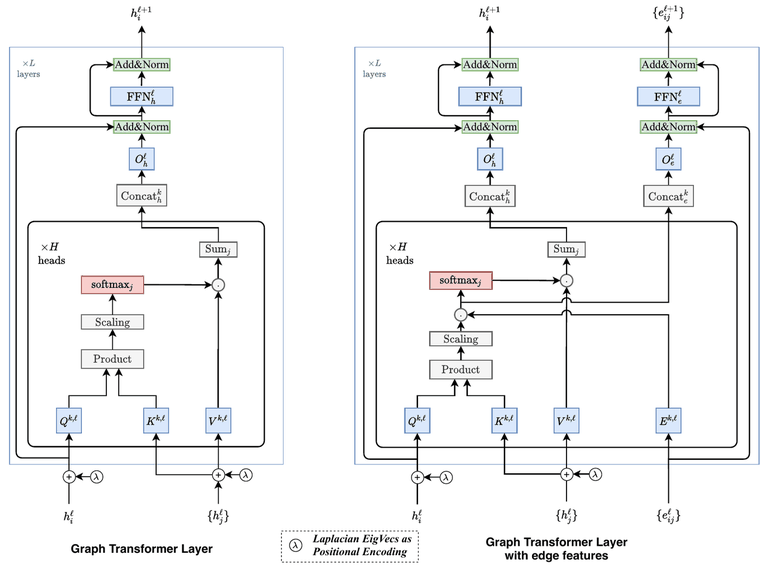

***The first Graph Transformer.** A Transformer layer (multi-head attention, Add & Norm, FFN) where attention is restricted to each node's graph neighbours and Laplacian eigenvectors are added to the input as positional encodings ($\lambda$ in the figure). The right variant also updates edge features. GPS (below) later combined *global* attention with a local MPNN. Source: [Dwivedi & Bresson, *A Generalization of Transformer Networks to Graphs*, AAAI DLG Workshop 2021](https://arxiv.org/abs/2012.09699).*

## Positional encodings for graphs

**Laplacian eigenvector PE** (Dwivedi & Bresson 2020). In Part 2 we saw that the Laplacian's eigenvectors are the graph's Fourier modes, and on a cycle (the graph of a sequence) they are exactly sines and cosines, the same functions as the Transformer's sinusoidal encoding. So the natural graph PE is: give node $i$ the vector $[u_2(i), u_3(i), \ldots, u_{k+1}(i)]$, the $k$ smoothest non-trivial eigenvectors. Two caveats:

* **Sign ambiguity**: if $u$ is an eigenvector, so is $-u$, and the eigensolver picks one arbitrarily. The standard fix is to **flip signs randomly during training** so the model learns not to depend on them (SignNet/BasisNet handle it in a principled way).
* **Basis ambiguity**: repeated eigenvalues have no unique eigenvectors at all, only a unique subspace.

**Random-walk structural encoding (RWSE / RWPE)** (Dwivedi et al. 2022). For $RW = D^{-1}A$ (the random walk transition matrix), give node $i$ the probabilities that a random walk starting at $i$ is **back at $i$ after $1, 2, \ldots, K$ steps**:

$$
p_i = \left[(RW)_{ii},\; (RW^2)_{ii},\; \ldots,\; (RW^K)_{ii}\right]
$$

No sign ambiguity, and it encodes local structure directly: $(RW^3)_{ii} > 0$ **if and only if node $i$ lies on a triangle** (a walk can only return in exactly 3 steps by going around one). That is precisely what 1-WL could not detect in Part 4.

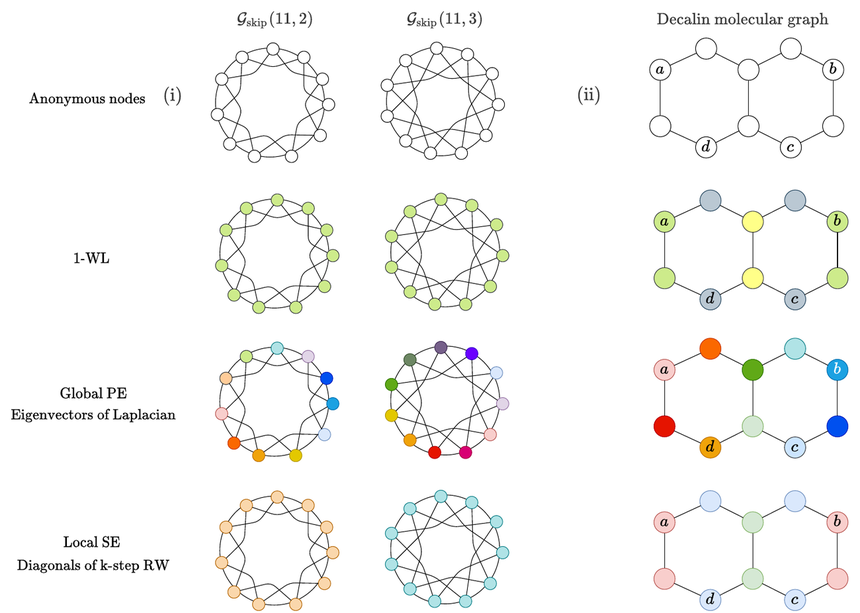

***Why positional and structural encodings help.** Graphs without node features: (i) the circular skip-link graphs $\mathcal{G}_{\text{skip}}(11, 2)$ and $\mathcal{G}_{\text{skip}}(11, 3)$, (ii) the decalin molecule. Each row colours the nodes by a different feature. **1-WL** colours every node of both CSL graphs identically, so it cannot tell the two graphs apart. The **local SE** (diagonals of the $k$-step random-walk matrix, our RWSE) differs between the two graphs (orange vs teal), so a GNN given RWSE can separate them. The **global PE** (Laplacian eigenvectors) goes further and gives individual nodes distinct positions, separating nodes such as $a$ and $b$ in decalin that 1-WL and the SE treat as identical. Source: [Rampášek et al., *Recipe for a General, Powerful, Scalable Graph Transformer*, NeurIPS 2022](https://arxiv.org/abs/2205.12454).*


RWPE of node 0, two triangles: tensor([0.000, 0.500, 0.250, 0.375, 0.312, 0.344])
RWPE of node 0, hexagon:       tensor([0.000, 0.500, 0.000, 0.375, 0.000, 0.344])
GIN + RWPE on star K1,3 vs star K1,4        : distinct
GIN + RWPE on two triangles vs hexagon      : distinct
GIN + RWPE on toy graph vs hexagon + chord  : distinct


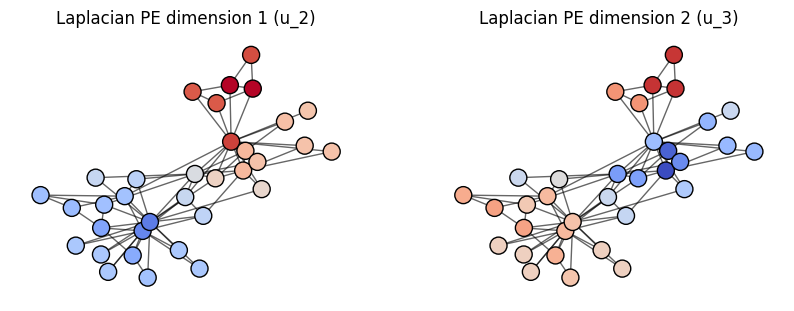

In [45]:
def random_walk_pe(edge_index: torch.Tensor, num_nodes: int, k: int = 8) -> torch.Tensor:
    # Return probabilities diag(RW^1), ..., diag(RW^k) with RW = D^-1 A   ->   (N, k)
    A = edge_index_to_adjacency(edge_index, num_nodes)
    RW = A / A.sum(dim=1, keepdim=True).clamp(min=1)
    M, out = RW.clone(), []
    for _ in range(k):
        out.append(M.diagonal())
        M = M @ RW
    return torch.stack(out, dim=1)


def laplacian_pe(edge_index: torch.Tensor, num_nodes: int, k: int = 4) -> torch.Tensor:
    # The k smoothest non-trivial eigenvectors of L_sym   ->   (N, k), zero-padded for tiny graphs
    _, eigvecs = torch.linalg.eigh(normalized_laplacian(edge_index, num_nodes))
    pe = eigvecs[:, 1:k + 1]
    return F.pad(pe, (0, k - pe.size(1)))


# RWPE on the 1-WL failure case from Part 4
(two_tri, n1), (hexagon, n2) = graph_pairs["two triangles vs hexagon"]
print("RWPE of node 0, two triangles:", random_walk_pe(two_tri, n1, 6)[0])
print("RWPE of node 0, hexagon:      ", random_walk_pe(hexagon, n2, 6)[0])

# Now a GIN that gets RWPE as its input features can tell the pair apart
set_seed(0)
gin_layers = nn.ModuleList([GINConv(gin_mlp(6 if l == 0 else 16, 16)) for l in range(3)])


def gin_with_pe(edge_index, n):
    x = random_walk_pe(edge_index, n, 6)
    for conv in gin_layers:
        x = F.relu(conv(x, edge_index))
    return x.sum(0)


with torch.no_grad():
    for name, (g1, g2) in graph_pairs.items():
        print(f"GIN + RWPE on {name:30s}: {'SAME' if torch.allclose(gin_with_pe(*g1), gin_with_pe(*g2), atol=1e-5) else 'distinct'}")

# Laplacian PE on the karate club: the first coordinate is the Fiedler vector from Part 2
lap = laplacian_pe(karate_edge_index, karate_num_nodes, k=2)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, ax in enumerate(axes):
    lim = lap[:, i].abs().max()
    draw_graph(karate_edge_index, karate_num_nodes, node_color=lap[:, i], ax=ax, pos=karate_pos, labels=False,
               node_size=150, vmin=-lim, vmax=lim, title=f"Laplacian PE dimension {i + 1} (u_{i + 2})")
plt.show()

## A GPS-style Graph Transformer layer

The GPS recipe (Rampášek et al. 2022) runs a **local MPNN** and **global self-attention** in parallel in every layer, adds them, and follows with a feed-forward block, each with a residual connection and normalization:

$$
\begin{aligned}
H_{\text{local}} &= \operatorname{BN}\left(H + \operatorname{MPNN}(H, A)\right) && \text{sees the bonds (here: GIN)} \\
H_{\text{global}} &= \operatorname{BN}\left(H + \operatorname{MHA}(H)\right) && \text{every node attends to every node of its own graph} \\
H' &= \operatorname{BN}\left(\tilde{H} + \operatorname{FFN}(\tilde{H})\right), \qquad \tilde{H} = H_{\text{local}} + H_{\text{global}}
\end{aligned}
$$


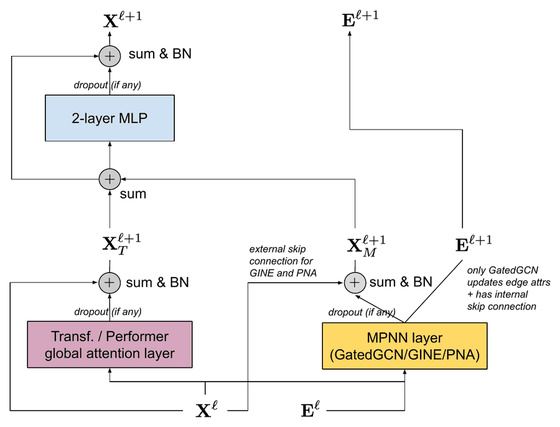

***The GPS layer.** A local MPNN layer (GatedGCN / GINE / PNA in the paper; GIN here) and a global attention layer (Transformer or the linear-time Performer) run in parallel on $X^{\ell}$, each followed by dropout, a residual connection and BatchNorm. Their outputs are summed and passed through a 2-layer MLP with another residual + BatchNorm. Edge features $E^{\ell}$ flow only through the MPNN. Source: [Rampášek et al., *Recipe for a General, Powerful, Scalable Graph Transformer*, NeurIPS 2022](https://arxiv.org/abs/2205.12454).*

The positional/structural encodings are added to the input embeddings, so attention knows the structure, and the MPNN supplies the exact edges, so nothing is lost relative to a GNN.

**Implementation detail: attention needs dense tensors.** Message passing works on our flat "big disconnected graph" batch, but self-attention needs a $(B, n_{\max}, F)$ tensor so that each graph attends only to its own nodes. We convert with `to_dense_batch` (pad every graph to the largest one in the batch and return a mask), run multi-head attention with a **key padding mask** (exactly the masking trick of notebook 09), and gather the real nodes back.

**Cost.** Global attention is $O(n^2)$ per graph. Fine for molecules with 20-50 atoms, impossible for a graph with a million nodes. Scalable graph transformers use sparse or linear attention (Exphormer, NodeFormer, Performer-style kernels).

In [46]:
def to_dense_batch(x: torch.Tensor, batch: torch.Tensor, num_graphs: int):
    # (total_nodes, F) -> (B, n_max, F) padded, plus a (B, n_max) mask that is True for real nodes.
    # Assumes nodes are grouped by graph (which collate_graphs guarantees).
    counts = torch.bincount(batch, minlength=num_graphs)                 # nodes per graph
    starts = torch.cumsum(counts, 0) - counts                            # index of each graph's first node
    position = torch.arange(batch.size(0), device=x.device) - starts[batch]   # position inside its graph
    dense = x.new_zeros(num_graphs, int(counts.max()), x.size(-1))
    dense[batch, position] = x
    mask = torch.zeros(num_graphs, int(counts.max()), dtype=torch.bool, device=x.device)
    mask[batch, position] = True
    return dense, mask


class MultiHeadSelfAttention(nn.Module):
    # Same scaled dot-product attention as notebook 09, with a key padding mask
    def __init__(self, embed_dim: int, num_heads: int, dropout: float = 0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads, self.head_dim = num_heads, embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        B, L, D = x.shape
        # (B, L, D) -> (B, L, 3, H, d) -> (3, B, H, L, d)
        q, k, v = self.qkv(x).view(B, L, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        # Scores: (B, H, L, d) x (B, H, L, d) -> (B, H, L, L)
        scores = torch.einsum("bhid,bhjd->bhij", q, k) / math.sqrt(self.head_dim)
        # Padded nodes must never be attended to: mask the KEY dimension
        scores = scores.masked_fill(~mask[:, None, None, :], float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        # (B, H, L, L) x (B, H, L, d) -> (B, H, L, d) -> (B, L, H * d)
        out = torch.einsum("bhij,bhjd->bhid", attn, v).transpose(1, 2).reshape(B, L, D)
        return self.proj(out)


class GPSLayer(nn.Module):
    def __init__(self, hidden_dim: int, heads: int = 4, dropout: float = 0.5):
        super().__init__()
        self.local = GINConv(nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim)))
        self.attn = MultiHeadSelfAttention(hidden_dim, heads, dropout=0.0)
        self.ffn = nn.Sequential(nn.Linear(hidden_dim, 2 * hidden_dim), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(2 * hidden_dim, hidden_dim))
        self.norm_local, self.norm_attn, self.norm_ffn = (nn.BatchNorm1d(hidden_dim) for _ in range(3))
        self.dropout = dropout

    def forward(self, h, edge_index, batch, num_graphs):
        # Local message passing over the bonds: (N, D) -> (N, D)
        h_local = self.norm_local(h + F.dropout(self.local(h, edge_index), self.dropout, self.training))
        # Global attention inside each graph: (N, D) -> (B, n_max, D) -> attention -> back to (N, D)
        h_dense, mask = to_dense_batch(h, batch, num_graphs)
        h_attn = self.attn(h_dense, mask)[mask]
        h_global = self.norm_attn(h + F.dropout(h_attn, self.dropout, self.training))
        # Combine, then a position-wise feed-forward block
        h = h_local + h_global
        return self.norm_ffn(h + self.ffn(h))


# to_dense_batch round trip, and a quick shape check of the full model
dense, mask = to_dense_batch(example.x, example.batch, example.num_graphs)
print("dense batch:", tuple(dense.shape), " real nodes:", mask.sum().item(), "==", example.x.size(0),
      " round trip ok:", torch.equal(dense[mask], example.x))

dense batch: (4, 19, 7)  real nodes: 62 == 62  round trip ok: True


## Graph Transformer vs GIN on MUTAG

We add an 8-step RWSE to every molecule and compare, with the same 10-fold protocol:

* **GIN** (from Part 7),
* **GIN + RWSE**: the same GIN with the structural encoding added to its input,
* **GPS + RWSE**: the graph transformer (GIN local branch + 4-head global attention).

GCN + mean pool    10-fold accuracy: 0.766 +/- 0.106
GIN + sum pool     10-fold accuracy: 0.858 +/- 0.093
GIN + RWSE         10-fold accuracy: 0.868 +/- 0.088
GPS + RWSE         10-fold accuracy: 0.879 +/- 0.060


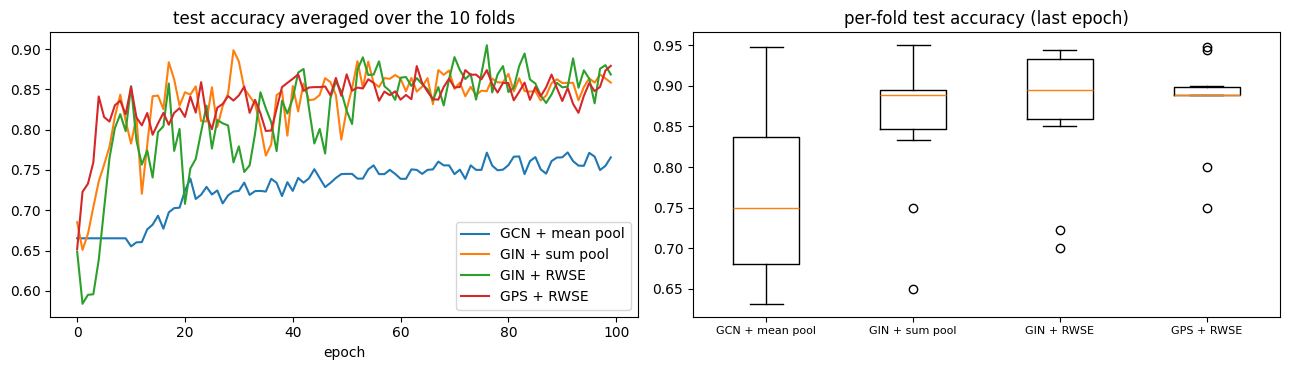

In [47]:
for g in mutag:
    g.pe = random_walk_pe(g.edge_index, g.num_nodes, k=8)

for name, make in {
    "GIN + RWSE": lambda: GraphClassifier("gin", in_dim=7, pe_dim=8),
    "GPS + RWSE": lambda: GraphClassifier("gps", in_dim=7, pe_dim=8, num_layers=3),
}.items():
    graph_results[name], graph_curves[name] = cross_validate(make, mutag)

for name, accs in graph_results.items():
    print(f"{name:18s} 10-fold accuracy: {accs.mean():.3f} +/- {accs.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, curves in graph_curves.items():
    axes[0].plot(curves.mean(0), label=name)
axes[0].set_xlabel("epoch")
axes[0].set_title("test accuracy averaged over the 10 folds")
axes[0].legend()
names = list(graph_results)
axes[1].boxplot([graph_results[n].numpy() for n in names])
axes[1].set_xticks(range(1, len(names) + 1))
axes[1].set_xticklabels(names, fontsize=8)
axes[1].set_title("per-fold test accuracy (last epoch)")
plt.tight_layout()
plt.show()

Each step up the expressivity ladder helps a little:

* **GIN + RWSE** gives GIN cycle information it cannot compute itself. MUTAG molecules are full of 6-rings, and $(RW^6)_{ii}$ is higher for atoms that sit on a ring.
* **GPS + RWSE** lets distant parts of a molecule interact in one layer instead of $K$ hops, and it is also the most consistent model across folds (smallest standard deviation, smoothest learning curve).

But be honest about the scale: the gaps between GIN, GIN + RWSE and GPS (about 1 point each) are much smaller than the fold-to-fold standard deviation (6-9 points). On 188 molecules this is **not** a statistically meaningful ranking. All three are clearly better than GCN + mean pooling. Graph Transformers earn their $O(n^2)$ cost on larger benchmarks where long-range interactions matter and data is plentiful (ZINC, PCQM4Mv2, the Long Range Graph Benchmark).

# Part 10: Summary / cheat sheet

### The one idea

A GNN layer updates every node from the **multiset of its neighbours' states** with **shared, permutation-invariant** functions:

$$
h_i' = \psi\Big(h_i,\; \bigoplus_{j \in \mathcal{N}(i)} \phi(h_i, h_j, e_{ji})\Big)
$$

Equivariant layers + an invariant readout = a model that respects the fact that node IDs are arbitrary.

### The layers we built

| Layer | Update rule | Neighbour weights | Strengths | Weaknesses |
|---|---|---|---|---|
| ChebNet | $\sum_{k=0}^{K} T_k(\tilde{L}) H \Theta_k$ | fixed polynomial of $L$ | $K$-hop filters in one layer, principled | needs $\lambda_{\max}$; superseded by GCN for most uses |
| GCN | $\sigma(\hat{A} H W)$ | $1/\sqrt{\tilde{d}_i\tilde{d}_j}$, fixed | simple, fast, strong on homophilous graphs | low-pass only, over-smooths, mean-like (not WL-powerful) |
| GraphSAGE | $\sigma(W_1 h_i + W_2\, \text{AGG}_j h_j)$ | uniform (mean) or max | separate self weight, neighbour sampling, inductive | mean/max lose multiset information |
| GAT / GATv2 | $\sigma(\sum_j \alpha_{ij} W h_j)$ | learned attention | adaptive weights, multi-head | GAT attention is static; often near-uniform on citation graphs |
| GIN | $\text{MLP}((1+\epsilon)h_i + \sum_j h_j)$ | 1 (sum) | as powerful as 1-WL; best for graph classification | sum is sensitive to degree; still capped at 1-WL |
| Graph Transformer (GPS) | MPNN + global attention + FFN, with PE/SE | dense attention + edges | long range, beyond 1-WL with structural encodings | $O(n^2)$ attention; needs good PEs |

### Complexity (one layer, $N$ nodes, $E$ edges, $F$ features)

* Message passing (GCN/SAGE/GIN): $O(E F + N F^2)$. Linear in the number of edges.
* GAT: the same, times the number of heads.
* Spectral with a full eigendecomposition: $O(N^3)$ once, then $O(N^2 F)$ per layer. Only for small graphs.
* Global attention: $O(N^2 F)$ per graph.

### The key math facts

* $x^\top L x = \sum_{(i,j) \in E}(x_i - x_j)^2$: the Laplacian measures smoothness; its eigenvectors are the graph's Fourier modes and eigenvalues their frequencies.
* Polynomials of $L$ are $K$-hop localized and need no eigendecomposition: the bridge from spectral to spatial GNNs.
* GCN = first-order Chebyshev filter + renormalization trick; $\hat{A}$ has eigenvalues in $(-1, 1]$ and acts as a low-pass filter $1 - \tilde{\lambda}$.
* Over-smoothing: $\hat{A}^K X \rightarrow v_1 v_1^\top X$, every node collapses to $\sqrt{\tilde{d}_i}\, c$.
* Message passing GNNs are at most as powerful as 1-WL; sum aggregation + MLP (GIN) reaches it; positional / structural encodings go beyond it.

### Practical pitfalls

* **Self-loops**: GCN needs them (renormalization trick); GIN must *not* add them (the self term is $(1+\epsilon)h_i$); GAT adds them so a node can attend to itself.
* **Edge direction**: messages flow `edge_index[0] -> edge_index[1]`. For undirected graphs store both directions, or half of the graph silently stops talking.
* **Normalization**: sum aggregation on graphs with hubs can blow up activations; use normalization (BatchNorm/LayerNorm) or mean aggregation.
* **Heterophily**: if neighbours tend to have *different* labels, a low-pass GNN can lose to an MLP. Check the homophily ratio first.
* **Link prediction leakage**: remove validation/test edges from the message passing graph.
* **Small datasets** (MUTAG, most TU datasets): use cross-validation and report the spread; differences of 1-2 points are noise.
* **Depth**: 2-4 message passing layers are usually best. If you need long range, use residuals/jumping knowledge, or global attention, instead of stacking 30 plain layers.